# Fit voxel response to texture features and analyze results

In [14]:
from google.colab import drive
import os
import shutil

# Try to unmount if Colab thinks Drive is mounted
try:
    drive.flush_and_unmount()
except Exception as e:
    print("Unmount note:", e)

# Remove the stale local mount-point directory
if os.path.exists("/content/drive"):
    shutil.rmtree("/content/drive")

# Recreate it empty
os.makedirs("/content/drive", exist_ok=True)

# Mount again
drive.mount("/content/drive", force_remount=True)

print("Drive mounted successfully.")

Mounted at /content/drive
Drive mounted successfully.


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import sys

# Set root and library directory paths
root = Path("/content/drive/MyDrive/V2_drift/")
lib_dir1 = root / "texturemodel"
lib_dir2 = lib_dir1 / "code"
lib_dir3 = lib_dir2 / "utils"
lib_dir4 = Path('/content/drive/MyDrive/V2_drift/texturemodel/code/utils/')
# Add all custom directories to sys.path (avoids shell-level PYTHONPATH edits)
for directory in (lib_dir1, lib_dir2, lib_dir3, lib_dir4):
    dir_str = str(directory.resolve())  # absolute path as string
    if dir_str not in sys.path:
        sys.path.append(dir_str)


In [20]:
!bash /content/drive/MyDrive/V2_drift/texturemodel/code/run/fit_pyramid_prfs.sh

Streaming output truncated to the last 5000 lines.
loaded features
(907,)
(907, 2096)
prf 452: using 907 validation set trials
Getting predictions for voxel batch 0 of 1

Evaluating version 0 of 1: full_model
Includes 54 features
No voxels have this pRF as their best model, skipping it.
No voxels have this pRF as their best model, skipping it.
Getting features for prf 455 of 1456
about to load features
Index into batch for prf 455: 55
Final size of feature matrix for this image set and pRF is:
(907, 53)
loaded features
(907,)
(907, 2096)
prf 455: using 907 validation set trials
Getting predictions for voxel batch 0 of 1

Evaluating version 0 of 1: full_model
Includes 54 features
No voxels have this pRF as their best model, skipping it.
No voxels have this pRF as their best model, skipping it.
Getting features for prf 458 of 1456
about to load features
Index into batch for prf 458: 58
Final size of feature matrix for this image set and pRF is:
(907, 53)
loaded features
(907,)
(907, 2096

In [17]:
import numpy as np

FN = (
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_HendersonGroups_V2_pca95_use_nsd_grid5_pRFs/"
    "Sep-28-2026_1340_19/all_fit_params.npy"
)

d = np.load(FN, allow_pickle=True).item()

print("=" * 100)
print("CONFIGURATION")
print("=" * 100)

for k in [
    "subject",
    "roi_name",
    "pca_pct_var",
    "average_image_reps",
    "zscore_features",
    "ridge",
    "set_lambda_per_group",
    "up_to_sess",
    "use_precomputed_prfs",
    "saved_prfs_fn",
]:
    print(f"{k:25s}: {d.get(k)}")


# ============================================================
# PERFORMANCE
# ============================================================

r2 = np.asarray(d["val_r2"]).squeeze()
cc = np.asarray(d["val_cc"]).squeeze()
ncsnr = np.asarray(d["voxel_ncsnr"]).squeeze()

print("\n" + "=" * 100)
print("RAW FIT")
print("=" * 100)

print("N voxels:", len(r2))
print("Finite R²:", np.isfinite(r2).sum())
print("NaN R²:", np.isnan(r2).sum())

print("\nR²:")
print("mean:  ", np.nanmean(r2))
print("median:", np.nanmedian(r2))
print("% > 0:", 100*np.nanmean(r2 > 0))
print("% > .05:", 100*np.nanmean(r2 > .05))
print("% > .10:", 100*np.nanmean(r2 > .10))

print("\nCorrelation:")
print("mean:  ", np.nanmean(cc))
print("median:", np.nanmedian(cc))

print("\nR² percentiles:")
for p in [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]:
    print(f"p{p:3}: {np.nanpercentile(r2, p): .6f}")


# ============================================================
# HENDERSON NC FILTER
# ============================================================

from utils import nsd_utils

nc = nsd_utils.ncsnr_to_nc(ncsnr)

mask = (
    np.isfinite(r2) &
    np.isfinite(cc) &
    np.isfinite(nc) &
    (nc > 0.01)
)

r2_nc = r2[mask]
cc_nc = cc[mask]

print("\n" + "=" * 100)
print("NC > .01")
print("=" * 100)

print("N kept:", mask.sum(), "/", len(mask))

print("\nR²:")
print("mean:  ", np.mean(r2_nc))
print("median:", np.median(r2_nc))
print("% > 0:", 100*np.mean(r2_nc > 0))
print("% > .05:", 100*np.mean(r2_nc > .05))
print("% > .10:", 100*np.mean(r2_nc > .10))

print("\nCorrelation:")
print("mean:  ", np.mean(cc_nc))
print("median:", np.median(cc_nc))

print("\nR² percentiles:")
for p in [0, 1, 5, 10, 25, 50, 75, 90, 95, 99, 100]:
    print(f"p{p:3}: {np.percentile(r2_nc, p): .6f}")


# ============================================================
# EXTREME NEGATIVE CHECK
# ============================================================

print("\n" + "=" * 100)
print("NEGATIVE R² DIAGNOSTIC")
print("=" * 100)

for threshold in [-100, -10, -5, -2, -1, -.5, -.1, 0]:
    x = r2_nc[r2_nc > threshold]

    print(
        f"R² > {threshold:6}: "
        f"N={len(x):4d}, "
        f"mean={np.mean(x): .4f}, "
        f"median={np.median(x): .4f}"
    )

CONFIGURATION
subject                  : 1
roi_name                 : V2
pca_pct_var              : 95
average_image_reps       : True
zscore_features          : True
ridge                    : False
set_lambda_per_group     : False
up_to_sess               : 30
use_precomputed_prfs     : True
saved_prfs_fn            : /content/drive/MyDrive/V2_drift/prf_indices/subj01_normalized_final_best_prf_indices_V2.npy

RAW FIT
N voxels: 2096
Finite R²: 2096
NaN R²: 0

R²:
mean:   -1.0276028
median: 0.028860915
% > 0: 66.50763358778626
% > .05: 45.41984732824427
% > .10: 34.30343511450381

Correlation:
mean:   0.2162194
median: 0.18642606

R² percentiles:
p  0: -553.406189
p  1: -2.771230
p  5: -0.023099
p 10: -0.013473
p 25: -0.004783
p 50:  0.028861
p 75:  0.140310
p 90:  0.222886
p 95:  0.271696
p 99:  0.353995
p100:  0.448121

NC > .01
N kept: 2033 / 2096

R²:
mean:   -1.059186
median: 0.03484194
% > 0: 68.37186424003934
% > .05: 46.82734874569602
% > .10: 35.36645351697

Correlation:
mean:

In [7]:
import os
import numpy as np
from utils import roi_utils, nsd_utils

# ============================================================
# Finished S08 V1 fit
# ============================================================

fn = (
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S08/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_HendersonGroups_V1_"
    "pca95_use_nsd_grid5_pRFs/"
    "Sep-28-2026_0714_39/all_fit_params.npy"
)

d = np.load(fn, allow_pickle=True).item()

r2 = np.asarray(d["val_r2"]).squeeze()
cc = np.asarray(d["val_cc"]).squeeze()
fit_voxel_index = np.asarray(d["voxel_index"]).squeeze()
ncsnr = np.asarray(d["voxel_ncsnr"]).squeeze()

print("=" * 100)
print("CURRENT FIT")
print("=" * 100)
print("N fitted voxels:", len(fit_voxel_index))


# ============================================================
# Load pRF-only ROI information
# This corresponds to use_kastner_areas=False
# ============================================================

(
    voxel_mask_prf,
    voxel_index_prf,
    voxel_roi_prf,
    voxel_ncsnr_prf,
    brain_shape_prf
) = roi_utils.get_voxel_roi_info(
    subject=8,
    volume_space=True,
    use_kastner_areas=False,
    load_preproc=True
)

voxel_index_prf = np.asarray(voxel_index_prf).squeeze()

# retinotopic labels are first ROI label set
retino_labels_full = np.asarray(voxel_roi_prf[0]).squeeze()

print("full retino labels:", retino_labels_full.shape)
print("voxel_index_prf:", voxel_index_prf.shape)

# Select ROI labels at the 18,388 voxel locations
retino_labels = retino_labels_full[voxel_index_prf]

print("selected retino labels:", retino_labels.shape)

assert len(retino_labels) == len(voxel_index_prf)

print("\n" + "=" * 100)
print("pRF-ONLY ROI DEFINITION")
print("=" * 100)

print("N voxels in pRF-only file:", len(voxel_index_prf))
print("retino labels shape:", retino_labels.shape)


# ============================================================
# Henderson V1 = labels 1 or 2
# ============================================================

is_v1_prf = np.isin(retino_labels, [1, 2])

henderson_v1_indices = voxel_index_prf[is_v1_prf]

print("\npRF-only V1 voxels:", len(henderson_v1_indices))


# ============================================================
# Intersect with voxels actually fitted in our V1 model
# ============================================================

in_henderson_v1 = np.isin(
    fit_voxel_index,
    henderson_v1_indices
)

print("\n" + "=" * 100)
print("OVERLAP WITH CURRENT FIT")
print("=" * 100)

print("Current fitted V1 voxels:     ", len(fit_voxel_index))
print("Henderson pRF-only V1 overlap:", in_henderson_v1.sum())
print(
    "% of current fit retained:   ",
    f"{100 * in_henderson_v1.mean():.2f}%"
)


# ============================================================
# Henderson noise ceiling
# ============================================================

nc = nsd_utils.ncsnr_to_nc(
    ncsnr,
    average_image_reps=True,
    subject=8
)

nc_keep = np.isfinite(nc) & (nc > 0.01)

# Final selection:
# Figure-3 pRF-only V1 AND NC > 0.01 AND finite R²
keep = (
    in_henderson_v1
    & nc_keep
    & np.isfinite(r2)
)

print("\n" + "=" * 100)
print("FINAL HENDERSON-STYLE SELECTION")
print("=" * 100)

print("pRF-only V1 + NC > .01:", keep.sum())


# ============================================================
# Validation performance
# ============================================================

rr = r2[keep]
cc_sel = cc[keep]

print("\n" + "=" * 100)
print("VALIDATION PERFORMANCE")
print("=" * 100)

print(f"N voxels:       {len(rr):,}")
print(f"Mean R²:        {np.mean(rr): .6f}")
print(f"Median R²:      {np.median(rr): .6f}")
print(f"Mean corr:      {np.mean(cc_sel): .6f}")
print(f"Median corr:    {np.median(cc_sel): .6f}")
print(f"% R² > 0:       {100*np.mean(rr > 0): .2f}%")
print(f"% R² > 0.05:    {100*np.mean(rr > .05): .2f}%")
print(f"% R² > 0.10:    {100*np.mean(rr > .10): .2f}%")

print("\nR² percentiles:")
for p in [0, 1, 5, 25, 50, 75, 90, 95, 99, 100]:
    print(f"p{p:>3}: {np.percentile(rr, p): .6f}")


# ============================================================
# Check influence of catastrophic negative values
# Diagnostic only — NOT Henderson's filtering
# ============================================================

print("\n" + "=" * 100)
print("DIAGNOSTIC: EFFECT OF EXTREME NEGATIVE R²")
print("=" * 100)

for lower in [-100, -10, -5, -2, -1, -0.5, -0.1, 0]:
    x = rr[rr > lower]
    print(
        f"R² > {lower:6}: "
        f"N={len(x):4d}, "
        f"mean={np.mean(x): .4f}, "
        f"median={np.median(x): .4f}"
    )

CURRENT FIT
N fitted voxels: 1791
full retino labels: (642720,)
voxel_index_prf: (18388,)
selected retino labels: (18388,)

pRF-ONLY ROI DEFINITION
N voxels in pRF-only file: 18388
retino labels shape: (18388,)

pRF-only V1 voxels: 1074

OVERLAP WITH CURRENT FIT
Current fitted V1 voxels:      1791
Henderson pRF-only V1 overlap: 1074
% of current fit retained:    59.97%

FINAL HENDERSON-STYLE SELECTION
pRF-only V1 + NC > .01: 1014

VALIDATION PERFORMANCE
N voxels:       1,014
Mean R²:        -0.079737
Median R²:       0.069883
Mean corr:       0.277773
Median corr:     0.272636
% R² > 0:        81.66%
% R² > 0.05:     56.11%
% R² > 0.10:     40.63%

R² percentiles:
p  0: -83.218071
p  1: -1.394913
p  5: -0.019401
p 25:  0.010243
p 50:  0.069883
p 75:  0.173951
p 90:  0.268397
p 95:  0.316291
p 99:  0.366565
p100:  0.422089

DIAGNOSTIC: EFFECT OF EXTREME NEGATIVE R²
R² >   -100: N=1014, mean=-0.0797, median= 0.0699
R² >    -10: N=1010, mean= 0.0717, median= 0.0702
R² >     -5: N=1009, me

BASIC CHECK
Maggie voxels: 2096
Aligned: 2096
Maggie pRF range: 0 1444
Aligned pRF range: 0 1441

pRF INDEX AGREEMENT
Exact same pRF: 156/2,096
Exact agreement: 7.44%

First 30:
Maggie : [ 16  17  16  16  16   0 971  17  17  17  17  32  16  16 460  19  18  17
  33  31 590 164 150  18  18  33 396  16  34  18]
Aligned: [ 17  17  18   1   0   0 817  18  18  33  33  33  16  29 356  21  19  17
  33  31 327 967  19  19  17  34   4   0  19  19]

Grid shape: (1456, 3)
Maggie tuple coords match grid: True

SPATIAL DIFFERENCE
CENTER DISTANCE
mean:   0.256761
median: 0.149471
p75:    0.425152
p90:    0.682010
p95:    0.860116
max:    1.434016

SIGMA DIFFERENCE
mean:   0.063340
median: 0.027707
p75:    0.066090
p90:    0.157646
p95:    0.251442
max:    0.980000

COMPONENT AGREEMENT
Same center: 376/2,096 (17.94%)
Same sigma:  593/2,096 (28.29%)
Same full pRF: 156/2,096 (7.44%)


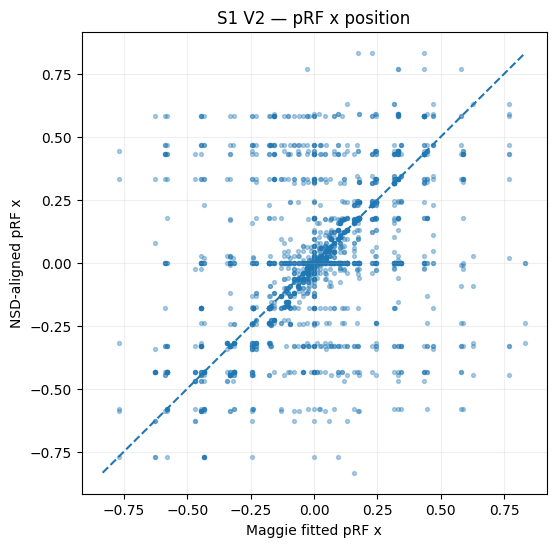

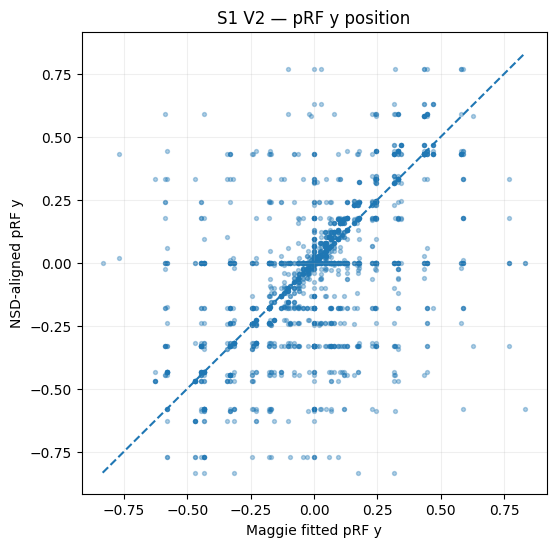

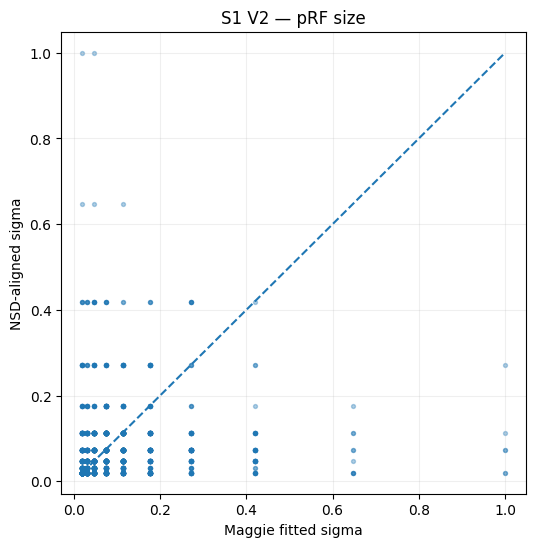

In [13]:
import numpy as np
import matplotlib.pyplot as plt

ROOT = "/content/drive/MyDrive/V2_drift/prf_indices/"

# ============================================================
# LOAD
# ============================================================

maggie = np.load(
    ROOT + "subj01_best_prf_tuples_V2.npy",
    allow_pickle=True
)

aligned = np.load(
    ROOT + "subj01_normalized_final_best_prf_indices_V2.npy",
    allow_pickle=True
).squeeze().astype(int)

maggie_voxel = np.array([row[0] for row in maggie], dtype=int)
maggie_prf   = np.array([row[1] for row in maggie], dtype=int)
maggie_xyz   = np.vstack([row[2].squeeze() for row in maggie])

print("=" * 90)
print("BASIC CHECK")
print("=" * 90)

print("Maggie voxels:", len(maggie_prf))
print("Aligned:", len(aligned))
print("Maggie pRF range:", maggie_prf.min(), maggie_prf.max())
print("Aligned pRF range:", aligned.min(), aligned.max())

assert len(maggie_prf) == len(aligned), (
    "Different number of voxels — do NOT compare row-by-row yet."
)

# ============================================================
# DIRECT INDEX AGREEMENT
# ============================================================

same = maggie_prf == aligned

print("\n" + "=" * 90)
print("pRF INDEX AGREEMENT")
print("=" * 90)

print(f"Exact same pRF: {same.sum():,}/{len(same):,}")
print(f"Exact agreement: {100*same.mean():.2f}%")

print("\nFirst 30:")
print("Maggie :", maggie_prf[:30])
print("Aligned:", aligned[:30])

# ============================================================
# IMPORTANT:
# pRF index numerical difference itself is not a spatial distance.
# Convert both indices back to [x,y,sigma].
# ============================================================

from model_fitting import initialize_fitting

grid = initialize_fitting.get_prf_models(which_grid=5)

print("\nGrid shape:", grid.shape)

assert maggie_prf.max() < len(grid)
assert aligned.max() < len(grid)

maggie_grid_xyz = grid[maggie_prf]
aligned_xyz = grid[aligned]

# sanity check: tuple coordinates should equal grid coordinates
coord_match = np.allclose(
    maggie_xyz,
    maggie_grid_xyz,
    rtol=1e-5,
    atol=1e-7
)

print("Maggie tuple coords match grid:", coord_match)

# ============================================================
# CENTER AND SIZE DIFFERENCES
# ============================================================

center_dist = np.sqrt(
    (maggie_grid_xyz[:,0] - aligned_xyz[:,0])**2 +
    (maggie_grid_xyz[:,1] - aligned_xyz[:,1])**2
)

sigma_diff = np.abs(
    maggie_grid_xyz[:,2] - aligned_xyz[:,2]
)

print("\n" + "=" * 90)
print("SPATIAL DIFFERENCE")
print("=" * 90)

print("CENTER DISTANCE")
print(f"mean:   {center_dist.mean():.6f}")
print(f"median: {np.median(center_dist):.6f}")
print(f"p75:    {np.percentile(center_dist,75):.6f}")
print(f"p90:    {np.percentile(center_dist,90):.6f}")
print(f"p95:    {np.percentile(center_dist,95):.6f}")
print(f"max:    {center_dist.max():.6f}")

print("\nSIGMA DIFFERENCE")
print(f"mean:   {sigma_diff.mean():.6f}")
print(f"median: {np.median(sigma_diff):.6f}")
print(f"p75:    {np.percentile(sigma_diff,75):.6f}")
print(f"p90:    {np.percentile(sigma_diff,90):.6f}")
print(f"p95:    {np.percentile(sigma_diff,95):.6f}")
print(f"max:    {sigma_diff.max():.6f}")

# ============================================================
# HOW MANY HAVE SAME CENTER / SAME SIZE?
# ============================================================

same_center = np.isclose(center_dist, 0)
same_sigma = np.isclose(sigma_diff, 0)

print("\n" + "=" * 90)
print("COMPONENT AGREEMENT")
print("=" * 90)

print(
    f"Same center: "
    f"{same_center.sum():,}/{len(same_center):,} "
    f"({100*same_center.mean():.2f}%)"
)

print(
    f"Same sigma:  "
    f"{same_sigma.sum():,}/{len(same_sigma):,} "
    f"({100*same_sigma.mean():.2f}%)"
)

print(
    f"Same full pRF: "
    f"{same.sum():,}/{len(same):,} "
    f"({100*same.mean():.2f}%)"
)

# ============================================================
# PLOTS
# ============================================================

plt.figure(figsize=(6,6))
plt.scatter(
    maggie_grid_xyz[:,0],
    aligned_xyz[:,0],
    s=8,
    alpha=.35
)
lims = [
    min(maggie_grid_xyz[:,0].min(), aligned_xyz[:,0].min()),
    max(maggie_grid_xyz[:,0].max(), aligned_xyz[:,0].max())
]
plt.plot(lims, lims, "--")
plt.xlabel("Maggie fitted pRF x")
plt.ylabel("NSD-aligned pRF x")
plt.title("S1 V2 — pRF x position")
plt.grid(alpha=.2)
plt.show()


plt.figure(figsize=(6,6))
plt.scatter(
    maggie_grid_xyz[:,1],
    aligned_xyz[:,1],
    s=8,
    alpha=.35
)
lims = [
    min(maggie_grid_xyz[:,1].min(), aligned_xyz[:,1].min()),
    max(maggie_grid_xyz[:,1].max(), aligned_xyz[:,1].max())
]
plt.plot(lims, lims, "--")
plt.xlabel("Maggie fitted pRF y")
plt.ylabel("NSD-aligned pRF y")
plt.title("S1 V2 — pRF y position")
plt.grid(alpha=.2)
plt.show()


plt.figure(figsize=(6,6))
plt.scatter(
    maggie_grid_xyz[:,2],
    aligned_xyz[:,2],
    s=8,
    alpha=.35
)
lims = [
    min(maggie_grid_xyz[:,2].min(), aligned_xyz[:,2].min()),
    max(maggie_grid_xyz[:,2].max(), aligned_xyz[:,2].max())
]
plt.plot(lims, lims, "--")
plt.xlabel("Maggie fitted sigma")
plt.ylabel("NSD-aligned sigma")
plt.title("S1 V2 — pRF size")
plt.grid(alpha=.2)
plt.show()

# Maggie's fits

# check no zscore full data reg

In [ ]:
import numpy as np

fn = (
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/"
    "Aug-23-2026_0856_24/all_fit_params.npy"
)

D = np.load(fn, allow_pickle=True).item()

print("zscore_features:", D["zscore_features"])
print("pca_pct_var:", D["pca_pct_var"])
print("pyr_pca_type:", D["pyr_pca_type"])

W = np.asarray(D["best_params"][1]).squeeze()
x = np.abs(W[np.isfinite(W)])

print("weight shape:", W.shape)
print("median |w|:", np.median(x))
print("p95 |w|:", np.percentile(x, 95))
print("p99 |w|:", np.percentile(x, 99))
print("p99.9 |w|:", np.percentile(x, 99.9))
print("max |w|:", np.max(x))
print("# > 1e3:", np.sum(x > 1e3))
print("# > 1e6:", np.sum(x > 1e6))
print("# > 1e9:", np.sum(x > 1e9))

zscore_features: False
pca_pct_var: 0
pyr_pca_type: pcaHL
weight shape: (2392, 49)
median |w|: 0.1323745
p95 |w|: 58814.65
p99 |w|: 44215468.0
p99.9 |w|: 188977040.0
max |w|: 484253400.0
# > 1e3: 11711
# > 1e6: 2544
# > 1e9: 0


# BUILD GLOBAL FIXED FEATURE Z-SCORE STATS

In [ ]:
# ============================================================
# BUILD GLOBAL FIXED FEATURE Z-SCORE STATS
#
# For all:
#   8 subjects
#   pcaHL thresholds = 0, 40, 60, 80, 95
#
# For each subject × PCA:
#   1. Find the most recent WHOLE-DATA fit.
#   2. Read its saved image_order.
#   3. Load the matching subject-level feature HDF5.
#   4. Compute mean/std separately for:
#         pRF × feature
#      across the SAME images used by the whole-data fit.
#   5. Save one fixed normalization file.
#
# These statistics can later be reused in every V1/V2/V3/hV4
# session-specific fit for that subject/PCA configuration.
#
# No regression is performed here.
# ============================================================

import os
import re
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime


# ============================================================
# CONFIG
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

MODEL_FITS_ROOT = (
    ROOT
    / "texturemodel"
    / "model_fits"
)

FEATURE_ROOT = (
    ROOT
    / "features"
    / "pyramid_texture"
)

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_feature_zscore"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


SUBJECTS = list(
    range(1, 9)
)

PCA_THRESHOLDS = [
    0,
    95,
]

PCA_TYPE = "pcaHL"

N_ORI = 4
N_SF = 4
PRF_GRID = 5

EPS = 1e-6

# Process pRFs one at a time to keep RAM low.
VERBOSE_EVERY = 100


# ============================================================
# HELPER:
# parse timestamp folder
# ============================================================

def parse_timestamp(name):

    try:
        return datetime.strptime(
            name,
            "%b-%d-%Y_%H%M_%S"
        )

    except Exception:
        return None


# ============================================================
# HELPER:
# find newest matching whole-data fit
#
# We only need ONE ROI's fit to obtain image_order because
# image_order is subject-level for that whole-data fitting run.
#
# Prefer V1 because it is consistently present.
# ============================================================

def find_latest_whole_fit(
    subject,
    pca_pct,
    roi="V1"
):

    subject_dir = (
        MODEL_FITS_ROOT
        / f"S{subject:02d}"
    )

    model_folder = (
        subject_dir
        / (
            f"texture_pyramid_OLS_"
            f"{N_ORI}ori_{N_SF}sf_"
            f"{PCA_TYPE}_{roi}_"
            f"pca{pca_pct}_"
            f"use_nsd_grid{PRF_GRID}_pRFs"
        )
    )

    if not model_folder.exists():

        return None


    candidates = []

    for timing_dir in model_folder.iterdir():

        if not timing_dir.is_dir():
            continue

        fit_file = (
            timing_dir
            / "all_fit_params.npy"
        )

        if not fit_file.exists():
            continue

        dt = parse_timestamp(
            timing_dir.name
        )

        candidates.append(
            (
                dt,
                timing_dir.name,
                fit_file
            )
        )


    if len(candidates) == 0:

        return None


    # Prefer timestamp-parsable folders.
    valid = [
        x
        for x in candidates
        if x[0] is not None
    ]

    if len(valid) > 0:

        valid.sort(
            key=lambda x: x[0]
        )

        return valid[-1][2]


    # Fallback: filesystem modification time.
    candidates.sort(
        key=lambda x:
            os.path.getmtime(
                x[2]
            )
    )

    return candidates[-1][2]


# ============================================================
# HELPER:
# feature file path
# ============================================================

def get_feature_file(
    subject,
    pca_pct
):

    return (
        FEATURE_ROOT
        / f"PCA_{PCA_TYPE}_v{pca_pct}"
        / (
            f"S{subject}_"
            f"{N_ORI}ori_{N_SF}sf_"
            f"{PCA_TYPE}_concat_"
            f"v{pca_pct}pct_"
            f"grid{PRF_GRID}.h5py"
        )
    )


# ============================================================
# HELPER:
# label file path
# ============================================================

def get_label_file(
    subject,
    pca_pct
):

    return (
        FEATURE_ROOT
        / f"PCA_{PCA_TYPE}_v{pca_pct}"
        / (
            f"S{subject}_"
            f"{N_ORI}ori_{N_SF}sf_"
            f"featurelabels_"
            f"{PCA_TYPE}_"
            f"v{pca_pct}pct_"
            f"grid{PRF_GRID}.npy"
        )
    )


# ============================================================
# HELPER:
# output path
# ============================================================

def get_output_file(
    subject,
    pca_pct
):

    return (
        OUT_DIR
        / (
            f"S{subject:02d}_"
            f"{PCA_TYPE}{pca_pct}_"
            f"{N_ORI}ori_{N_SF}sf_"
            f"grid{PRF_GRID}_"
            f"wholedata_fixed_mean_std.npz"
        )
    )


# ============================================================
# HELPER:
# get unique image indices used by whole-data fit
#
# IMPORTANT:
# image_order may contain repeated image IDs because NSD
# contains repeated presentations.
#
# We DO NOT remove duplicates here.
#
# The encoding model computes its normalization across the
# rows passed into the fit. If an image appeared multiple times,
# its feature row contributes multiple times to the mean/std.
# ============================================================

def clean_image_order(
    image_order,
    n_images_in_feature_file
):

    image_order = np.asarray(
        image_order
    ).astype(int).reshape(-1)

    valid = (
        (image_order >= 0)
        &
        (image_order < n_images_in_feature_file)
    )

    image_order = image_order[
        valid
    ]

    return image_order


# ============================================================
# MAIN
# ============================================================

summary_rows = []


for subject in SUBJECTS:

    for pca_pct in PCA_THRESHOLDS:

        print(
            "\n"
            +
            "=" * 110
        )

        print(
            f"S{subject:02d} | "
            f"{PCA_TYPE}{pca_pct}"
        )

        print(
            "=" * 110
        )


        # ----------------------------------------------------
        # Find whole-data fit
        # ----------------------------------------------------

        fit_file = find_latest_whole_fit(
            subject,
            pca_pct,
            roi="V1"
        )


        if fit_file is None:

            print(
                "✗ No matching whole-data V1 fit found."
            )

            summary_rows.append({
                "subject":
                    subject,

                "pca_pct":
                    pca_pct,

                "status":
                    "NO_WHOLE_FIT",
            })

            continue


        print(
            "Whole-data fit:"
        )

        print(
            fit_file
        )


        # ----------------------------------------------------
        # Load whole-data metadata
        # ----------------------------------------------------

        D = np.load(
            fit_file,
            allow_pickle=True
        ).item()


        print(
            "Saved zscore_features:",
            D.get(
                "zscore_features",
                None
            )
        )

        print(
            "Saved pca_pct_var:",
            D.get(
                "pca_pct_var",
                None
            )
        )

        print(
            "Saved pyr_pca_type:",
            D.get(
                "pyr_pca_type",
                None
            )
        )


        if "image_order" not in D:

            print(
                "✗ No image_order saved in fit."
            )

            summary_rows.append({
                "subject":
                    subject,

                "pca_pct":
                    pca_pct,

                "status":
                    "NO_IMAGE_ORDER",
            })

            continue


        raw_image_order = np.asarray(
            D["image_order"]
        )


        print(
            "Raw saved image_order shape:",
            raw_image_order.shape
        )


        # ----------------------------------------------------
        # Feature file
        # ----------------------------------------------------

        feature_file = get_feature_file(
            subject,
            pca_pct
        )


        if not feature_file.exists():

            print(
                "✗ Feature file missing:"
            )

            print(
                feature_file
            )

            summary_rows.append({
                "subject":
                    subject,

                "pca_pct":
                    pca_pct,

                "status":
                    "NO_FEATURE_FILE",
            })

            continue


        print(
            "Feature file:"
        )

        print(
            feature_file
        )


        # ----------------------------------------------------
        # Inspect dimensions
        # ----------------------------------------------------

        with h5py.File(
            feature_file,
            "r"
        ) as f:

            if "features" not in f:

                raise KeyError(
                    f"'features' dataset missing in "
                    f"{feature_file}"
                )

            dset = f["features"]

            n_images, n_features, n_prfs = (
                dset.shape
            )


        print(
            "Feature matrix shape:",
            (
                n_images,
                n_features,
                n_prfs
            )
        )


        # ----------------------------------------------------
        # Clean image order
        # ----------------------------------------------------

        image_order = clean_image_order(
            raw_image_order,
            n_images
        )


        print(
            "Number of feature rows used for global stats:",
            len(
                image_order
            )
        )

        print(
            "Number of unique image IDs:",
            len(
                np.unique(
                    image_order
                )
            )
        )


        if len(
            image_order
        ) == 0:

            print(
                "✗ No valid image indices."
            )

            summary_rows.append({
                "subject":
                    subject,

                "pca_pct":
                    pca_pct,

                "status":
                    "NO_VALID_IMAGES",
            })

            continue


        # ----------------------------------------------------
        # Allocate
        # ----------------------------------------------------

        features_mean = np.full(
            (
                n_prfs,
                n_features
            ),
            np.nan,
            dtype=np.float32
        )

        features_std = np.full(
            (
                n_prfs,
                n_features
            ),
            np.nan,
            dtype=np.float32
        )


        # ----------------------------------------------------
        # Compute mean/std
        #
        # LOW-RAM:
        # one pRF at a time
        # ----------------------------------------------------

        with h5py.File(
            feature_file,
            "r"
        ) as f:

            dset = f["features"]


            for prf in range(
                n_prfs
            ):

                if (
                    prf % VERBOSE_EVERY
                    ==
                    0
                ):

                    print(
                        f"  pRF "
                        f"{prf:4d}/"
                        f"{n_prfs}"
                    )


                # --------------------------------------------
                # h5py advanced indexing requires sorted
                # indices in many cases.
                #
                # Because image_order can contain repetitions,
                # loading rows individually is safest but slow.
                #
                # More efficient approach:
                #   load unique image IDs once,
                #   then reconstruct repetitions using inverse.
                # --------------------------------------------

                unique_imgs, inverse = (
                    np.unique(
                        image_order,
                        return_inverse=True
                    )
                )


                arr_unique = np.asarray(
                    dset[
                        unique_imgs,
                        :,
                        prf
                    ],
                    dtype=np.float64
                )


                # Restore the exact presentation sequence,
                # including repeated image IDs.
                arr = arr_unique[
                    inverse
                ]


                # --------------------------------------------
                # Match model behavior:
                # mean/std feature-wise across image rows.
                #
                # nan-aware because undefined columns may occur.
                # --------------------------------------------

                mu = np.nanmean(
                    arr,
                    axis=0
                )


                sd = np.nanstd(
                    arr,
                    axis=0
                )


                features_mean[
                    prf,
                    :
                ] = mu.astype(
                    np.float32
                )


                features_std[
                    prf,
                    :
                ] = (
                    sd
                    +
                    EPS
                ).astype(
                    np.float32
                )


                del arr
                del arr_unique


        # ----------------------------------------------------
        # Labels
        # ----------------------------------------------------

        label_file = get_label_file(
            subject,
            pca_pct
        )


        if label_file.exists():

            labels = np.load(
                label_file,
                allow_pickle=True
            ).item()


            feature_column_labels = np.asarray(
                labels[
                    "feature_column_labels"
                ]
            )


            feature_type_names = np.asarray(
                labels[
                    "feature_type_names"
                ]
            )


        else:

            feature_column_labels = None
            feature_type_names = None


        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        out_file = get_output_file(
            subject,
            pca_pct
        )


        save_dict = {

            "features_mean":
                features_mean,

            "features_std":
                features_std,

            "epsilon":
                np.asarray(
                    EPS,
                    dtype=np.float32
                ),

            "subject":
                np.asarray(
                    subject
                ),

            "pca_type":
                np.asarray(
                    PCA_TYPE
                ),

            "pca_pct":
                np.asarray(
                    pca_pct
                ),

            "n_ori":
                np.asarray(
                    N_ORI
                ),

            "n_sf":
                np.asarray(
                    N_SF
                ),

            "prf_grid":
                np.asarray(
                    PRF_GRID
                ),

            "image_order":
                image_order.astype(
                    np.int32
                ),

            "n_rows_used":
                np.asarray(
                    len(
                        image_order
                    )
                ),

            "n_unique_images":
                np.asarray(
                    len(
                        np.unique(
                            image_order
                        )
                    )
                ),

            "source_fit_file":
                np.asarray(
                    str(
                        fit_file
                    )
                ),

            "source_feature_file":
                np.asarray(
                    str(
                        feature_file
                    )
                ),

            "source_zscore_features":
                np.asarray(
                    D.get(
                        "zscore_features",
                        None
                    )
                ),
        }


        if feature_column_labels is not None:

            save_dict[
                "feature_column_labels"
            ] = feature_column_labels


        if feature_type_names is not None:

            save_dict[
                "feature_type_names"
            ] = feature_type_names


        np.savez(
            out_file,
            **save_dict
        )


        # ----------------------------------------------------
        # Sanity checks
        # ----------------------------------------------------

        finite_mean = np.mean(
            np.isfinite(
                features_mean
            )
        )


        finite_std = np.mean(
            np.isfinite(
                features_std
            )
        )


        positive_std = np.mean(
            features_std[
                np.isfinite(
                    features_std
                )
            ]
            >
            0
        )


        print(
            "\nSaved:"
        )

        print(
            out_file
        )

        print(
            "features_mean shape:",
            features_mean.shape
        )

        print(
            "features_std shape:",
            features_std.shape
        )

        print(
            "finite mean fraction:",
            finite_mean
        )

        print(
            "finite std fraction:",
            finite_std
        )

        print(
            "positive std fraction:",
            positive_std
        )


        summary_rows.append({

            "subject":
                subject,

            "pca_pct":
                pca_pct,

            "n_features":
                n_features,

            "n_prfs":
                n_prfs,

            "n_rows_used":
                len(
                    image_order
                ),

            "n_unique_images":
                len(
                    np.unique(
                        image_order
                    )
                ),

            "source_zscore_features":
                D.get(
                    "zscore_features",
                    None
                ),

            "finite_mean_fraction":
                finite_mean,

            "finite_std_fraction":
                finite_std,

            "status":
                "SAVED",

            "output_file":
                str(
                    out_file
                ),
        })


# ============================================================
# FINAL SUMMARY
# ============================================================

summary_df = pd.DataFrame(
    summary_rows
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "GLOBAL FEATURE Z-SCORE BUILD SUMMARY"
)

print(
    "=" * 110
)


display(
    summary_df
)


summary_csv = (
    OUT_DIR
    / "global_feature_zscore_build_summary.csv"
)


summary_df.to_csv(
    summary_csv,
    index=False
)


print(
    "\nSaved summary:"
)

print(
    summary_csv
)


S01 | pcaHL0
Whole-data fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Aug-23-2026_0856_24/all_fit_params.npy
Saved zscore_features: False
Saved pca_pct_var: 0
Saved pyr_pca_type: pcaHL
Raw saved image_order shape: (9209,)
Feature file:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Feature matrix shape: (10000, 49, 1456)
Number of feature rows used for global stats: 9209
Number of unique image IDs: 9209
  pRF    0/1456
  pRF  100/1456
  pRF  200/1456
  pRF  300/1456
  pRF  400/1456
  pRF  500/1456
  pRF  600/1456
  pRF  700/1456
  pRF  800/1456
  pRF  900/1456
  pRF 1000/1456
  pRF 1100/1456
  pRF 1200/1456
  pRF 1300/1456
  pRF 1400/1456

Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_feature_zscore/S01_pcaHL0_4ori_4sf_grid5_wholedata_fixed_mean_std.npz
features_mean shape: (1456, 49)
features_std shape: (1456, 49)

/tmp/ipykernel_2789/3310440809.py:663: RuntimeWarning: Mean of empty slice
  mu = np.nanmean(
/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


  pRF  100/1456
  pRF  200/1456
  pRF  300/1456
  pRF  400/1456
  pRF  500/1456
  pRF  600/1456
  pRF  700/1456
  pRF  800/1456
  pRF  900/1456
  pRF 1000/1456
  pRF 1100/1456
  pRF 1200/1456
  pRF 1300/1456
  pRF 1400/1456

Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_feature_zscore/S01_pcaHL95_4ori_4sf_grid5_wholedata_fixed_mean_std.npz
features_mean shape: (1456, 54)
features_std shape: (1456, 54)
finite mean fraction: 0.940501628001628
finite std fraction: 0.940501628001628
positive std fraction: 1.0

S02 | pcaHL0
Whole-data fit:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S02/texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs/Jul-16-2026_0747_43/all_fit_params.npy
Saved zscore_features: True
Saved pca_pct_var: 0
Saved pyr_pca_type: pcaHL
Raw saved image_order shape: (9209,)
Feature file:
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S2_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Feature matrix shape: (10000, 49,

,subject,pca_pct,n_features,n_prfs,n_rows_used,n_unique_images,source_zscore_features,finite_mean_fraction,finite_std_fraction,status,output_file
0,1,0,49,1456,9209,9209,False,1.000000,1.000000,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
1,1,95,54,1456,9209,9209,True,0.940502,0.940502,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
2,2,0,49,1456,9209,9209,True,1.000000,1.000000,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
3,2,95,54,1456,9209,9209,True,0.940044,0.940044,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
4,3,0,49,1456,9209,9209,True,1.000000,1.000000,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
5,3,95,54,1456,9209,9209,True,0.939980,0.939980,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
6,4,0,49,1456,9209,9209,True,1.000000,1.000000,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
7,4,95,54,1456,9209,9209,True,0.940146,0.940146,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
8,5,0,49,1456,9209,9209,True,1.000000,1.000000,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...
9,5,95,54,1456,9209,9209,True,0.940133,0.940133,SAVED,/content/drive/MyDrive/V2_drift/texturemodel/d...



Saved summary:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_feature_zscore/global_feature_zscore_build_summary.csv


# FIXED-GLOBAL FEATURE STANDARDIZATION TEST


Streaming output truncated to the last 5000 lines.
Processing prf 499 of 1456
Index into batch for prf 499: 99
Final size of feature matrix for this image set and pRF is:
(1500, 49)
Hello there,  (750, 1350)
prf 499 - using 750 training trials and 750 held-out trials

Fitting version 0 of 1: full_model, 

Processing prf 500 of 1456
Loading pre-computed features for models [500 - 599] from /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Took 0.92671 seconds to load file
Size of features array for this image set and batch is:
(1500, 49, 100)
Number of nans in each prf this batch:
[np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0),

,metric,RAW,GLOBAL_FIXED_Z
0,Median |weight|,2.693456e+02,5.785441e+01
1,P95 |weight|,3.170230e+08,6.327356e+03
2,P99 |weight|,1.569686e+11,1.729764e+05
3,P99.9 |weight|,7.090103e+11,7.288798e+05
4,Maximum |weight|,3.078454e+12,3.078796e+06
5,# |weight| > 1e3,2.478500e+04,7.649000e+03
6,# |weight| > 1e6,7.667000e+03,3.600000e+01
7,# |weight| > 1e9,2.515000e+03,0.000000e+00
8,Same-session median R2,1.868336e-01,1.868336e-01
9,Same-session median Pearson,4.322425e-01,4.322425e-01



PREDICTION DIFFERENCE
Median ΔR2: -7.880918140301674e-12
Median ΔPearson: -1.1802184229914303e-11


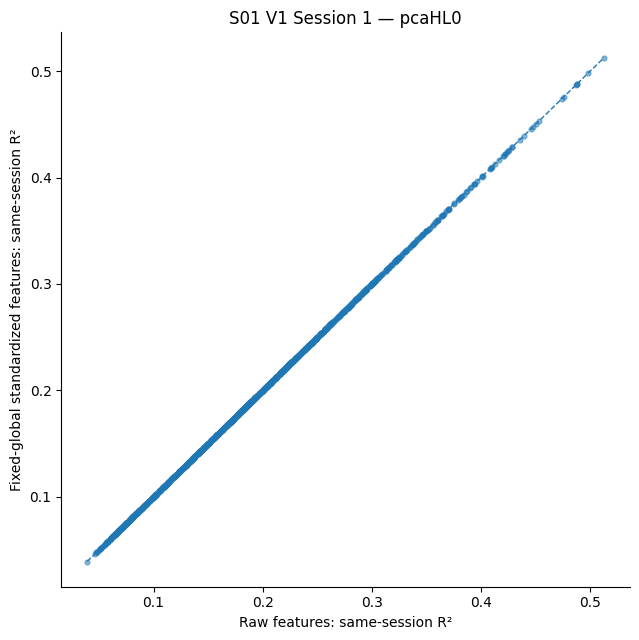


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/S01_V1_session01_pcaHL0_raw_vs_globalZ_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/S01_V1_session01_pcaHL0_raw_vs_globalZ_voxels.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/S01_V1_session01_pcaHL0_raw_vs_globalZ_R2.png


In [ ]:
# ============================================================
# S01 V1 SESSION-1
# FIXED-GLOBAL FEATURE STANDARDIZATION TEST
#
# Compare:
#
#   RAW session fit:
#       X = raw pcaHL0 features
#
#   GLOBAL-Z session fit:
#       X = (X - whole_data_mean) / whole_data_std
#
# IMPORTANT:
#   - same Session 1
#   - same 750 trials
#   - same voxels
#   - same fixed pRFs
#   - same OLS
#   - no ridge
#   - no beta normalization change
#
# Only feature scaling changes.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import sys
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ============================================================
# PROJECT PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

TEXTURE_ROOT = ROOT / "texturemodel"
CODE_ROOT = TEXTURE_ROOT / "code"
MODEL_FITTING_ROOT = CODE_ROOT / "model_fitting"
UTILS_ROOT = CODE_ROOT / "utils"

# Same path convention that worked in the earlier
# fit-equivalence diagnostic.
for p in [
    TEXTURE_ROOT,
    CODE_ROOT,
    MODEL_FITTING_ROOT,
    UTILS_ROOT,
]:
    p = str(p)

    if p not in sys.path:
        sys.path.insert(0, p)


# ============================================================
# PROJECT IMPORTS
# ============================================================

from utils import nsd_utils

import arg_parser as project_arg_parser
import initialize_fitting
import fwrf_model
import fit_cross_session_matrix_fast as fast


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1
ROI = "V1"

# Session 1 = Python index 0
SESSION_INDEX = 0

PCA_TYPE = "pcaHL"
PCA_PCT = 0

# Global fixed normalization file that you just created.
GLOBAL_STATS_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_feature_zscore"
    / (
        "S01_pcaHL0_4ori_4sf_grid5_"
        "wholedata_fixed_mean_std.npz"
    )
)

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_zscore_diagnostic"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert GLOBAL_STATS_FILE.exists(), GLOBAL_STATS_FILE


# ============================================================
# BUILD EXACT FAST CONFIGURATION
#
# IMPORTANT:
# zscore_features = 0 here.
#
# We will standardize in the wrapper ourselves.
# If we set this to 1, the encoding model would z-score again.
# ============================================================

def build_args():

    old_argv = sys.argv.copy()

    sys.argv = [
        "global_zscore_test",

        "--subject", str(SUBJECT),
        "--roi_name", ROI,

        "--debug", "0",

        "--single_sess", str(SESSION_INDEX),
        "--single_val_sess", "-1",

        "--up_to_sess", "30",

        "--whole_session_split", "1",
        "--average_image_reps", "0",

        "--sample_batch_size", "1000",
        "--voxel_batch_size", "1000",

        "--zscore_features", "0",
        "--zscore_betas_within_sess", "0",

        "--use_precomputed_prfs", "1",
        "--prfs_model_name", "nsd_grid5",
        "--which_prf_grid", "5",

        "--fitting_type", "texture_pyramid",

        "--n_ori_pyr", "4",
        "--n_sf_pyr", "4",

        "--group_all_hl_feats", "1",

        "--pyr_pca_type", PCA_TYPE,
        "--pca_pct_var", str(PCA_PCT),

        "--set_lambda_per_group", "0",
        "--ridge", "0",

        "--do_val", "1",
        "--do_corrcoef", "1",

        "--do_tuning", "0",
        "--do_sem_disc", "0",
        "--do_pyr_varpart", "0",

        "--trial_subset", "all",
    ]

    try:
        args = project_arg_parser.get_args()

    finally:
        sys.argv = old_argv

    return args


args = build_args()


# ============================================================
# LOAD GLOBAL FIXED MEAN / STD
# ============================================================

G = np.load(
    GLOBAL_STATS_FILE,
    allow_pickle=True
)

GLOBAL_MEAN = np.asarray(
    G["features_mean"],
    dtype=np.float64
)

GLOBAL_STD = np.asarray(
    G["features_std"],
    dtype=np.float64
)


print("=" * 100)
print("GLOBAL NORMALIZATION")
print("=" * 100)

print(
    "File:",
    GLOBAL_STATS_FILE
)

print(
    "Mean shape:",
    GLOBAL_MEAN.shape
)

print(
    "Std shape:",
    GLOBAL_STD.shape
)

print(
    "Finite mean:",
    np.mean(
        np.isfinite(GLOBAL_MEAN)
    )
)

print(
    "Finite std:",
    np.mean(
        np.isfinite(GLOBAL_STD)
    )
)

print(
    "Positive finite std:",
    np.all(
        GLOBAL_STD[
            np.isfinite(GLOBAL_STD)
        ] > 0
    )
)


assert GLOBAL_MEAN.shape == (
    1456,
    49
)

assert GLOBAL_STD.shape == (
    1456,
    49
)

assert np.all(
    np.isfinite(
        GLOBAL_MEAN
    )
)

assert np.all(
    np.isfinite(
        GLOBAL_STD
    )
)

assert np.all(
    GLOBAL_STD > 0
)


# ============================================================
# ROI METADATA
# SAME ROI DEFINITION AS FAST
# ============================================================

(
    voxel_mask,
    voxel_index,
    voxel_roi,
    voxel_ncsnr,
    brain_nii_shape,
) = fast.load_roi_metadata(
    args
)


NVOX = voxel_index.shape[1]


print("\n" + "=" * 100)
print("ROI")
print("=" * 100)

print("Subject:", SUBJECT)
print("ROI:", ROI)
print("N voxels:", NVOX)


# ============================================================
# LOAD SESSION 1
# ============================================================

(
    voxel_data,
    image_order,
    val_inds,
    holdout_inds,
    session_inds,
) = nsd_utils.get_data_splits_single_train(

    SUBJECT,

    sessions=np.asarray(
        [SESSION_INDEX],
        dtype=int
    ),

    voxel_mask=voxel_mask,

    volume_space=
        args.volume_space,

    zscore_betas_within_sess=
        args.zscore_betas_within_sess,

    shuffle_images=
        args.shuffle_images_once,

    average_image_reps=
        args.average_image_reps,

    random_voxel_data=
        args.random_voxel_data,
)


voxel_data = np.asarray(
    voxel_data,
    dtype=np.float32
)

image_order = np.asarray(
    image_order,
    dtype=int
).reshape(-1)


print("\n" + "=" * 100)
print("SESSION DATA")
print("=" * 100)

print(
    "Trials:",
    len(image_order)
)

print(
    "Voxel data:",
    voxel_data.shape
)

print(
    "First image indices:",
    image_order[:10]
)


assert voxel_data.shape == (
    len(image_order),
    NVOX
)


# ============================================================
# FIXED pRFs
# ============================================================

best_prf, saved_prfs_fn = (
    initialize_fitting
    .load_precomputed_prfs(
        SUBJECT,
        args
    )
)

best_prf = np.asarray(
    best_prf,
    dtype=int
).reshape(-1)


# Same visual-ROI subset operation as FAST.
if len(best_prf) != NVOX:

    best_prf = (
        fast
        .subset_kastner_prfs_to_visualroi(

            args=args,

            best_model_each_voxel=
                best_prf,

            visualroi_voxel_index=
                voxel_index,
        )
    )


assert len(best_prf) == NVOX


print("\n" + "=" * 100)
print("pRF")
print("=" * 100)

print(
    "Fixed pRFs:",
    len(best_prf)
)

print(
    "Occupied pRFs:",
    len(
        np.unique(
            best_prf
        )
    )
)

print(
    "Source:",
    saved_prfs_fn
)


# ============================================================
# MODEL CONFIG
# ============================================================

model_name, fitting_types = (
    initialize_fitting
    .get_full_save_name(
        args
    )
)

# ------------------------------------------------------------
# OLS:
# Keep two zero entries.
#
# The project's list_all_combs utility has a singleton-lambda
# edge case: a one-element array can become 0-D internally.
#
# Two identical zeros are safe because fwrf_model later removes
# duplicate lambda vectors. This therefore remains pure OLS.
# ------------------------------------------------------------

lambdas = np.asarray(
    [0.0, 0.0],
    dtype=np.float32
)

print("\n" + "=" * 100)
print("MODEL")
print("=" * 100)

print(
    "Model:",
    model_name
)

print(
    "Lambdas passed to encoding_model:",
    lambdas
)

print(
    "Lambda shape:",
    lambdas.shape
)

assert lambdas.ndim == 1
assert len(lambdas) == 2
assert np.allclose(
    lambdas,
    0
)


# ============================================================
# GLOBAL NORMALIZATION FEATURE-LOADER WRAPPER
#
# Underlying loader returns:
#
#    feat:
#        images × features_defined_for_this_pRF
#
#    defined:
#        boolean mask over max_features
#
# We use the matching global mean/std for this pRF and these
# defined feature columns.
#
# Crucially:
#
#   SAME mean/std are used irrespective of session.
# ============================================================

class GlobalStandardizedFeatureLoader:

    def __init__(
        self,
        base_loader,
        global_mean,
        global_std,
    ):

        self.base_loader = (
            base_loader
        )

        self.global_mean = np.asarray(
            global_mean,
            dtype=np.float64
        )

        self.global_std = np.asarray(
            global_std,
            dtype=np.float64
        )


    # Forward attributes expected by encoding_model.
    def __getattr__(
        self,
        name
    ):

        return getattr(
            self.base_loader,
            name
        )


    def load(
        self,
        image_inds,
        prf_model_index
    ):

        feat, defined = (
            self.base_loader.load(

                image_inds,

                prf_model_index=
                    prf_model_index,
            )
        )


        feat = np.asarray(
            feat,
            dtype=np.float64
        )


        defined = np.asarray(
            defined,
            dtype=bool
        )


        prf = int(
            prf_model_index
        )


        # ----------------------------------------------------
        # Loader normally returns only currently defined
        # columns. Select the corresponding global statistics.
        # ----------------------------------------------------

        mu = self.global_mean[
            prf,
            defined
        ]

        sd = self.global_std[
            prf,
            defined
        ]


        if feat.shape[1] != len(mu):

            raise RuntimeError(
                f"Feature/stat mismatch for pRF {prf}: "
                f"feat={feat.shape}, "
                f"mu={mu.shape}, "
                f"defined={np.sum(defined)}"
            )


        if not np.all(
            np.isfinite(mu)
        ):

            raise RuntimeError(
                f"Nonfinite global mean "
                f"for pRF {prf}"
            )


        if not np.all(
            np.isfinite(sd)
        ):

            raise RuntimeError(
                f"Nonfinite global std "
                f"for pRF {prf}"
            )


        if np.any(
            sd <= 0
        ):

            raise RuntimeError(
                f"Non-positive global std "
                f"for pRF {prf}"
            )


        # ----------------------------------------------------
        # FIXED GLOBAL STANDARDIZATION
        # ----------------------------------------------------

        feat = (
            feat
            -
            mu[
                None,
                :
            ]
        ) / (
            sd[
                None,
                :
            ]
        )


        return (
            feat.astype(
                np.float32
            ),
            defined,
        )


    def clear_big_features(
        self
    ):

        return (
            self.base_loader
            .clear_big_features()
        )


# ============================================================
# FIT HELPER
# ============================================================

def fit_session(
    use_global_standardization
):

    base_loader = (
        initialize_fitting
        .make_feature_loaders(

            args,

            fitting_types,

            vi=0,

            dnn_layers_use=None,
        )
    )


    if use_global_standardization:

        feature_loader = (
            GlobalStandardizedFeatureLoader(

                base_loader,
                GLOBAL_MEAN,
                GLOBAL_STD,
            )
        )

        label = (
            "GLOBAL FIXED Z-SCORE"
        )

    else:

        feature_loader = (
            base_loader
        )

        label = (
            "RAW FEATURES"
        )


    print(
        "\n"
        +
        "#" * 100
    )

    print(
        label
    )

    print(
        "#" * 100
    )


    model = (
        fwrf_model
        .encoding_model(

            feature_loader,

            lambdas=
                lambdas,

            best_model_each_voxel=
                best_prf,

            # CRITICAL:
            # false because global normalization is already
            # performed inside our wrapper.
            zscore=False,

            add_bias=True,

            set_lambda_per_group=False,

            voxel_batch_size=
                args.voxel_batch_size,

            sample_batch_size=
                args.sample_batch_size,

            device=
                "cpu:0",

            prfs_fit_mask=None,

            shuffle_data=False,

            bootstrap_data=False,

            do_corrcoef=True,

            dtype=np.float32,

            debug=False,
        )
    )


    # --------------------------------------------------------
    # SAME FAST FIT:
    #
    # all Session-1 trials are used for fitting.
    #
    # The same rows are passed as holdout, as in your FAST
    # pipeline with fixed pRFs / OLS.
    # --------------------------------------------------------

    model.fit(

        image_order,
        voxel_data,

        image_order,
        voxel_data,

        trials_use_each_prf_trn=None,
        trials_use_each_prf_holdout=None,
    )


    W = np.asarray(
        model.best_weights,
        dtype=np.float64
    ).copy()


    B = np.asarray(
        model.best_biases,
        dtype=np.float64
    ).copy()


    if W.ndim == 3:
        W = W[
            :,
            :,
            0
        ]


    if (
        B.ndim == 2
        and
        B.shape[1] == 1
    ):
        B = B[
            :,
            0
        ]


    # --------------------------------------------------------
    # SAME-SESSION MANUAL PREDICTION
    #
    # Use the same loader/scaling used during fitting.
    # --------------------------------------------------------

    predictions = np.full(
        voxel_data.shape,
        np.nan,
        dtype=np.float64
    )


    for prf in np.unique(
        best_prf
    ):

        prf = int(
            prf
        )


        vox = np.where(
            best_prf
            ==
            prf
        )[0]


        feat, defined = (
            feature_loader.load(

                image_order,

                prf_model_index=
                    prf,
            )
        )


        feat = np.asarray(
            feat,
            dtype=np.float64
        )

        defined = np.asarray(
            defined,
            dtype=bool
        )


        W_this = W[
            vox,
            :
        ][
            :,
            defined
        ]


        predictions[
            :,
            vox
        ] = (
            feat
            @
            W_this.T
            +
            B[
                vox
            ][
                None,
                :
            ]
        )


    # --------------------------------------------------------
    # CLEANUP
    # --------------------------------------------------------

    feature_loader.clear_big_features()

    del model
    del feature_loader
    del base_loader

    gc.collect()


    return {
        "weights":
            W,

        "biases":
            B,

        "predictions":
            predictions,
    }


# ============================================================
# RUN A: RAW
# ============================================================

raw_fit = fit_session(
    use_global_standardization=False
)


# ============================================================
# RUN B: FIXED GLOBAL STANDARDIZATION
# ============================================================

global_fit = fit_session(
    use_global_standardization=True
)


# ============================================================
# METRIC HELPERS
# ============================================================

def summarize_weights(
    W
):

    x = np.abs(
        W[
            np.isfinite(W)
        ]
    )


    return {
        "median_abs":
            np.median(x),

        "p95":
            np.percentile(
                x,
                95
            ),

        "p99":
            np.percentile(
                x,
                99
            ),

        "p99_9":
            np.percentile(
                x,
                99.9
            ),

        "max":
            np.max(x),

        "n_gt_1e3":
            int(
                np.sum(
                    x > 1e3
                )
            ),

        "n_gt_1e6":
            int(
                np.sum(
                    x > 1e6
                )
            ),

        "n_gt_1e9":
            int(
                np.sum(
                    x > 1e9
                )
            ),
    }


def voxel_metrics(
    y_true,
    y_pred
):

    nvox = (
        y_true.shape[1]
    )


    r2 = np.full(
        nvox,
        np.nan
    )

    cc = np.full(
        nvox,
        np.nan
    )


    for v in range(
        nvox
    ):

        y = np.asarray(
            y_true[
                :,
                v
            ],
            dtype=np.float64
        )

        p = np.asarray(
            y_pred[
                :,
                v
            ],
            dtype=np.float64
        )


        good = (
            np.isfinite(y)
            &
            np.isfinite(p)
        )


        y = y[
            good
        ]

        p = p[
            good
        ]


        if len(y) < 3:
            continue


        ss_res = np.sum(
            (
                y - p
            ) ** 2
        )

        ss_tot = np.sum(
            (
                y
                -
                np.mean(y)
            ) ** 2
        )


        if ss_tot > 0:

            r2[
                v
            ] = (
                1
                -
                ss_res
                /
                ss_tot
            )


        if (
            np.std(y) > 0
            and
            np.std(p) > 0
        ):

            cc[
                v
            ] = np.corrcoef(
                y,
                p
            )[0, 1]


    return (
        r2,
        cc
    )


# ============================================================
# WEIGHT SUMMARY
# ============================================================

S_raw = summarize_weights(
    raw_fit[
        "weights"
    ]
)

S_global = summarize_weights(
    global_fit[
        "weights"
    ]
)


# ============================================================
# SAME-SESSION PERFORMANCE
# ============================================================

r2_raw, cc_raw = voxel_metrics(

    voxel_data,

    raw_fit[
        "predictions"
    ],
)


r2_global, cc_global = voxel_metrics(

    voxel_data,

    global_fit[
        "predictions"
    ],
)


# ============================================================
# SUMMARY TABLE
# ============================================================

summary = pd.DataFrame({

    "metric": [

        "Median |weight|",
        "P95 |weight|",
        "P99 |weight|",
        "P99.9 |weight|",
        "Maximum |weight|",

        "# |weight| > 1e3",
        "# |weight| > 1e6",
        "# |weight| > 1e9",

        "Same-session median R2",
        "Same-session median Pearson",

        "Maximum |predicted response|",
        "P99.9 |predicted response|",
    ],


    "RAW": [

        S_raw["median_abs"],
        S_raw["p95"],
        S_raw["p99"],
        S_raw["p99_9"],
        S_raw["max"],

        S_raw["n_gt_1e3"],
        S_raw["n_gt_1e6"],
        S_raw["n_gt_1e9"],

        np.nanmedian(
            r2_raw
        ),

        np.nanmedian(
            cc_raw
        ),

        np.nanmax(
            np.abs(
                raw_fit[
                    "predictions"
                ]
            )
        ),

        np.nanpercentile(
            np.abs(
                raw_fit[
                    "predictions"
                ]
            ),
            99.9
        ),
    ],


    "GLOBAL_FIXED_Z": [

        S_global["median_abs"],
        S_global["p95"],
        S_global["p99"],
        S_global["p99_9"],
        S_global["max"],

        S_global["n_gt_1e3"],
        S_global["n_gt_1e6"],
        S_global["n_gt_1e9"],

        np.nanmedian(
            r2_global
        ),

        np.nanmedian(
            cc_global
        ),

        np.nanmax(
            np.abs(
                global_fit[
                    "predictions"
                ]
            )
        ),

        np.nanpercentile(
            np.abs(
                global_fit[
                    "predictions"
                ]
            ),
            99.9
        ),
    ],
})


print("\n" + "=" * 100)
print("RAW vs FIXED-GLOBAL STANDARDIZATION")
print("=" * 100)

display(
    summary
)


# ============================================================
# PER-VOXEL PERFORMANCE DIFFERENCE
# ============================================================

perf_df = pd.DataFrame({

    "voxel":
        np.arange(
            NVOX
        ),

    "fixed_prf":
        best_prf,

    "raw_R2":
        r2_raw,

    "global_R2":
        r2_global,

    "delta_R2":
        (
            r2_global
            -
            r2_raw
        ),

    "raw_Pearson":
        cc_raw,

    "global_Pearson":
        cc_global,

    "delta_Pearson":
        (
            cc_global
            -
            cc_raw
        ),
})


print("\n" + "=" * 100)
print("PREDICTION DIFFERENCE")
print("=" * 100)

print(
    "Median ΔR2:",
    np.nanmedian(
        perf_df[
            "delta_R2"
        ]
    )
)

print(
    "Median ΔPearson:",
    np.nanmedian(
        perf_df[
            "delta_Pearson"
        ]
    )
)


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 6.5)
)

ax.scatter(
    r2_raw,
    r2_global,
    s=12,
    alpha=0.5
)

finite = (
    np.isfinite(
        r2_raw
    )
    &
    np.isfinite(
        r2_global
    )
)


lo = np.nanmin(
    np.concatenate(
        [
            r2_raw[
                finite
            ],
            r2_global[
                finite
            ],
        ]
    )
)

hi = np.nanmax(
    np.concatenate(
        [
            r2_raw[
                finite
            ],
            r2_global[
                finite
            ],
        ]
    )
)


ax.plot(
    [lo, hi],
    [lo, hi],
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Raw features: same-session R²"
)

ax.set_ylabel(
    "Fixed-global standardized features: same-session R²"
)

ax.set_title(
    "S01 V1 Session 1 — pcaHL0"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fig_file = (
    OUT_DIR
    /
    "S01_V1_session01_pcaHL0_raw_vs_globalZ_R2.png"
)

fig.savefig(
    fig_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE TABLES
# ============================================================

summary_file = (
    OUT_DIR
    /
    "S01_V1_session01_pcaHL0_raw_vs_globalZ_summary.csv"
)

perf_file = (
    OUT_DIR
    /
    "S01_V1_session01_pcaHL0_raw_vs_globalZ_voxels.csv"
)


summary.to_csv(
    summary_file,
    index=False
)

perf_df.to_csv(
    perf_file,
    index=False
)


print("\nSaved:")
print(summary_file)
print(perf_file)
print(fig_file)

# EXTREME GLOBAL-Z WEIGHTS:
# WHICH FEATURES? WHICH pRFs? WHAT GLOBAL SD?

WEIGHT MATRIX
Shape: (1350, 49)
Threshold: 1000000.0

EXTREME WEIGHTS
# |weight| > 1.0e+06: 36
Affected voxels: 22
Affected feature indices: [34 35 36 37]
Affected pRFs: 19

ALL REMAINING EXTREME WEIGHTS


,voxel,pRF,feature,weight,abs_weight,global_mean,global_sd,log10_global_sd,log10_abs_weight
0,200,195,34,-3.078796e+06,3.078796e+06,1.806349e-12,0.000001,-5.999952,6.488381
1,145,196,37,-2.877774e+06,2.877774e+06,1.690927e-13,0.000001,-5.999962,6.459057
2,1164,318,35,-2.789933e+06,2.789933e+06,-2.770569e-13,0.000001,-5.999971,6.445594
3,836,1292,36,2.409010e+06,2.409010e+06,1.138389e-05,0.000107,-3.970495,6.381839
4,181,348,35,-2.339022e+06,2.339022e+06,-3.230309e-11,0.000001,-5.999930,6.369034
5,145,196,35,1.997111e+06,1.997111e+06,-3.497006e-13,0.000001,-5.999963,6.300402
6,1181,303,35,-1.961613e+06,1.961613e+06,2.799070e-13,0.000001,-5.999972,6.292613
7,104,196,35,-1.887119e+06,1.887119e+06,-3.497006e-13,0.000001,-5.999963,6.275799
8,200,195,35,-1.870594e+06,1.870594e+06,6.547443e-13,0.000001,-5.999961,6.271980
9,145,196,36,1.854783e+06,1.854783e+06,-6.502968e-13,0.000001,-5.999948,6.268293



SUMMARY BY FEATURE


,feature,n_extreme_weights,n_voxels,n_prfs,median_abs_weight,max_abs_weight,median_global_sd,min_global_sd,max_global_sd
1,35,16,16,14,1383639.875,2789932.75,0.000001,0.000001,0.000038
3,37,12,12,11,1300719.125,2877774.50,0.000001,0.000001,0.000038
0,34,5,5,5,1265080.375,3078795.50,0.000001,0.000001,0.000001
2,36,3,3,3,1854783.375,2409010.25,0.000001,0.000001,0.000107



SUMMARY BY pRF


,pRF,n_extreme_weights,n_voxels,n_features,median_abs_weight,max_abs_weight,median_global_sd,min_global_sd
2,196,5,2,4,1.887119e+06,2877774.500,0.000001,0.000001
1,195,3,1,3,1.870594e+06,3078795.500,0.000001,0.000001
9,330,3,2,2,1.351204e+06,1661393.625,0.000001,0.000001
18,1292,3,1,3,1.301880e+06,2409010.250,0.000038,0.000038
8,329,3,2,2,1.205838e+06,1380896.125,0.000001,0.000001
5,303,2,1,2,1.630586e+06,1961613.125,0.000001,0.000001
3,220,2,1,2,1.052740e+06,1068188.000,0.000001,0.000001
12,348,2,1,2,1.684935e+06,2339022.250,0.000001,0.000001
17,461,2,1,2,1.243922e+06,1457651.000,0.000001,0.000001
4,301,2,1,2,1.199287e+06,1265080.375,0.000001,0.000001



GLOBAL SD CONTEXT
All feature×pRF global SD:
  median: 0.06293633580207825
  p1: 1.0000914016927709e-06
  p5: 1.8675721094041364e-06
  p10: 2.344529984839028e-05

Extreme-weight feature×pRF SD:
  median: 1.0000859447245602e-06
  min: 1.0000584325098316e-06
  max: 0.00010702999134082347

EXTREME WEIGHTS WITH SD PERCENTILE


,voxel,pRF,feature,abs_weight,global_sd,global_sd_percentile
0,200,195,34,3.078796e+06,0.000001,1.232059
1,145,196,37,2.877774e+06,0.000001,0.895660
2,1164,318,35,2.789933e+06,0.000001,0.503196
3,836,1292,36,2.409010e+06,0.000107,13.697017
4,181,348,35,2.339022e+06,0.000001,1.557244
5,145,196,35,1.997111e+06,0.000001,0.801749
6,1181,303,35,1.961613e+06,0.000001,0.468154
7,104,196,35,1.887119e+06,0.000001,0.801749
8,200,195,35,1.870594e+06,0.000001,0.946120
9,145,196,36,1.854783e+06,0.000001,1.338585


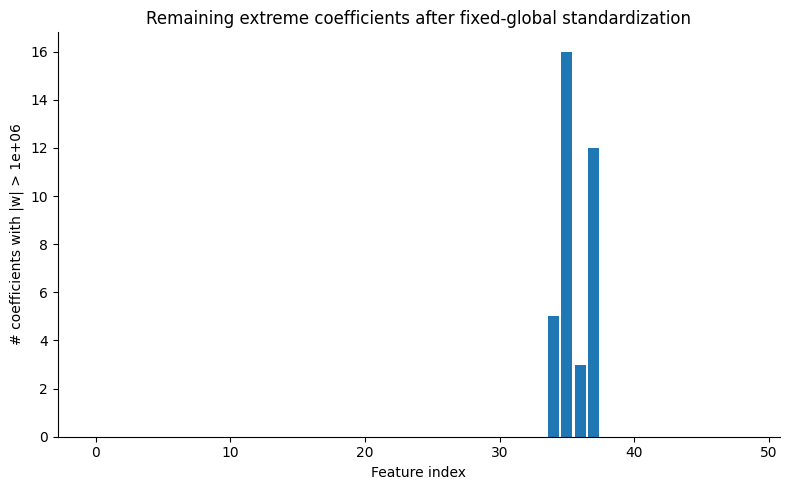

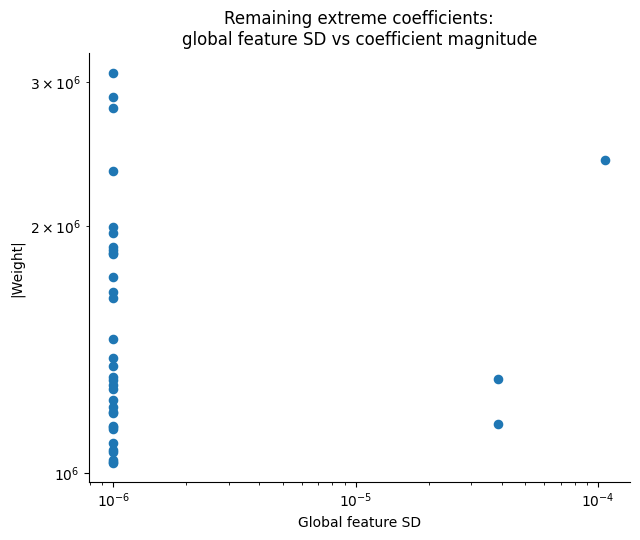

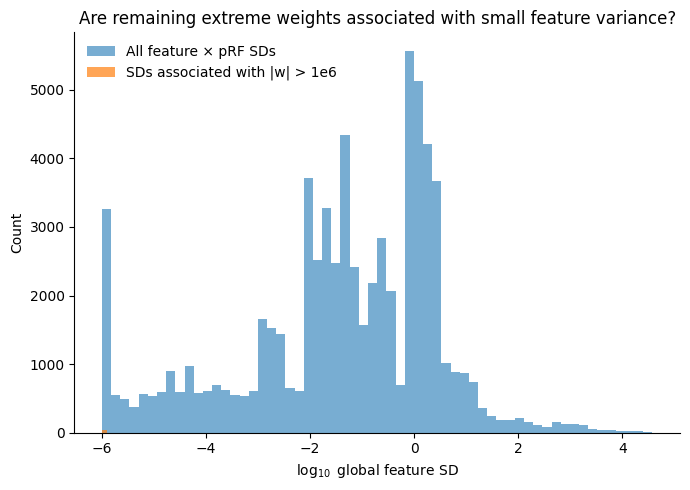


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/remaining_extreme_weights_detail.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/remaining_extreme_weights_by_feature.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/remaining_extreme_weights_by_prf.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/extreme_weights_by_feature.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/extreme_weight_vs_global_sd.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/remaining_extreme_weights/global_sd_all_vs_extreme_weights.png


In [ ]:
# ============================================================
# EXTREME GLOBAL-Z WEIGHTS:
# WHICH FEATURES? WHICH pRFs? WHAT GLOBAL SD?
#
# Assumes these already exist from the previous diagnostic:
#
#   global_fit["weights"]
#   best_prf
#   GLOBAL_MEAN
#   GLOBAL_STD
#
# Goal:
#   Identify all remaining large coefficients after
#   fixed-global standardization and determine whether they
#   cluster by:
#
#       1. feature index
#       2. pRF
#       3. unusually small global feature SD
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

THRESHOLD = 1e6

OUT_DIR_EXTREME = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_zscore_diagnostic"
    / "remaining_extreme_weights"
)

OUT_DIR_EXTREME.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# GET GLOBAL-Z WEIGHTS
# ============================================================

W = np.asarray(
    global_fit["weights"],
    dtype=np.float64
)

# Expected:
# voxels × features
if W.ndim != 2:
    raise RuntimeError(
        f"Expected 2D weight matrix, got {W.shape}"
    )

n_vox, n_feat = W.shape

print("=" * 100)
print("WEIGHT MATRIX")
print("=" * 100)

print("Shape:", W.shape)
print("Threshold:", THRESHOLD)


assert len(best_prf) == n_vox
assert GLOBAL_STD.shape[1] == n_feat
assert GLOBAL_MEAN.shape[1] == n_feat


# ============================================================
# FIND ALL EXTREME WEIGHTS
# ============================================================

extreme_mask = (
    np.isfinite(W)
    &
    (np.abs(W) > THRESHOLD)
)

vox_idx, feat_idx = np.where(
    extreme_mask
)


print("\n" + "=" * 100)
print("EXTREME WEIGHTS")
print("=" * 100)

print(
    f"# |weight| > {THRESHOLD:.1e}:",
    len(vox_idx)
)

print(
    "Affected voxels:",
    len(
        np.unique(
            vox_idx
        )
    )
)

print(
    "Affected feature indices:",
    np.unique(
        feat_idx
    )
)

print(
    "Affected pRFs:",
    len(
        np.unique(
            best_prf[
                vox_idx
            ]
        )
    )
)


# ============================================================
# BUILD DETAIL TABLE
# ============================================================

rows = []

for v, f in zip(
    vox_idx,
    feat_idx
):

    prf = int(
        best_prf[v]
    )

    weight = float(
        W[v, f]
    )

    global_sd = float(
        GLOBAL_STD[
            prf,
            f
        ]
    )

    global_mean = float(
        GLOBAL_MEAN[
            prf,
            f
        ]
    )

    rows.append({

        "voxel":
            int(v),

        "pRF":
            prf,

        "feature":
            int(f),

        "weight":
            weight,

        "abs_weight":
            abs(weight),

        "global_mean":
            global_mean,

        "global_sd":
            global_sd,

        "log10_global_sd":
            (
                np.log10(global_sd)
                if global_sd > 0
                else np.nan
            ),

        "log10_abs_weight":
            (
                np.log10(abs(weight))
                if weight != 0
                else np.nan
            ),
    })


extreme_df = pd.DataFrame(
    rows
)


# Sort strongest first
extreme_df = extreme_df.sort_values(
    "abs_weight",
    ascending=False
).reset_index(drop=True)


print("\n" + "=" * 100)
print("ALL REMAINING EXTREME WEIGHTS")
print("=" * 100)

display(
    extreme_df
)


# ============================================================
# SUMMARY BY FEATURE
# ============================================================

feature_summary = (
    extreme_df
    .groupby(
        "feature"
    )
    .agg(

        n_extreme_weights=(
            "abs_weight",
            "size"
        ),

        n_voxels=(
            "voxel",
            "nunique"
        ),

        n_prfs=(
            "pRF",
            "nunique"
        ),

        median_abs_weight=(
            "abs_weight",
            "median"
        ),

        max_abs_weight=(
            "abs_weight",
            "max"
        ),

        median_global_sd=(
            "global_sd",
            "median"
        ),

        min_global_sd=(
            "global_sd",
            "min"
        ),

        max_global_sd=(
            "global_sd",
            "max"
        ),
    )
    .reset_index()
    .sort_values(
        "n_extreme_weights",
        ascending=False
    )
)


print("\n" + "=" * 100)
print("SUMMARY BY FEATURE")
print("=" * 100)

display(
    feature_summary
)


# ============================================================
# SUMMARY BY pRF
# ============================================================

prf_summary = (
    extreme_df
    .groupby(
        "pRF"
    )
    .agg(

        n_extreme_weights=(
            "abs_weight",
            "size"
        ),

        n_voxels=(
            "voxel",
            "nunique"
        ),

        n_features=(
            "feature",
            "nunique"
        ),

        median_abs_weight=(
            "abs_weight",
            "median"
        ),

        max_abs_weight=(
            "abs_weight",
            "max"
        ),

        median_global_sd=(
            "global_sd",
            "median"
        ),

        min_global_sd=(
            "global_sd",
            "min"
        ),
    )
    .reset_index()
    .sort_values(
        "n_extreme_weights",
        ascending=False
    )
)


print("\n" + "=" * 100)
print("SUMMARY BY pRF")
print("=" * 100)

display(
    prf_summary.head(30)
)


# ============================================================
# HOW SMALL ARE THESE SDs RELATIVE TO ALL FEATURE × pRF CELLS?
# ============================================================

all_sd = GLOBAL_STD[
    np.isfinite(
        GLOBAL_STD
    )
    &
    (GLOBAL_STD > 0)
]


extreme_sd = extreme_df[
    "global_sd"
].to_numpy(
    dtype=float
)


print("\n" + "=" * 100)
print("GLOBAL SD CONTEXT")
print("=" * 100)

print(
    "All feature×pRF global SD:"
)

print(
    "  median:",
    np.median(
        all_sd
    )
)

print(
    "  p1:",
    np.percentile(
        all_sd,
        1
    )
)

print(
    "  p5:",
    np.percentile(
        all_sd,
        5
    )
)

print(
    "  p10:",
    np.percentile(
        all_sd,
        10
    )
)


print(
    "\nExtreme-weight feature×pRF SD:"
)

print(
    "  median:",
    np.median(
        extreme_sd
    )
)

print(
    "  min:",
    np.min(
        extreme_sd
    )
)

print(
    "  max:",
    np.max(
        extreme_sd
    )
)


# ============================================================
# PERCENTILE RANK OF EACH EXTREME SD
#
# Example:
# percentile = 0.2
# means that SD is smaller than ~99.8% of all feature×pRF SDs.
# ============================================================

sorted_all_sd = np.sort(
    all_sd
)


def percentile_rank(
    x,
    reference_sorted
):

    return (
        100.0
        *
        np.searchsorted(
            reference_sorted,
            x,
            side="right"
        )
        /
        len(
            reference_sorted
        )
    )


extreme_df[
    "global_sd_percentile"
] = [
    percentile_rank(
        x,
        sorted_all_sd
    )
    for x in extreme_df[
        "global_sd"
    ]
]


print("\n" + "=" * 100)
print("EXTREME WEIGHTS WITH SD PERCENTILE")
print("=" * 100)

display(
    extreme_df[
        [
            "voxel",
            "pRF",
            "feature",
            "abs_weight",
            "global_sd",
            "global_sd_percentile",
        ]
    ]
)


# ============================================================
# FIGURE 1:
# EXTREME WEIGHTS BY FEATURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5)
)

counts = np.bincount(
    feat_idx,
    minlength=n_feat
)

ax.bar(
    np.arange(
        n_feat
    ),
    counts
)

ax.set_xlabel(
    "Feature index"
)

ax.set_ylabel(
    f"# coefficients with |w| > {THRESHOLD:.0e}"
)

ax.set_title(
    "Remaining extreme coefficients after fixed-global standardization"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()

fn1 = (
    OUT_DIR_EXTREME
    / "extreme_weights_by_feature.png"
)

fig.savefig(
    fn1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2:
# GLOBAL SD vs |WEIGHT| FOR EXTREME COEFFICIENTS
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 5.5)
)

ax.scatter(
    extreme_df[
        "global_sd"
    ],
    extreme_df[
        "abs_weight"
    ],
    s=35
)

ax.set_xscale(
    "log"
)

ax.set_yscale(
    "log"
)

ax.set_xlabel(
    "Global feature SD"
)

ax.set_ylabel(
    "|Weight|"
)

ax.set_title(
    "Remaining extreme coefficients:\n"
    "global feature SD vs coefficient magnitude"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()

fn2 = (
    OUT_DIR_EXTREME
    / "extreme_weight_vs_global_sd.png"
)

fig.savefig(
    fn2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3:
# SD DISTRIBUTION — ALL vs EXTREME
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.hist(
    np.log10(
        all_sd
    ),
    bins=60,
    alpha=0.6,
    label="All feature × pRF SDs"
)

ax.hist(
    np.log10(
        extreme_sd
    ),
    bins=20,
    alpha=0.7,
    label="SDs associated with |w| > 1e6"
)

ax.set_xlabel(
    r"$\log_{10}$ global feature SD"
)

ax.set_ylabel(
    "Count"
)

ax.set_title(
    "Are remaining extreme weights associated with small feature variance?"
)

ax.legend(
    frameon=False
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()

fn3 = (
    OUT_DIR_EXTREME
    / "global_sd_all_vs_extreme_weights.png"
)

fig.savefig(
    fn3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE TABLES
# ============================================================

detail_file = (
    OUT_DIR_EXTREME
    / "remaining_extreme_weights_detail.csv"
)

feature_file = (
    OUT_DIR_EXTREME
    / "remaining_extreme_weights_by_feature.csv"
)

prf_file = (
    OUT_DIR_EXTREME
    / "remaining_extreme_weights_by_prf.csv"
)


extreme_df.to_csv(
    detail_file,
    index=False
)

feature_summary.to_csv(
    feature_file,
    index=False
)

prf_summary.to_csv(
    prf_file,
    index=False
)


print("\nSaved:")
print(detail_file)
print(feature_file)
print(prf_file)
print(fn1)
print(fn2)
print(fn3)

# RAW SD CHECK BEFORE +1e-6

INPUT
Feature file: /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Whole-data rows: 9209
Unique images: 9209
Features checked: [34, 35, 36, 37]
Feature HDF5 shape: (10000, 49, 1456)

COMPUTING TRUE RAW SD
pRF 1/1456
pRF 101/1456
pRF 201/1456
pRF 301/1456
pRF 401/1456
pRF 501/1456
pRF 601/1456
pRF 701/1456
pRF 801/1456
pRF 901/1456
pRF 1001/1456
pRF 1101/1456
pRF 1201/1456
pRF 1301/1456
pRF 1401/1456
pRF 1456/1456

RAW SD SUMMARY — FEATURES 34–37


,feature,n_prfs,n_exact_zero,min_raw_sd,p1_raw_sd,p5_raw_sd,median_raw_sd,max_raw_sd,n_sd_lt_1e-06,pct_sd_lt_1e-06,n_sd_lt_1e-08,pct_sd_lt_1e-08,n_sd_lt_1e-10,pct_sd_lt_1e-10,n_sd_lt_1e-12,pct_sd_lt_1e-12
0,34,1456,0,5.662261e-11,6.381954e-11,7.907490e-11,0.000001,0.000519,684,46.978022,340,23.351648,172,11.813187,0,0.0
1,35,1456,0,4.529983e-11,4.643607e-11,6.289821e-11,0.000002,0.000391,650,44.642857,320,21.978022,252,17.307692,0,0.0
2,36,1456,0,5.715603e-11,5.883389e-11,8.143021e-11,0.000002,0.000806,624,42.857143,340,23.351648,158,10.851648,0,0.0
3,37,1456,0,4.529621e-11,4.650140e-11,6.256879e-11,0.000002,0.000390,650,44.642857,320,21.978022,255,17.513736,0,0.0



NUMBER OF pRFs BELOW EACH RAW-SD THRESHOLD


,feature,threshold,n_prfs_below,pct_prfs_below
0,34,1.000000e-06,684,46.978022
1,34,1.000000e-08,340,23.351648
2,34,1.000000e-10,172,11.813187
3,34,1.000000e-12,0,0.000000
4,35,1.000000e-06,650,44.642857
5,35,1.000000e-08,320,21.978022
6,35,1.000000e-10,252,17.307692
7,35,1.000000e-12,0,0.000000
8,36,1.000000e-06,624,42.857143
9,36,1.000000e-08,340,23.351648



EXTREME WEIGHTS — TRUE RAW SD BEFORE +1e-6


,voxel,pRF,feature,abs_weight,saved_global_sd_with_epsilon,true_raw_sd_before_epsilon,epsilon_contribution,log10_true_raw_sd
30,343,358,35,1.090041e+06,0.000001,5.844423e-11,1.000000e-06,-10.233258
22,273,359,37,1.229660e+06,0.000001,6.148194e-11,1.000000e-06,-10.211252
23,227,329,35,1.205838e+06,0.000001,6.226385e-11,1.000000e-06,-10.205764
24,210,327,35,1.186514e+06,0.000001,6.243953e-11,1.000000e-06,-10.204540
27,338,331,37,1.142802e+06,0.000001,6.250098e-11,1.000000e-06,-10.204113
28,1171,336,35,1.138641e+06,0.000001,6.302965e-11,1.000000e-06,-10.200455
15,227,329,37,1.380896e+06,0.000001,6.336849e-11,1.000000e-06,-10.198127
25,237,329,37,1.184264e+06,0.000001,6.336849e-11,1.000000e-06,-10.198127
16,131,330,37,1.351204e+06,0.000001,6.347226e-11,1.000000e-06,-10.197416
12,131,330,35,1.661394e+06,0.000001,6.369944e-11,1.000000e-06,-10.195864



EXTREME-CASE RAW SD COUNTS
SD < 1e-06: 33 / 36 (91.67%)
SD < 1e-08: 33 / 36 (91.67%)
SD < 1e-10: 25 / 36 (69.44%)
SD < 1e-12: 0 / 36 (0.00%)


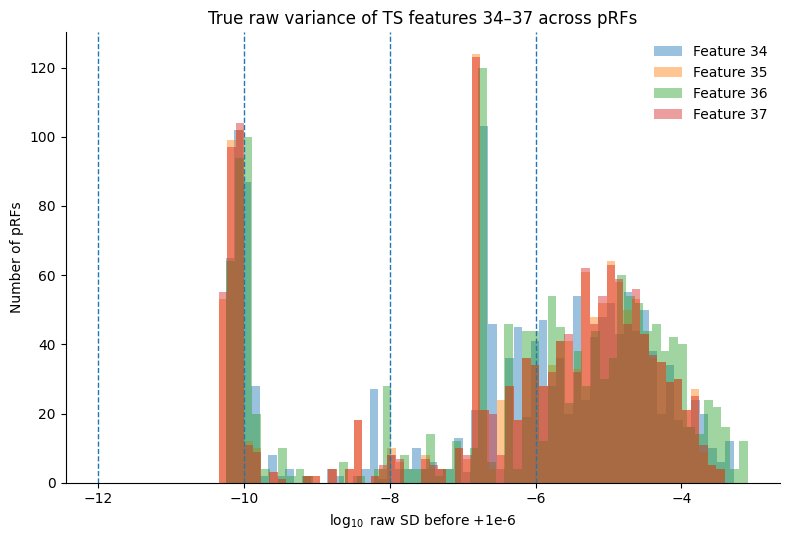

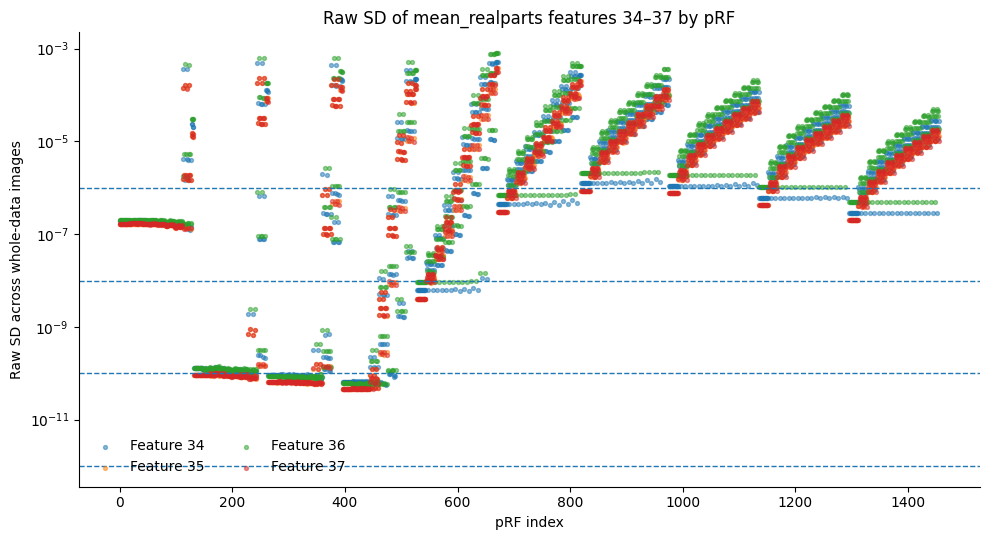


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/features34_37_raw_sd_all_prfs.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/features34_37_raw_sd_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/features34_37_raw_sd_threshold_counts.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/features34_37_raw_sd_distribution.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/features34_37_raw_sd_by_prf.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/global_zscore_diagnostic/raw_sd_features34_37/extreme_weights_true_raw_sd_before_epsilon.csv


In [ ]:
# ============================================================
# RAW SD CHECK BEFORE +1e-6
#
# Goal:
#   For TS pcaHL0 features 34–37 (mean_realparts / linear-mean),
#   compute the TRUE raw SD across the whole-data image set
#   for every pRF, BEFORE adding epsilon=1e-6.
#
# We then ask:
#   - How many pRFs have SD < 1e-6?
#   - SD < 1e-8?
#   - SD < 1e-10?
#   - SD < 1e-12?
#
# We also inspect the exact pRF×feature combinations associated
# with the remaining |w| > 1e6 coefficients from the previous
# fixed-global-z diagnostic.
#
# Assumes these already exist from previous cells:
#   ROOT
#   extreme_df          # table of remaining extreme weights
#
# This code does NOT refit anything.
# ============================================================

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

FEATURE_FILE = (
    ROOT
    / "features"
    / "pyramid_texture"
    / "PCA_pcaHL_v0"
    / "S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py"
)

GLOBAL_STATS_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_feature_zscore"
    / "S01_pcaHL0_4ori_4sf_grid5_wholedata_fixed_mean_std.npz"
)

OUT_DIR_RAW_SD = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_zscore_diagnostic"
    / "raw_sd_features34_37"
)

OUT_DIR_RAW_SD.mkdir(
    parents=True,
    exist_ok=True
)

FEATURES_TO_CHECK = [
    34,
    35,
    36,
    37,
]

THRESHOLDS = [
    1e-6,
    1e-8,
    1e-10,
    1e-12,
]


assert FEATURE_FILE.exists(), FEATURE_FILE
assert GLOBAL_STATS_FILE.exists(), GLOBAL_STATS_FILE


# ============================================================
# LOAD THE EXACT WHOLE-DATA IMAGE ORDER
#
# This was saved inside the global mean/std file when we built it.
# These are the same rows used for the fixed global normalization.
# ============================================================

G = np.load(
    GLOBAL_STATS_FILE,
    allow_pickle=True
)

image_order = np.asarray(
    G["image_order"],
    dtype=int
).reshape(-1)


print("=" * 100)
print("INPUT")
print("=" * 100)

print(
    "Feature file:",
    FEATURE_FILE
)

print(
    "Whole-data rows:",
    len(image_order)
)

print(
    "Unique images:",
    len(
        np.unique(
            image_order
        )
    )
)

print(
    "Features checked:",
    FEATURES_TO_CHECK
)


# ============================================================
# INSPECT FEATURE MATRIX
# ============================================================

with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    X = f["features"]

    n_images, n_features, n_prfs = X.shape


print(
    "Feature HDF5 shape:",
    (
        n_images,
        n_features,
        n_prfs
    )
)

assert n_features == 49
assert max(FEATURES_TO_CHECK) < n_features


# ============================================================
# HANDLE REPEATED IMAGE IDS SAFELY
#
# In your current whole-data fit there were 9209 rows and
# 9209 unique images, but this keeps the code general.
# ============================================================

unique_imgs, inverse = np.unique(
    image_order,
    return_inverse=True
)


# ============================================================
# COMPUTE TRUE RAW SD
#
# Output:
# raw_sd[pRF, feature]
#
# IMPORTANT:
# NO +1e-6 is added here.
# ============================================================

raw_sd = np.full(
    (
        n_prfs,
        len(
            FEATURES_TO_CHECK
        )
    ),
    np.nan,
    dtype=np.float64
)


print("\n" + "=" * 100)
print("COMPUTING TRUE RAW SD")
print("=" * 100)


with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    X = f["features"]

    for prf in range(
        n_prfs
    ):

        if (
            prf % 100 == 0
            or
            prf == n_prfs - 1
        ):

            print(
                f"pRF {prf + 1}/{n_prfs}"
            )


        # ----------------------------------------------------
        # Load ONLY features 34–37 for this pRF.
        #
        # shape:
        # unique_images × 4
        # ----------------------------------------------------

        # First select the image rows for this pRF,
        # then select features 34–37 in NumPy.
        arr_unique = np.asarray(
            X[
                unique_imgs,
                :,
                prf
            ],
            dtype=np.float64
        )

        arr_unique = arr_unique[
            :,
            FEATURES_TO_CHECK
        ]


        # Restore presentation order / repetitions if needed.
        arr = arr_unique[
            inverse,
            :
        ]


        # ----------------------------------------------------
        # TRUE raw SD across images.
        #
        # NO epsilon.
        # ----------------------------------------------------

        raw_sd[
            prf,
            :
        ] = np.nanstd(
            arr,
            axis=0,
            ddof=0
        )


# ============================================================
# LONG-FORM TABLE
# ============================================================

rows = []

for jj, feature in enumerate(
    FEATURES_TO_CHECK
):

    for prf in range(
        n_prfs
    ):

        sd = raw_sd[
            prf,
            jj
        ]

        rows.append({

            "pRF":
                prf,

            "feature":
                feature,

            "raw_sd":
                sd,

            "log10_raw_sd":
                (
                    np.log10(sd)
                    if (
                        np.isfinite(sd)
                        and
                        sd > 0
                    )
                    else -np.inf
                ),
        })


raw_sd_df = pd.DataFrame(
    rows
)


# ============================================================
# SUMMARY PER FEATURE
# ============================================================

summary_rows = []


for feature in FEATURES_TO_CHECK:

    vals = raw_sd_df.loc[
        raw_sd_df[
            "feature"
        ]
        ==
        feature,
        "raw_sd"
    ].to_numpy(
        dtype=float
    )


    finite = vals[
        np.isfinite(vals)
    ]


    row = {

        "feature":
            feature,

        "n_prfs":
            len(finite),

        "n_exact_zero":
            int(
                np.sum(
                    finite == 0
                )
            ),

        "min_raw_sd":
            np.min(
                finite
            ),

        "p1_raw_sd":
            np.percentile(
                finite,
                1
            ),

        "p5_raw_sd":
            np.percentile(
                finite,
                5
            ),

        "median_raw_sd":
            np.median(
                finite
            ),

        "max_raw_sd":
            np.max(
                finite
            ),
    }


    for thr in THRESHOLDS:

        row[
            f"n_sd_lt_{thr:.0e}"
        ] = int(
            np.sum(
                finite < thr
            )
        )

        row[
            f"pct_sd_lt_{thr:.0e}"
        ] = (
            100.0
            *
            np.mean(
                finite < thr
            )
        )


    summary_rows.append(
        row
    )


summary_df = pd.DataFrame(
    summary_rows
)


print("\n" + "=" * 100)
print("RAW SD SUMMARY — FEATURES 34–37")
print("=" * 100)

display(
    summary_df
)


# ============================================================
# SIMPLE COUNTS TABLE
# ============================================================

count_rows = []

for feature in FEATURES_TO_CHECK:

    vals = raw_sd_df.loc[
        raw_sd_df[
            "feature"
        ]
        ==
        feature,
        "raw_sd"
    ].to_numpy(
        dtype=float
    )

    finite = vals[
        np.isfinite(vals)
    ]


    for thr in THRESHOLDS:

        count_rows.append({

            "feature":
                feature,

            "threshold":
                thr,

            "n_prfs_below":
                int(
                    np.sum(
                        finite < thr
                    )
                ),

            "pct_prfs_below":
                (
                    100.0
                    *
                    np.mean(
                        finite < thr
                    )
                ),
        })


threshold_df = pd.DataFrame(
    count_rows
)


print("\n" + "=" * 100)
print("NUMBER OF pRFs BELOW EACH RAW-SD THRESHOLD")
print("=" * 100)

display(
    threshold_df
)


# ============================================================
# CHECK THE EXACT EXTREME-WEIGHT CASES
#
# extreme_df came from the previous analysis and contains:
#   voxel
#   pRF
#   feature
#   abs_weight
#   global_sd
# ============================================================

if "extreme_df" in globals():

    extreme_raw_rows = []


    for _, row in extreme_df.iterrows():

        feature = int(
            row["feature"]
        )

        prf = int(
            row["pRF"]
        )


        if feature not in FEATURES_TO_CHECK:
            continue


        jj = FEATURES_TO_CHECK.index(
            feature
        )


        true_raw_sd = float(
            raw_sd[
                prf,
                jj
            ]
        )


        extreme_raw_rows.append({

            "voxel":
                int(
                    row["voxel"]
                ),

            "pRF":
                prf,

            "feature":
                feature,

            "abs_weight":
                float(
                    row["abs_weight"]
                ),

            "saved_global_sd_with_epsilon":
                float(
                    row["global_sd"]
                ),

            "true_raw_sd_before_epsilon":
                true_raw_sd,

            "epsilon_contribution":
                (
                    float(
                        row["global_sd"]
                    )
                    -
                    true_raw_sd
                ),

            "log10_true_raw_sd":
                (
                    np.log10(
                        true_raw_sd
                    )
                    if true_raw_sd > 0
                    else -np.inf
                ),
        })


    extreme_raw_df = pd.DataFrame(
        extreme_raw_rows
    )


    print("\n" + "=" * 100)
    print("EXTREME WEIGHTS — TRUE RAW SD BEFORE +1e-6")
    print("=" * 100)

    display(
        extreme_raw_df.sort_values(
            "true_raw_sd_before_epsilon"
        )
    )


    print("\n" + "=" * 100)
    print("EXTREME-CASE RAW SD COUNTS")
    print("=" * 100)


    for thr in THRESHOLDS:

        vals = extreme_raw_df[
            "true_raw_sd_before_epsilon"
        ].to_numpy(
            dtype=float
        )

        print(
            f"SD < {thr:.0e}: "
            f"{np.sum(vals < thr)} / {len(vals)} "
            f"({100*np.mean(vals < thr):.2f}%)"
        )


# ============================================================
# FIGURE 1:
# DISTRIBUTION OF RAW SD FOR FEATURES 34–37
# ============================================================

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)


for feature in FEATURES_TO_CHECK:

    vals = raw_sd_df.loc[
        (
            raw_sd_df[
                "feature"
            ]
            ==
            feature
        )
        &
        (
            raw_sd_df[
                "raw_sd"
            ]
            >
            0
        ),
        "raw_sd"
    ].to_numpy(
        dtype=float
    )


    ax.hist(
        np.log10(
            vals
        ),
        bins=60,
        alpha=0.45,
        label=f"Feature {feature}"
    )


for thr in THRESHOLDS:

    ax.axvline(
        np.log10(
            thr
        ),
        linestyle="--",
        linewidth=1
    )


ax.set_xlabel(
    r"$\log_{10}$ raw SD before +1e-6"
)

ax.set_ylabel(
    "Number of pRFs"
)

ax.set_title(
    "True raw variance of TS features 34–37 across pRFs"
)

ax.legend(
    frameon=False
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fig1 = (
    OUT_DIR_RAW_SD
    / "features34_37_raw_sd_distribution.png"
)

fig.savefig(
    fig1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2:
# RAW SD BY pRF
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)


for jj, feature in enumerate(
    FEATURES_TO_CHECK
):

    vals = raw_sd[
        :,
        jj
    ]


    positive = (
        np.isfinite(vals)
        &
        (vals > 0)
    )


    ax.scatter(
        np.arange(
            n_prfs
        )[
            positive
        ],
        vals[
            positive
        ],
        s=8,
        alpha=0.5,
        label=f"Feature {feature}"
    )


ax.set_yscale(
    "log"
)


for thr in THRESHOLDS:

    ax.axhline(
        thr,
        linestyle="--",
        linewidth=1
    )


ax.set_xlabel(
    "pRF index"
)

ax.set_ylabel(
    "Raw SD across whole-data images"
)

ax.set_title(
    "Raw SD of mean_realparts features 34–37 by pRF"
)

ax.legend(
    frameon=False,
    ncol=2
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fig2 = (
    OUT_DIR_RAW_SD
    / "features34_37_raw_sd_by_prf.png"
)

fig.savefig(
    fig2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE
# ============================================================

raw_file = (
    OUT_DIR_RAW_SD
    / "features34_37_raw_sd_all_prfs.csv"
)

summary_file = (
    OUT_DIR_RAW_SD
    / "features34_37_raw_sd_summary.csv"
)

threshold_file = (
    OUT_DIR_RAW_SD
    / "features34_37_raw_sd_threshold_counts.csv"
)


raw_sd_df.to_csv(
    raw_file,
    index=False
)

summary_df.to_csv(
    summary_file,
    index=False
)

threshold_df.to_csv(
    threshold_file,
    index=False
)


print("\nSaved:")
print(raw_file)
print(summary_file)
print(threshold_file)
print(fig1)
print(fig2)


if "extreme_df" in globals():

    extreme_file = (
        OUT_DIR_RAW_SD
        / "extreme_weights_true_raw_sd_before_epsilon.csv"
    )

    extreme_raw_df.to_csv(
        extreme_file,
        index=False
    )

    print(
        extreme_file
    )

# pre regression diagnostic

INPUT
Feature file: /content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Whole-data rows: 9209
Unique image IDs: 9209
pRF model array shape: (1456, 3)
Feature matrix shape: (10000, 49, 1456)

COMPUTING PRE-REGRESSION DIAGNOSTICS
pRF 1/1456
pRF 51/1456
pRF 101/1456
pRF 151/1456
pRF 201/1456
pRF 251/1456
pRF 301/1456
pRF 351/1456
pRF 401/1456
pRF 451/1456
pRF 501/1456
pRF 551/1456
pRF 601/1456
pRF 651/1456
pRF 701/1456
pRF 751/1456
pRF 801/1456
pRF 851/1456
pRF 901/1456
pRF 951/1456
pRF 1001/1456
pRF 1051/1456
pRF 1101/1456
pRF 1151/1456
pRF 1201/1456
pRF 1251/1456
pRF 1301/1456
pRF 1351/1456
pRF 1401/1456
pRF 1451/1456
pRF 1456/1456

FEATURE SUMMARY


,feature,family,min_sd,p1_sd,p5_sd,median_sd,max_sd,n_prfs_sd_lt_1e-06,pct_prfs_sd_lt_1e-06,n_prfs_sd_lt_1e-08,pct_prfs_sd_lt_1e-08,n_prfs_sd_lt_1e-10,pct_prfs_sd_lt_1e-10,n_prfs_sd_lt_1e-12,pct_prfs_sd_lt_1e-12
0,0,pixel_stats,1.135237e-01,1.140350e-01,1.148014e-01,0.138069,0.264005,0,0.000000,0,0.000000,0,0.000000,0,0.0
1,1,pixel_stats,1.909778e-02,2.029393e-02,2.266284e-02,0.025535,0.029372,0,0.000000,0,0.000000,0,0.000000,0,0.0
2,2,pixel_stats,7.715604e-01,7.737031e-01,7.786580e-01,1.068243,10.678776,0,0.000000,0,0.000000,0,0.000000,0,0.0
3,3,pixel_stats,2.294760e+00,2.346448e+00,2.441594e+00,5.033145,4089.943989,0,0.000000,0,0.000000,0,0.000000,0,0.0
4,4,pixel_stats,2.534039e-02,2.534039e-02,2.534039e-02,0.025340,0.025340,0,0.000000,0,0.000000,0,0.000000,0,0.0
5,5,pixel_stats,4.376950e-02,4.376950e-02,4.376950e-02,0.043769,0.043769,0,0.000000,0,0.000000,0,0.000000,0,0.0
6,6,mean_magnitudes,1.070149e+00,1.070857e+00,1.071760e+00,1.337013,3.142349,0,0.000000,0,0.000000,0,0.000000,0,0.0
7,7,mean_magnitudes,8.142220e-01,8.145258e-01,8.149938e-01,1.038447,2.161609,0,0.000000,0,0.000000,0,0.000000,0,0.0
8,8,mean_magnitudes,1.069880e+00,1.070973e+00,1.072638e+00,1.364022,3.359693,0,0.000000,0,0.000000,0,0.000000,0,0.0
9,9,mean_magnitudes,8.152464e-01,8.154344e-01,8.157854e-01,1.043447,2.137349,0,0.000000,0,0.000000,0,0.000000,0,0.0



FEATURE FAMILY SUMMARY


,family,n_feature_prf_pairs,min_sd,p1_sd,p5_sd,median_sd,max_sd,n_sd_lt_1e-06,fraction_sd_lt_1e-06,n_sd_lt_1e-08,fraction_sd_lt_1e-08,n_sd_lt_1e-10,fraction_sd_lt_1e-10,n_sd_lt_1e-12,fraction_sd_lt_1e-12
0,marginal_stats_lowpass_recons,14560,4.475117e-01,6.940257e-01,7.480964e-01,2.193642,38184.753654,0,0.000000,0,0.000000,0,0.000000,0,0.0
1,mean_magnitudes,23296,7.973375e-03,8.096367e-03,8.985208e-03,0.140050,3.359693,0,0.000000,0,0.000000,0,0.000000,0,0.0
2,mean_realparts,23296,4.529621e-11,6.322585e-11,3.534066e-10,0.000372,2.863188,3662,0.157194,1616,0.069368,837,0.035929,0,0.0
3,pixel_stats,8736,1.909778e-02,2.317958e-02,2.507065e-02,0.078647,4089.943989,0,0.000000,0,0.000000,0,0.000000,0,0.0
4,variance_highpass_resid,1456,9.907985e-04,9.945684e-04,9.984811e-04,0.001184,0.002178,0,0.000000,0,0.000000,0,0.000000,0,0.0



pRF SUMMARY


,prf,prf_x,prf_y,prf_sigma,prf_ecc,min_feature_sd,median_feature_sd,raw_condition,log10_raw_condition,standardized_condition,...,standardized_sigma_min,raw_rank,standardized_rank,max_abs_feature_corr,n_feature_pairs_abs_r_gt_099,n_feature_pairs_abs_r_gt_0999,n_features_sd_lt_1e-06,n_features_sd_lt_1e-08,n_features_sd_lt_1e-10,n_features_sd_lt_1e-12
362,362,2.427450e-01,0.242745,0.047707,0.343293,1.342180e-10,0.208975,6.533097e+14,14.815119,172.777739,...,1.890882,41.0,49.0,0.998920,2,0,8,4,0,0
348,348,-1.074719e-08,0.245867,0.047707,0.245867,8.254157e-11,0.202243,3.804351e+14,14.580281,198.192641,...,1.643573,41.0,49.0,0.997674,2,0,8,4,1,0
233,233,-1.313726e-01,0.317162,0.030889,0.343293,7.620929e-11,0.230010,3.436315e+14,14.536093,81.591649,...,3.941534,45.0,49.0,0.997847,2,0,4,4,3,0
366,366,-2.427450e-01,0.242745,0.047707,0.343293,1.345246e-10,0.210932,3.110802e+14,14.492872,191.154155,...,1.708524,41.0,49.0,0.998711,2,0,8,4,0,0
250,250,-3.310413e-01,0.331041,0.030889,0.468163,1.453404e-10,0.239810,3.046173e+14,14.483755,100.890959,...,3.193853,45.0,49.0,0.995580,2,0,4,4,0,0
374,374,2.427450e-01,-0.242745,0.047707,0.343293,1.305727e-10,0.190502,2.853437e+14,14.455368,275.916135,...,1.133233,41.0,49.0,0.995497,2,0,8,4,0,0
231,231,1.313727e-01,0.317162,0.030889,0.343293,8.281996e-11,0.229225,2.748075e+14,14.439029,49.884340,...,6.436330,45.0,49.0,0.989461,0,0,4,4,2,0
246,246,3.310413e-01,0.331041,0.030889,0.468163,1.463723e-10,0.238520,2.723994e+14,14.435206,157.780184,...,2.037336,45.0,49.0,0.998873,2,0,4,4,0,0
232,232,-1.500583e-08,0.343293,0.030889,0.343293,9.911192e-11,0.233345,2.663000e+14,14.425371,104.867160,...,3.073283,45.0,49.0,0.997580,2,0,4,4,1,0
349,349,-9.408928e-02,0.227152,0.047707,0.245867,6.092139e-11,0.200436,2.500995e+14,14.398113,114.235030,...,2.840446,41.0,49.0,0.990916,1,0,8,4,4,0



OVERALL CONDITIONING SUMMARY


,metric,value
0,Median raw log10(condition),9.570689e+00
1,Median standardized log10(condition),2.866118e+00
2,Median raw sigma_min,6.628254e-07
3,Median standardized sigma_min,4.684697e-01
4,Median maximum |feature correlation|,9.986980e-01
5,Median # pairs |r| > 0.99,6.000000e+00
6,Median # pairs |r| > 0.999,0.000000e+00


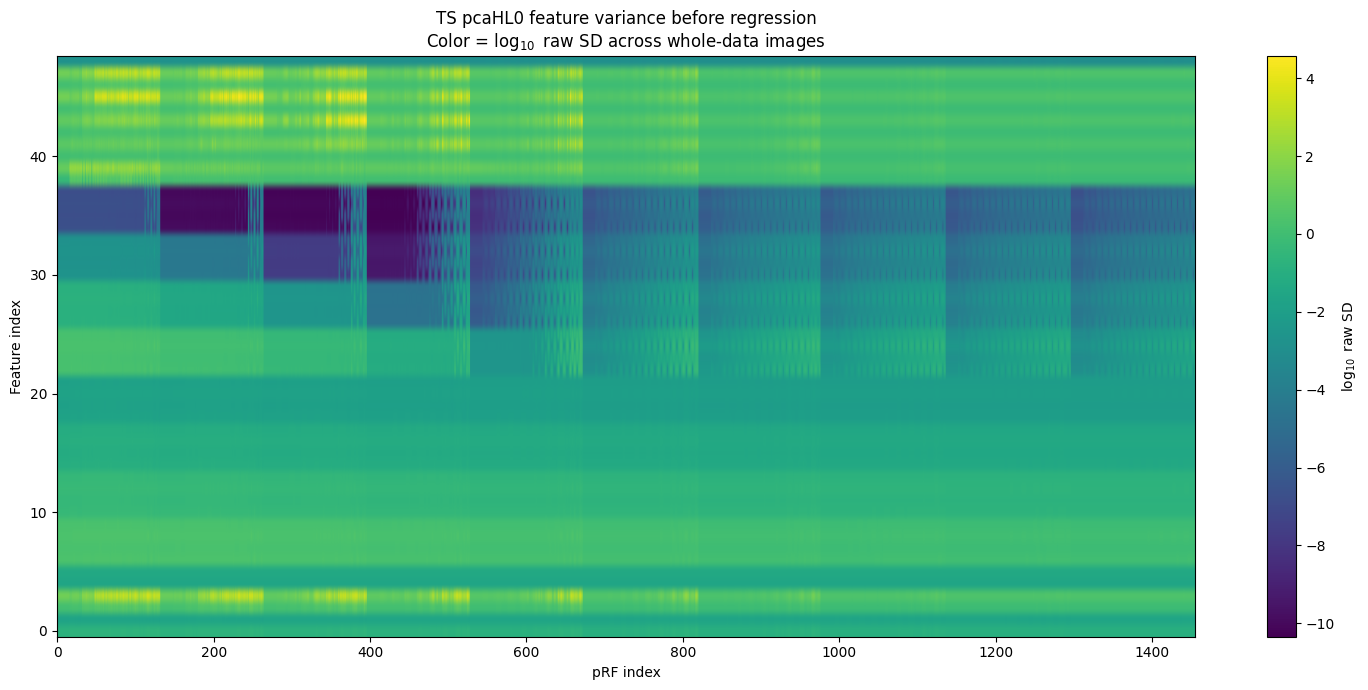

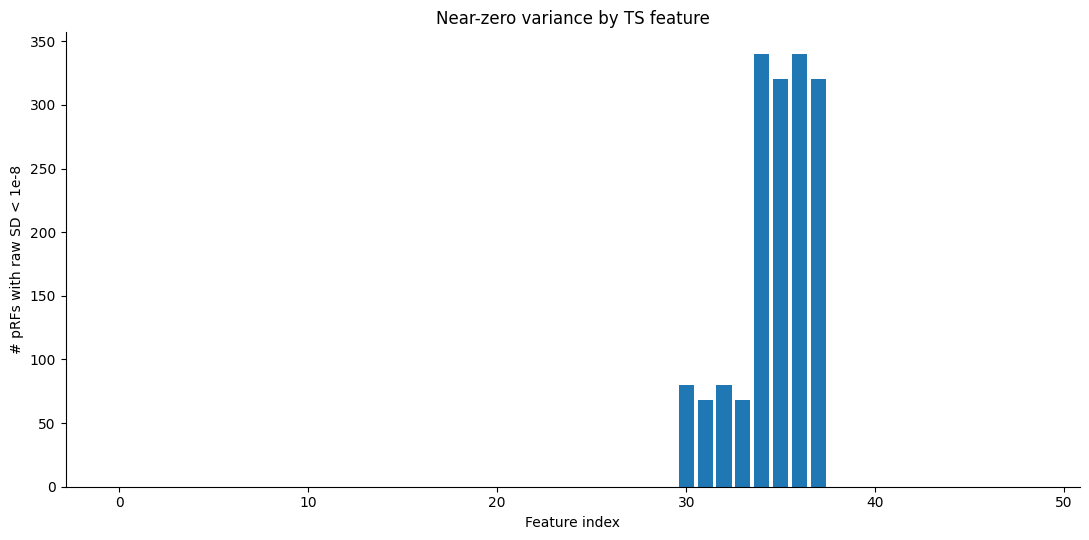

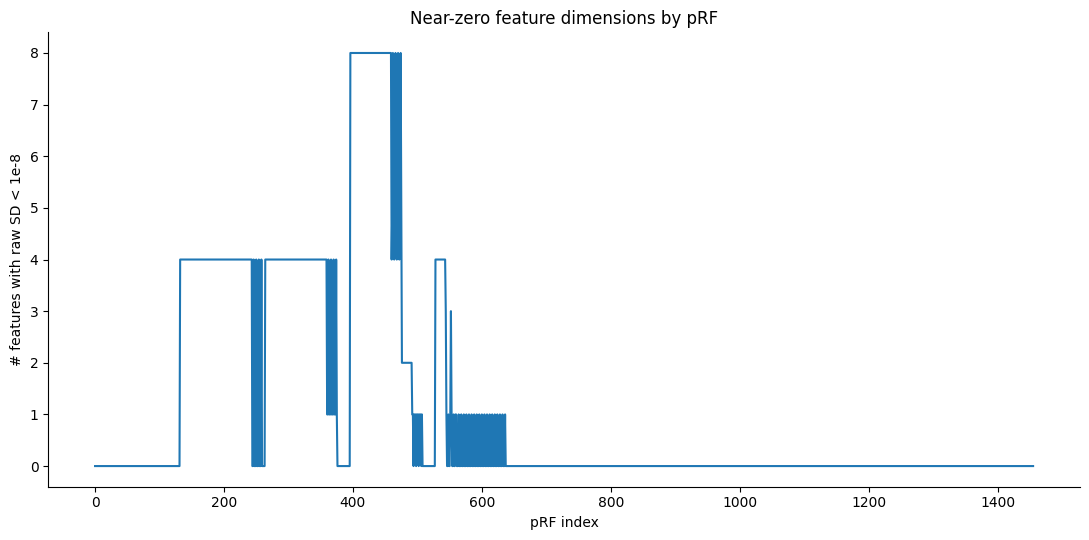

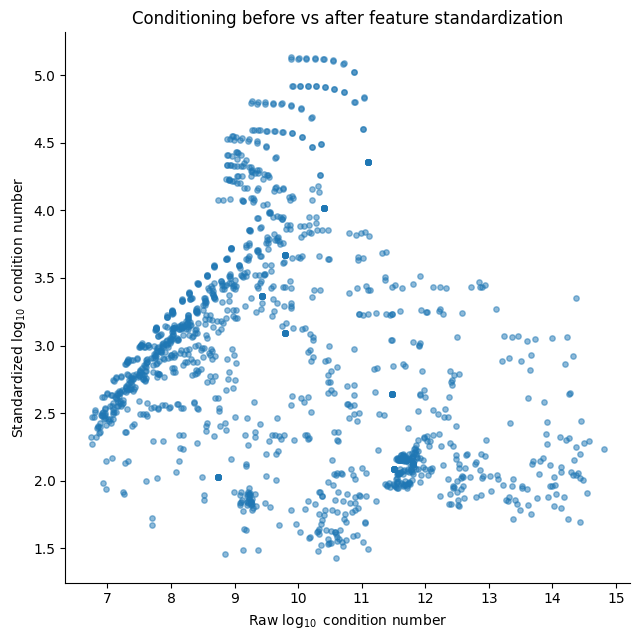

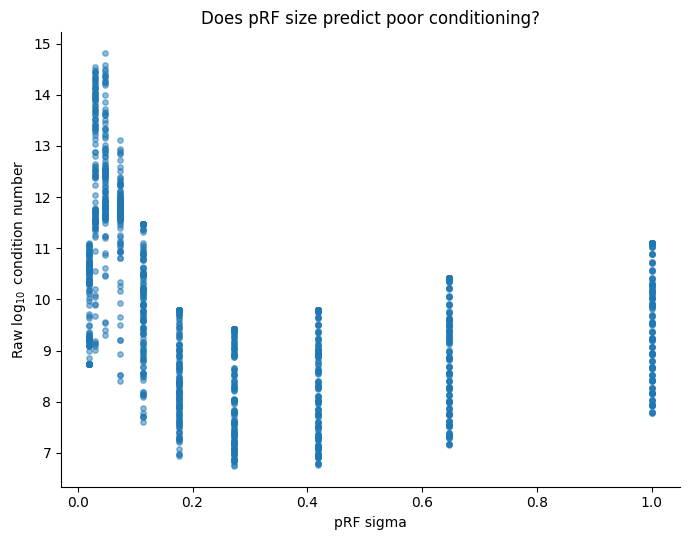

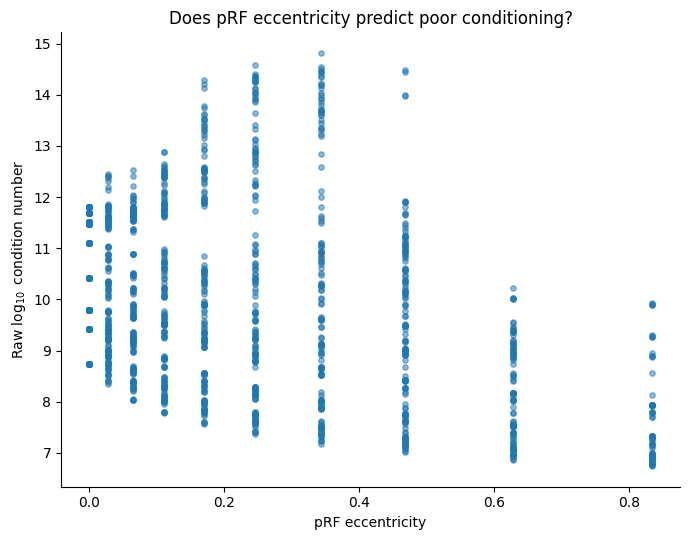

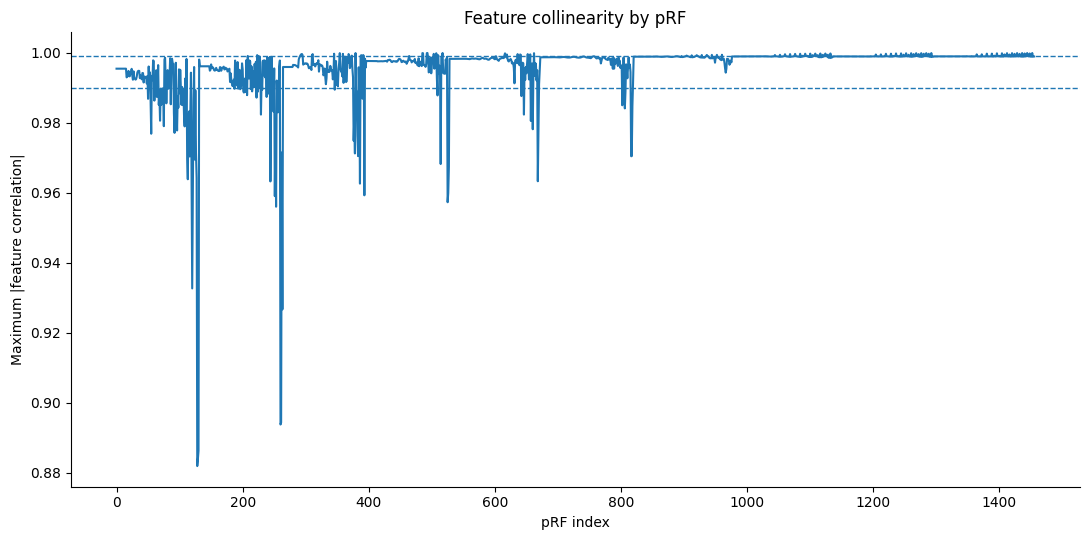


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/feature_by_prf_diagnostics.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/feature_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/feature_family_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/prf_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/feature_by_prf_log10_raw_sd_heatmap.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/near_zero_prfs_by_feature.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/near_zero_features_by_prf.p

In [ ]:
# ============================================================
# FULL PRE-REGRESSION DIAGNOSTIC
# TS pcaHL0 — S01
#
# PURPOSE
# -------
# Characterize the TS feature representation BEFORE regression.
#
# Questions:
#   1. Are some features systematically near-zero variance?
#   2. Are some feature families more problematic?
#   3. Are some pRFs systematically problematic?
#   4. Is poor conditioning mainly due to feature scale?
#   5. Does poor conditioning remain after standardization?
#   6. Are some pRFs highly collinear?
#   7. Is instability related to pRF size / position?
#
# NO REGRESSION IS RUN.
# ============================================================

import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/V2_drift"
)

SUBJECT = 1
PCA_TYPE = "pcaHL"
PCA_PCT = 0

FEATURE_FILE = (
    ROOT
    / "features"
    / "pyramid_texture"
    / "PCA_pcaHL_v0"
    / "S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py"
)

GLOBAL_STATS_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_feature_zscore"
    / "S01_pcaHL0_4ori_4sf_grid5_wholedata_fixed_mean_std.npz"
)

# Whole-data fit used only to retrieve pRF model coordinates
WHOLE_FIT = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / "S01"
    / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs"
    / "Aug-23-2026_0856_24"
    / "all_fit_params.npy"
)

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "pre_regression_diagnostics"
    / "S01_pcaHL0"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

assert FEATURE_FILE.exists(), FEATURE_FILE
assert GLOBAL_STATS_FILE.exists(), GLOBAL_STATS_FILE
assert WHOLE_FIT.exists(), WHOLE_FIT


# ============================================================
# FEATURE FAMILY DEFINITIONS
#
# pcaHL0 = 49 original low-level TS dimensions:
#
# 0–5   pixel_stats
# 6–21  mean_magnitudes
# 22–37 mean_realparts
# 38–47 marginal_stats_lowpass_recons
# 48    variance_highpass_resid
# ============================================================

FEATURE_FAMILIES = {
    "pixel_stats":
        list(range(0, 6)),

    "mean_magnitudes":
        list(range(6, 22)),

    "mean_realparts":
        list(range(22, 38)),

    "marginal_stats_lowpass_recons":
        list(range(38, 48)),

    "variance_highpass_resid":
        [48],
}

feature_to_family = {}

for family, inds in FEATURE_FAMILIES.items():
    for f in inds:
        feature_to_family[f] = family


# ============================================================
# THRESHOLDS
# ============================================================

SD_THRESHOLDS = [
    1e-6,
    1e-8,
    1e-10,
    1e-12,
]

CORR_THRESHOLDS = [
    0.99,
    0.999,
]


# ============================================================
# LOAD IMAGE ORDER
# ============================================================

G = np.load(
    GLOBAL_STATS_FILE,
    allow_pickle=True
)

image_order = np.asarray(
    G["image_order"],
    dtype=int
).reshape(-1)

unique_imgs, inverse = np.unique(
    image_order,
    return_inverse=True
)


print("=" * 110)
print("INPUT")
print("=" * 110)

print(
    "Feature file:",
    FEATURE_FILE
)

print(
    "Whole-data rows:",
    len(image_order)
)

print(
    "Unique image IDs:",
    len(unique_imgs)
)


# ============================================================
# LOAD pRF MODEL COORDINATES
# ============================================================

D = np.load(
    WHOLE_FIT,
    allow_pickle=True
).item()

prf_models = np.asarray(
    D["models"],
    dtype=np.float64
)

print(
    "pRF model array shape:",
    prf_models.shape
)

assert prf_models.shape[1] >= 3


# expected:
# col0 = x
# col1 = y
# col2 = sigma

prf_x = prf_models[:, 0]
prf_y = prf_models[:, 1]
prf_sigma = prf_models[:, 2]

prf_ecc = np.sqrt(
    prf_x**2
    +
    prf_y**2
)


# ============================================================
# INSPECT FEATURE FILE
# ============================================================

with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    X = f["features"]

    n_images, n_features, n_prfs = X.shape


print(
    "Feature matrix shape:",
    (
        n_images,
        n_features,
        n_prfs
    )
)

assert n_features == 49
assert n_prfs == 1456


# ============================================================
# OUTPUT ARRAYS
# ============================================================

raw_sd = np.full(
    (
        n_prfs,
        n_features
    ),
    np.nan,
    dtype=np.float64
)

raw_mean = np.full(
    (
        n_prfs,
        n_features
    ),
    np.nan,
    dtype=np.float64
)

raw_cond = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

std_cond = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

raw_sigma_min = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

std_sigma_min = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

raw_rank = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

std_rank = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

max_abs_corr = np.full(
    n_prfs,
    np.nan,
    dtype=np.float64
)

n_corr_gt_099 = np.zeros(
    n_prfs,
    dtype=int
)

n_corr_gt_0999 = np.zeros(
    n_prfs,
    dtype=int
)


# ============================================================
# HELPERS
# ============================================================

def svd_diagnostics(
    X,
    standardize=False
):

    X = np.asarray(
        X,
        dtype=np.float64
    )

    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[
        row_ok
    ]

    if X.shape[0] == 0:

        return {
            "condition":
                np.nan,

            "sigma_min":
                np.nan,

            "rank":
                0,

            "n_features":
                0,
        }


    # center columns
    Xc = (
        X
        -
        np.mean(
            X,
            axis=0,
            keepdims=True
        )
    )


    # remove exactly constant columns
    norms = np.linalg.norm(
        Xc,
        axis=0
    )

    good = (
        np.isfinite(norms)
        &
        (norms > 0)
    )

    Xc = Xc[
        :,
        good
    ]


    if Xc.shape[1] == 0:

        return {
            "condition":
                np.inf,

            "sigma_min":
                0,

            "rank":
                0,

            "n_features":
                0,
        }


    if standardize:

        sd = np.std(
            Xc,
            axis=0,
            ddof=0
        )

        good_sd = (
            np.isfinite(sd)
            &
            (sd > 0)
        )

        Xc = Xc[
            :,
            good_sd
        ]

        sd = sd[
            good_sd
        ]

        Xc = (
            Xc
            /
            sd[
                None,
                :
            ]
        )


    S = np.linalg.svd(
        Xc,
        compute_uv=False,
        full_matrices=False
    )


    sigma_max = float(
        S[0]
    )

    sigma_min = float(
        S[-1]
    )


    tol = (
        max(
            Xc.shape
        )
        *
        np.finfo(
            np.float64
        ).eps
        *
        sigma_max
    )


    rank = int(
        np.sum(
            S > tol
        )
    )


    cond = (
        sigma_max
        /
        sigma_min
        if sigma_min > 0
        else np.inf
    )


    return {
        "condition":
            cond,

        "sigma_min":
            sigma_min,

        "rank":
            rank,

        "n_features":
            Xc.shape[1],
    }


def correlation_diagnostics(
    X
):

    X = np.asarray(
        X,
        dtype=np.float64
    )


    row_ok = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[
        row_ok
    ]


    sd = np.std(
        X,
        axis=0,
        ddof=0
    )

    good = (
        np.isfinite(sd)
        &
        (sd > 0)
    )

    X = X[
        :,
        good
    ]


    if X.shape[1] < 2:

        return (
            np.nan,
            0,
            0
        )


    C = np.corrcoef(
        X,
        rowvar=False
    )


    upper = np.triu_indices(
        C.shape[0],
        k=1
    )

    vals = np.abs(
        C[
            upper
        ]
    )

    vals = vals[
        np.isfinite(
            vals
        )
    ]


    if len(vals) == 0:

        return (
            np.nan,
            0,
            0
        )


    return (
        np.max(
            vals
        ),

        np.sum(
            vals > 0.99
        ),

        np.sum(
            vals > 0.999
        ),
    )


# ============================================================
# MAIN LOOP
# ============================================================

print(
    "\n"
    +
    "=" * 110
)

print(
    "COMPUTING PRE-REGRESSION DIAGNOSTICS"
)

print(
    "=" * 110
)


with h5py.File(
    FEATURE_FILE,
    "r"
) as f:

    X = f["features"]


    for prf in range(
        n_prfs
    ):


        if (
            prf % 50 == 0
            or
            prf == n_prfs - 1
        ):

            print(
                f"pRF "
                f"{prf + 1}/"
                f"{n_prfs}"
            )


        # ----------------------------------------------------
        # Load all 49 features for this pRF
        # ----------------------------------------------------

        arr_unique = np.asarray(
            X[
                unique_imgs,
                :,
                prf
            ],
            dtype=np.float64
        )


        arr = arr_unique[
            inverse
        ]


        # ----------------------------------------------------
        # RAW mean / SD
        # ----------------------------------------------------

        raw_mean[
            prf,
            :
        ] = np.nanmean(
            arr,
            axis=0
        )


        raw_sd[
            prf,
            :
        ] = np.nanstd(
            arr,
            axis=0,
            ddof=0
        )


        # ----------------------------------------------------
        # Conditioning
        # ----------------------------------------------------

        diag_raw = svd_diagnostics(
            arr,
            standardize=False
        )

        diag_std = svd_diagnostics(
            arr,
            standardize=True
        )


        raw_cond[
            prf
        ] = diag_raw[
            "condition"
        ]

        std_cond[
            prf
        ] = diag_std[
            "condition"
        ]

        raw_sigma_min[
            prf
        ] = diag_raw[
            "sigma_min"
        ]

        std_sigma_min[
            prf
        ] = diag_std[
            "sigma_min"
        ]

        raw_rank[
            prf
        ] = diag_raw[
            "rank"
        ]

        std_rank[
            prf
        ] = diag_std[
            "rank"
        ]


        # ----------------------------------------------------
        # Correlation / collinearity
        # ----------------------------------------------------

        (
            max_corr,
            n99,
            n999
        ) = correlation_diagnostics(
            arr
        )


        max_abs_corr[
            prf
        ] = max_corr

        n_corr_gt_099[
            prf
        ] = n99

        n_corr_gt_0999[
            prf
        ] = n999


# ============================================================
# FEATURE × pRF LONG TABLE
# ============================================================

feature_prf_rows = []


for prf in range(
    n_prfs
):

    for feature in range(
        n_features
    ):

        sd = raw_sd[
            prf,
            feature
        ]


        feature_prf_rows.append({

            "prf":
                prf,

            "feature":
                feature,

            "family":
                feature_to_family[
                    feature
                ],

            "raw_mean":
                raw_mean[
                    prf,
                    feature
                ],

            "raw_sd":
                sd,

            "log10_raw_sd":
                (
                    np.log10(
                        sd
                    )
                    if (
                        np.isfinite(
                            sd
                        )
                        and
                        sd > 0
                    )
                    else -np.inf
                ),

            "prf_x":
                prf_x[
                    prf
                ],

            "prf_y":
                prf_y[
                    prf
                ],

            "prf_sigma":
                prf_sigma[
                    prf
                ],

            "prf_ecc":
                prf_ecc[
                    prf
                ],
        })


feature_prf_df = pd.DataFrame(
    feature_prf_rows
)


# ============================================================
# FEATURE SUMMARY
# ============================================================

feature_rows = []


for feature in range(
    n_features
):

    vals = raw_sd[
        :,
        feature
    ]


    finite = vals[
        np.isfinite(
            vals
        )
    ]


    row = {

        "feature":
            feature,

        "family":
            feature_to_family[
                feature
            ],

        "min_sd":
            np.min(
                finite
            ),

        "p1_sd":
            np.percentile(
                finite,
                1
            ),

        "p5_sd":
            np.percentile(
                finite,
                5
            ),

        "median_sd":
            np.median(
                finite
            ),

        "max_sd":
            np.max(
                finite
            ),
    }


    for thr in SD_THRESHOLDS:

        row[
            f"n_prfs_sd_lt_{thr:.0e}"
        ] = int(
            np.sum(
                finite < thr
            )
        )

        row[
            f"pct_prfs_sd_lt_{thr:.0e}"
        ] = (
            100
            *
            np.mean(
                finite < thr
            )
        )


    feature_rows.append(
        row
    )


feature_summary = pd.DataFrame(
    feature_rows
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "FEATURE SUMMARY"
)

print(
    "=" * 110
)

display(
    feature_summary
)


# ============================================================
# FAMILY SUMMARY
# ============================================================

family_summary = (
    feature_prf_df
    .groupby(
        "family"
    )
    .agg(

        n_feature_prf_pairs=(
            "raw_sd",
            "size"
        ),

        min_sd=(
            "raw_sd",
            "min"
        ),

        p1_sd=(
            "raw_sd",
            lambda x:
                np.percentile(
                    x,
                    1
                )
        ),

        p5_sd=(
            "raw_sd",
            lambda x:
                np.percentile(
                    x,
                    5
                )
        ),

        median_sd=(
            "raw_sd",
            "median"
        ),

        max_sd=(
            "raw_sd",
            "max"
        ),
    )
    .reset_index()
)


for thr in SD_THRESHOLDS:

    counts = (
        feature_prf_df
        .assign(
            below=
                feature_prf_df[
                    "raw_sd"
                ]
                <
                thr
        )
        .groupby(
            "family"
        )[
            "below"
        ]
        .agg(
            [
                "sum",
                "mean"
            ]
        )
        .reset_index()
    )


    family_summary = (
        family_summary
        .merge(
            counts[
                [
                    "family",
                    "sum",
                    "mean"
                ]
            ],
            on="family",
            how="left"
        )
        .rename(
            columns={
                "sum":
                    f"n_sd_lt_{thr:.0e}",

                "mean":
                    f"fraction_sd_lt_{thr:.0e}",
            }
        )
    )


print(
    "\n"
    +
    "=" * 110
)

print(
    "FEATURE FAMILY SUMMARY"
)

print(
    "=" * 110
)

display(
    family_summary
)


# ============================================================
# pRF SUMMARY
# ============================================================

prf_rows = []


for prf in range(
    n_prfs
):

    vals = raw_sd[
        prf,
        :
    ]


    finite = vals[
        np.isfinite(
            vals
        )
    ]


    row = {

        "prf":
            prf,

        "prf_x":
            prf_x[
                prf
            ],

        "prf_y":
            prf_y[
                prf
            ],

        "prf_sigma":
            prf_sigma[
                prf
            ],

        "prf_ecc":
            prf_ecc[
                prf
            ],

        "min_feature_sd":
            np.min(
                finite
            ),

        "median_feature_sd":
            np.median(
                finite
            ),

        "raw_condition":
            raw_cond[
                prf
            ],

        "log10_raw_condition":
            (
                np.log10(
                    raw_cond[
                        prf
                    ]
                )
                if np.isfinite(
                    raw_cond[
                        prf
                    ]
                )
                else np.inf
            ),

        "standardized_condition":
            std_cond[
                prf
            ],

        "log10_standardized_condition":
            (
                np.log10(
                    std_cond[
                        prf
                    ]
                )
                if np.isfinite(
                    std_cond[
                        prf
                    ]
                )
                else np.inf
            ),

        "raw_sigma_min":
            raw_sigma_min[
                prf
            ],

        "standardized_sigma_min":
            std_sigma_min[
                prf
            ],

        "raw_rank":
            raw_rank[
                prf
            ],

        "standardized_rank":
            std_rank[
                prf
            ],

        "max_abs_feature_corr":
            max_abs_corr[
                prf
            ],

        "n_feature_pairs_abs_r_gt_099":
            n_corr_gt_099[
                prf
            ],

        "n_feature_pairs_abs_r_gt_0999":
            n_corr_gt_0999[
                prf
            ],
    }


    for thr in SD_THRESHOLDS:

        row[
            f"n_features_sd_lt_{thr:.0e}"
        ] = int(
            np.sum(
                finite < thr
            )
        )


    prf_rows.append(
        row
    )


prf_summary = pd.DataFrame(
    prf_rows
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "pRF SUMMARY"
)

print(
    "=" * 110
)

display(
    prf_summary
    .sort_values(
        "log10_raw_condition",
        ascending=False
    )
    .head(
        30
    )
)


# ============================================================
# OVERALL CONDITIONING SUMMARY
# ============================================================

conditioning_summary = pd.DataFrame({

    "metric": [

        "Median raw log10(condition)",
        "Median standardized log10(condition)",

        "Median raw sigma_min",
        "Median standardized sigma_min",

        "Median maximum |feature correlation|",

        "Median # pairs |r| > 0.99",
        "Median # pairs |r| > 0.999",
    ],

    "value": [

        np.nanmedian(
            np.log10(
                raw_cond[
                    np.isfinite(
                        raw_cond
                    )
                ]
            )
        ),

        np.nanmedian(
            np.log10(
                std_cond[
                    np.isfinite(
                        std_cond
                    )
                ]
            )
        ),

        np.nanmedian(
            raw_sigma_min
        ),

        np.nanmedian(
            std_sigma_min
        ),

        np.nanmedian(
            max_abs_corr
        ),

        np.nanmedian(
            n_corr_gt_099
        ),

        np.nanmedian(
            n_corr_gt_0999
        ),
    ],
})


print(
    "\n"
    +
    "=" * 110
)

print(
    "OVERALL CONDITIONING SUMMARY"
)

print(
    "=" * 110
)

display(
    conditioning_summary
)


# ============================================================
# FIGURE 1
# FEATURE × pRF RAW-SD HEATMAP
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 7)
)

plot_data = np.log10(
    np.clip(
        raw_sd.T,
        1e-15,
        None
    )
)

im = ax.imshow(
    plot_data,
    aspect="auto",
    origin="lower"
)

ax.set_xlabel(
    "pRF index"
)

ax.set_ylabel(
    "Feature index"
)

ax.set_title(
    "TS pcaHL0 feature variance before regression\n"
    r"Color = $\log_{10}$ raw SD across whole-data images"
)

cbar = fig.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    r"$\log_{10}$ raw SD"
)

fig.tight_layout()


fn1 = (
    OUT_DIR
    / "feature_by_prf_log10_raw_sd_heatmap.png"
)

fig.savefig(
    fn1,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2
# NEAR-ZERO pRF COUNT BY FEATURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

counts = np.sum(
    raw_sd < 1e-8,
    axis=0
)

ax.bar(
    np.arange(
        n_features
    ),
    counts
)

ax.set_xlabel(
    "Feature index"
)

ax.set_ylabel(
    "# pRFs with raw SD < 1e-8"
)

ax.set_title(
    "Near-zero variance by TS feature"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn2 = (
    OUT_DIR
    / "near_zero_prfs_by_feature.png"
)

fig.savefig(
    fn2,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3
# NEAR-ZERO FEATURE COUNT BY pRF
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

counts = np.sum(
    raw_sd < 1e-8,
    axis=1
)

ax.plot(
    np.arange(
        n_prfs
    ),
    counts
)

ax.set_xlabel(
    "pRF index"
)

ax.set_ylabel(
    "# features with raw SD < 1e-8"
)

ax.set_title(
    "Near-zero feature dimensions by pRF"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn3 = (
    OUT_DIR
    / "near_zero_features_by_prf.png"
)

fig.savefig(
    fn3,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4
# RAW vs STANDARDIZED CONDITIONING
# ============================================================

fig, ax = plt.subplots(
    figsize=(6.5, 6.5)
)

finite = (
    np.isfinite(
        raw_cond
    )
    &
    np.isfinite(
        std_cond
    )
)

ax.scatter(
    np.log10(
        raw_cond[
            finite
        ]
    ),
    np.log10(
        std_cond[
            finite
        ]
    ),
    s=15,
    alpha=0.5
)

ax.set_xlabel(
    r"Raw $\log_{10}$ condition number"
)

ax.set_ylabel(
    r"Standardized $\log_{10}$ condition number"
)

ax.set_title(
    "Conditioning before vs after feature standardization"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn4 = (
    OUT_DIR
    / "raw_vs_standardized_conditioning_by_prf.png"
)

fig.savefig(
    fn4,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 5
# pRF SIGMA vs CONDITIONING
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

finite = (
    np.isfinite(
        prf_sigma
    )
    &
    np.isfinite(
        raw_cond
    )
)

ax.scatter(
    prf_sigma[
        finite
    ],
    np.log10(
        raw_cond[
            finite
        ]
    ),
    s=15,
    alpha=0.5
)

ax.set_xlabel(
    "pRF sigma"
)

ax.set_ylabel(
    r"Raw $\log_{10}$ condition number"
)

ax.set_title(
    "Does pRF size predict poor conditioning?"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn5 = (
    OUT_DIR
    / "prf_sigma_vs_raw_conditioning.png"
)

fig.savefig(
    fn5,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6
# ECCENTRICITY vs CONDITIONING
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

finite = (
    np.isfinite(
        prf_ecc
    )
    &
    np.isfinite(
        raw_cond
    )
)

ax.scatter(
    prf_ecc[
        finite
    ],
    np.log10(
        raw_cond[
            finite
        ]
    ),
    s=15,
    alpha=0.5
)

ax.set_xlabel(
    "pRF eccentricity"
)

ax.set_ylabel(
    r"Raw $\log_{10}$ condition number"
)

ax.set_title(
    "Does pRF eccentricity predict poor conditioning?"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn6 = (
    OUT_DIR
    / "prf_eccentricity_vs_raw_conditioning.png"
)

fig.savefig(
    fn6,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7
# MAX FEATURE CORRELATION BY pRF
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 5.5)
)

ax.plot(
    np.arange(
        n_prfs
    ),
    max_abs_corr
)

ax.axhline(
    0.99,
    linestyle="--",
    linewidth=1
)

ax.axhline(
    0.999,
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "pRF index"
)

ax.set_ylabel(
    "Maximum |feature correlation|"
)

ax.set_title(
    "Feature collinearity by pRF"
)

ax.spines[
    "top"
].set_visible(
    False
)

ax.spines[
    "right"
].set_visible(
    False
)

fig.tight_layout()


fn7 = (
    OUT_DIR
    / "max_feature_correlation_by_prf.png"
)

fig.savefig(
    fn7,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE TABLES
# ============================================================

feature_prf_file = (
    OUT_DIR
    / "feature_by_prf_diagnostics.csv"
)

feature_summary_file = (
    OUT_DIR
    / "feature_summary.csv"
)

family_summary_file = (
    OUT_DIR
    / "feature_family_summary.csv"
)

prf_summary_file = (
    OUT_DIR
    / "prf_summary.csv"
)

conditioning_summary_file = (
    OUT_DIR
    / "conditioning_summary.csv"
)


feature_prf_df.to_csv(
    feature_prf_file,
    index=False
)

feature_summary.to_csv(
    feature_summary_file,
    index=False
)

family_summary.to_csv(
    family_summary_file,
    index=False
)

prf_summary.to_csv(
    prf_summary_file,
    index=False
)

conditioning_summary.to_csv(
    conditioning_summary_file,
    index=False
)


print("\nSaved:")
print(feature_prf_file)
print(feature_summary_file)
print(family_summary_file)
print(prf_summary_file)
print(conditioning_summary_file)

print(fn1)
print(fn2)
print(fn3)
print(fn4)
print(fn5)
print(fn6)
print(fn7)

# QUANTIFY WHAT EXPLAINS POOR CONDITIONING

CORRELATES OF CONDITIONING


,conditioning_metric,predictor,predictor_column,predictor_transform,n,spearman_r,spearman_p,pearson_r,pearson_p,abs_spearman_r
0,raw_log10_condition,minimum feature SD,min_feature_sd,log10,1456,-0.937617,0.000000e+00,-0.913798,0.000000e+00,0.937617
1,raw_log10_condition,# features SD < 1e-6,n_features_sd_lt_1e-06,none,1456,0.849508,0.000000e+00,0.756648,1.317872e-270,0.849508
2,raw_log10_condition,# features SD < 1e-8,n_features_sd_lt_1e-08,none,1456,0.739970,1.113660e-252,0.674434,8.555090e-194,0.739970
3,raw_log10_condition,# features SD < 1e-10,n_features_sd_lt_1e-10,none,1456,0.633096,6.426996e-164,0.595279,2.568418e-140,0.633096
4,raw_log10_condition,pRF sigma,prf_sigma,none,1456,-0.555400,1.313680e-118,-0.392458,8.219793e-55,0.555400
5,raw_log10_condition,median feature SD,median_feature_sd,log10,1456,0.430865,7.026528e-67,0.539911,6.068750e-111,0.430865
6,raw_log10_condition,pRF eccentricity,prf_ecc,none,1456,-0.381858,9.438781e-52,-0.390584,2.911073e-54,0.381858
7,raw_log10_condition,maximum |feature correlation|,max_abs_feature_corr,none,1456,-0.376628,2.778821e-50,-0.091988,4.406330e-04,0.376628
8,raw_log10_condition,# feature pairs |r| > 0.99,n_feature_pairs_abs_r_gt_099,none,1456,-0.371811,5.931509e-49,-0.294902,1.322664e-30,0.371811
9,raw_log10_condition,# feature pairs |r| > 0.999,n_feature_pairs_abs_r_gt_0999,none,1456,-0.123420,2.319153e-06,-0.047257,7.144137e-02,0.123420



RAW CONDITIONING — RANKED BY |SPEARMAN r|


,predictor,n,spearman_r,spearman_p,pearson_r,pearson_p
0,minimum feature SD,1456,-0.937617,0.000000e+00,-0.913798,0.000000e+00
1,# features SD < 1e-6,1456,0.849508,0.000000e+00,0.756648,1.317872e-270
2,# features SD < 1e-8,1456,0.739970,1.113660e-252,0.674434,8.555090e-194
3,# features SD < 1e-10,1456,0.633096,6.426996e-164,0.595279,2.568418e-140
4,pRF sigma,1456,-0.555400,1.313680e-118,-0.392458,8.219793e-55
5,median feature SD,1456,0.430865,7.026528e-67,0.539911,6.068750e-111
6,pRF eccentricity,1456,-0.381858,9.438781e-52,-0.390584,2.911073e-54
7,maximum |feature correlation|,1456,-0.376628,2.778821e-50,-0.091988,4.406330e-04
8,# feature pairs |r| > 0.99,1456,-0.371811,5.931509e-49,-0.294902,1.322664e-30
9,# feature pairs |r| > 0.999,1456,-0.123420,2.319153e-06,-0.047257,7.144137e-02



STANDARDIZED CONDITIONING — RANKED BY |SPEARMAN r|


,predictor,n,spearman_r,spearman_p,pearson_r,pearson_p
10,# feature pairs |r| > 0.99,1456,0.860397,0.000000e+00,0.844505,0.000000e+00
11,median feature SD,1456,-0.797227,5.148164e-321,-0.731611,3.323910e-244
12,pRF sigma,1456,0.788920,8.500276e-310,0.680435,1.524927e-198
13,maximum |feature correlation|,1456,0.745507,1.781549e-258,0.354829,1.915168e-44
14,# feature pairs |r| > 0.999,1456,0.548059,6.325353e-115,0.539456,1.005211e-110
15,# features SD < 1e-10,1456,-0.469148,1.446877e-80,-0.412700,5.636280e-61
16,# features SD < 1e-8,1456,-0.438390,1.963798e-69,-0.433125,1.220183e-67
17,# features SD < 1e-6,1456,-0.434910,3.032546e-68,-0.435608,1.756338e-68
18,minimum feature SD,1456,0.322992,1.053522e-36,0.362285,2.167893e-46
19,pRF eccentricity,1456,0.037781,1.496083e-01,0.033343,2.035315e-01


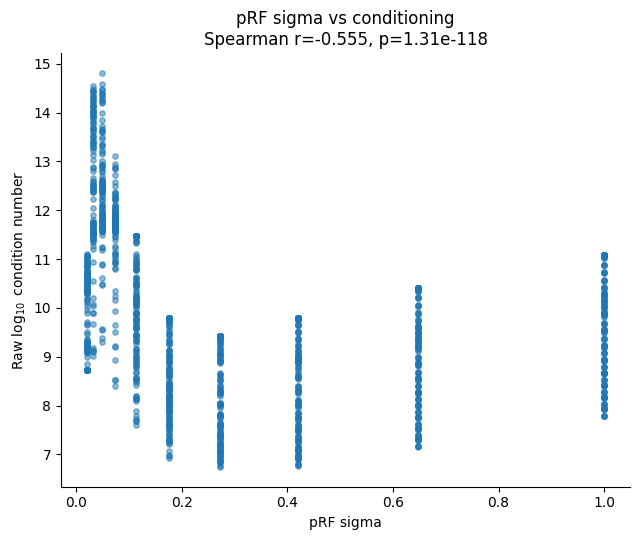

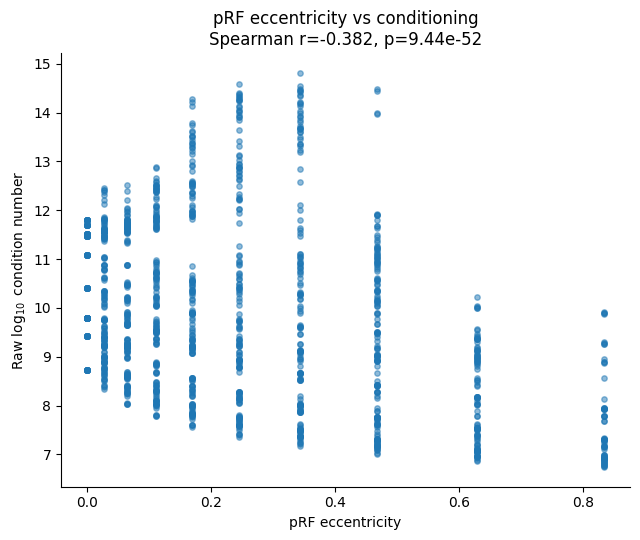

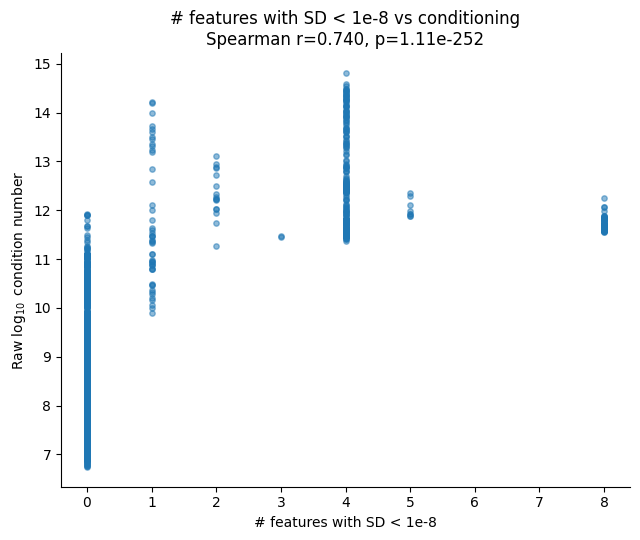

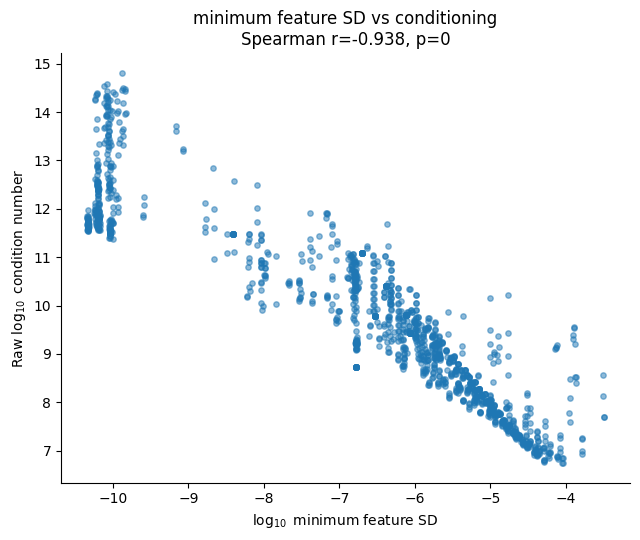

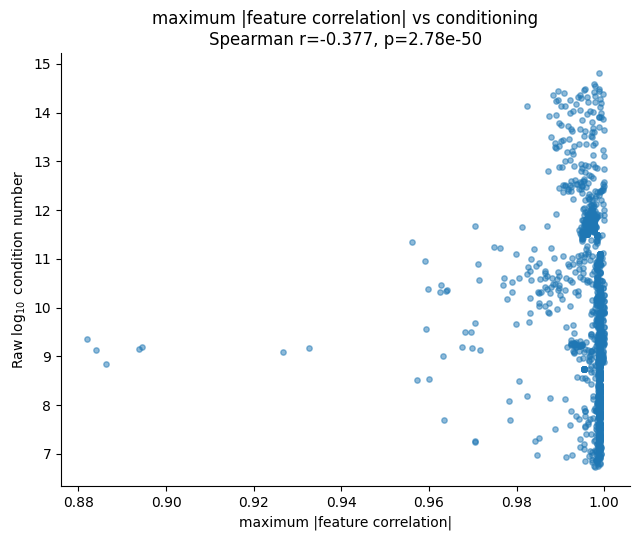

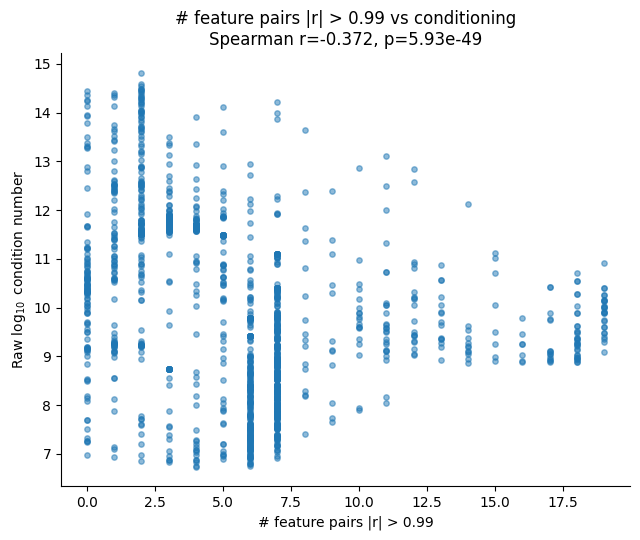

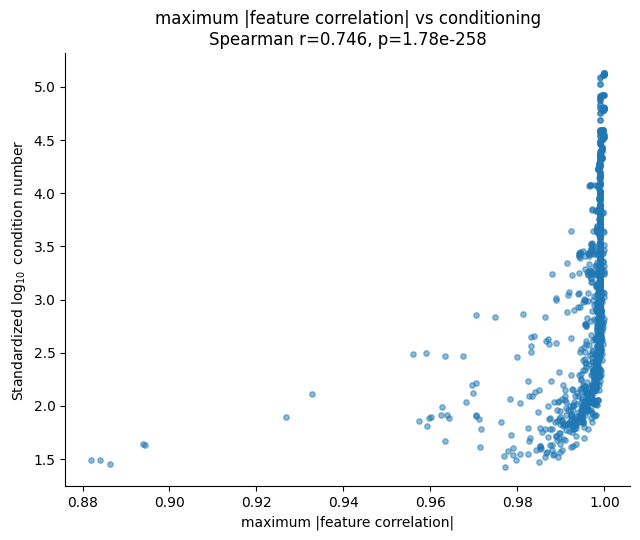

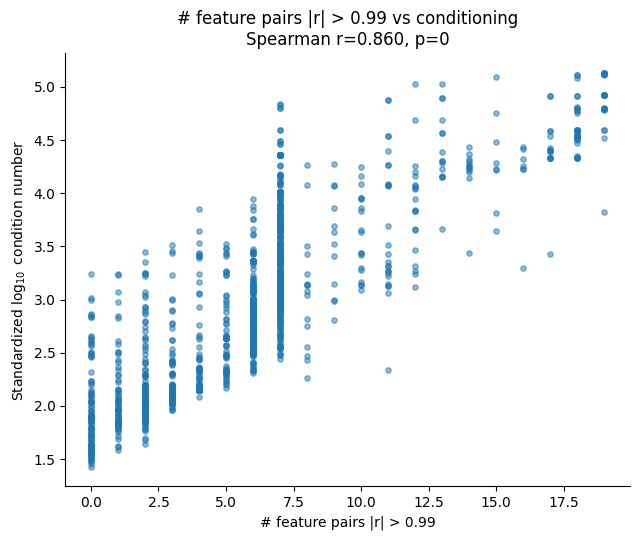

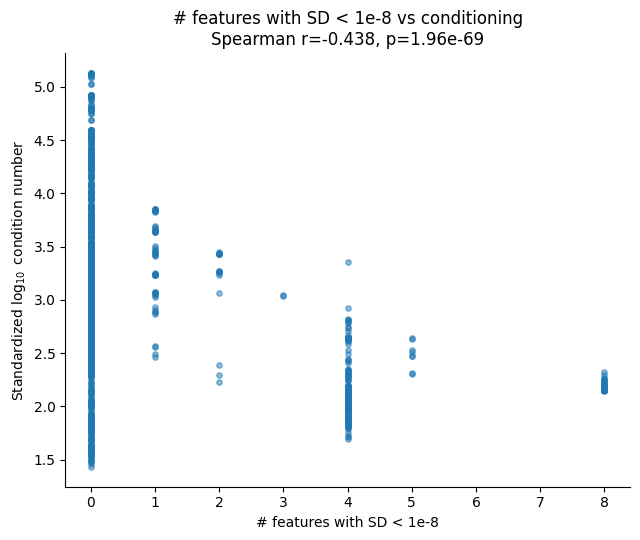


RAW vs STANDARDIZED CONDITIONING
Spearman: -0.24148635668675797 p = 9.166183902670514e-21
Pearson: -0.23040359264870275 p = 5.379592793426251e-19

DESCRIPTIVE MULTIVARIATE MODEL
Outcome: log10(raw condition number)
N pRFs: 1456
In-sample R²: 0.5191760922323521

Standardized predictor coefficients:


,predictor,standardized_coefficient,abs_standardized_coefficient
2,n_features_sd_lt_1e-08,1.032337,1.032337
1,prf_ecc,-0.406434,0.406434
3,max_abs_feature_corr,-0.215005,0.215005
0,prf_sigma,-0.191862,0.191862
4,n_feature_pairs_abs_r_gt_099,0.033641,0.033641



Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/conditioning_correlations.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/raw_conditioning_correlations_ranked.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/standardized_conditioning_correlations_ranked.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/raw_conditioning_multivariate_coefficients.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/prf_sigma_vs_log10_raw_condition.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/pre_regression_diagnostics/S01_pcaHL0/conditioning_explanatory_analysis/p

In [ ]:
# ============================================================
# QUANTIFY WHAT EXPLAINS POOR CONDITIONING
#
# Uses the existing prf_summary DataFrame from the previous
# pre-regression diagnostic.
#
# Questions:
#   - Is conditioning related to pRF sigma?
#   - Is it related to eccentricity?
#   - Is it related to near-zero feature dimensions?
#   - Is it related to feature collinearity?
#
# We calculate:
#   1. Spearman correlation
#   2. Pearson correlation
#   3. simple scatter plots
#
# No regression fitting is rerun.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr


# ============================================================
# CONFIG
# ============================================================

OUT_DIR_EXPLAIN = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "pre_regression_diagnostics"
    / "S01_pcaHL0"
    / "conditioning_explanatory_analysis"
)

OUT_DIR_EXPLAIN.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# DEPENDENT VARIABLES
#
# Raw conditioning is the main outcome.
# We also inspect standardized conditioning separately.
# ============================================================

CONDITION_VARS = {
    "raw_log10_condition":
        "log10_raw_condition",

    "standardized_log10_condition":
        "log10_standardized_condition",
}


# ============================================================
# POSSIBLE EXPLANATORY VARIABLES
# ============================================================

EXPLANATORY_VARS = {

    "pRF sigma":
        "prf_sigma",

    "pRF eccentricity":
        "prf_ecc",

    "# features SD < 1e-6":
        "n_features_sd_lt_1e-06",

    "# features SD < 1e-8":
        "n_features_sd_lt_1e-08",

    "# features SD < 1e-10":
        "n_features_sd_lt_1e-10",

    "minimum feature SD":
        "min_feature_sd",

    "median feature SD":
        "median_feature_sd",

    "maximum |feature correlation|":
        "max_abs_feature_corr",

    "# feature pairs |r| > 0.99":
        "n_feature_pairs_abs_r_gt_099",

    "# feature pairs |r| > 0.999":
        "n_feature_pairs_abs_r_gt_0999",
}


# ============================================================
# HELPER
# ============================================================

def safe_corr(
    x,
    y,
    method="spearman"
):

    x = np.asarray(
        x,
        dtype=np.float64
    )

    y = np.asarray(
        y,
        dtype=np.float64
    )

    good = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )

    x = x[
        good
    ]

    y = y[
        good
    ]


    if len(x) < 3:

        return (
            np.nan,
            np.nan,
            len(x)
        )


    if (
        np.std(x) == 0
        or
        np.std(y) == 0
    ):

        return (
            np.nan,
            np.nan,
            len(x)
        )


    if method == "spearman":

        r, p = spearmanr(
            x,
            y
        )

    elif method == "pearson":

        r, p = pearsonr(
            x,
            y
        )

    else:

        raise ValueError(
            method
        )


    return (
        float(r),
        float(p),
        len(x)
    )


# ============================================================
# CORRELATION TABLE
# ============================================================

rows = []


for condition_label, condition_col in CONDITION_VARS.items():

    y = prf_summary[
        condition_col
    ].to_numpy(
        dtype=np.float64
    )


    for predictor_label, predictor_col in EXPLANATORY_VARS.items():

        x = prf_summary[
            predictor_col
        ].to_numpy(
            dtype=np.float64
        )


        # ----------------------------------------------------
        # For SD variables, log-transform before correlation
        # because they span many orders of magnitude.
        # ----------------------------------------------------

        x_used = x.copy()
        transform = "none"


        if predictor_col in [
            "min_feature_sd",
            "median_feature_sd",
        ]:

            positive = (
                np.isfinite(
                    x_used
                )
                &
                (
                    x_used > 0
                )
            )

            x_used[
                positive
            ] = np.log10(
                x_used[
                    positive
                ]
            )

            x_used[
                ~positive
            ] = np.nan

            transform = "log10"


        spearman_r, spearman_p, n1 = (
            safe_corr(
                x_used,
                y,
                method="spearman"
            )
        )


        pearson_r, pearson_p, n2 = (
            safe_corr(
                x_used,
                y,
                method="pearson"
            )
        )


        rows.append({

            "conditioning_metric":
                condition_label,

            "predictor":
                predictor_label,

            "predictor_column":
                predictor_col,

            "predictor_transform":
                transform,

            "n":
                min(
                    n1,
                    n2
                ),

            "spearman_r":
                spearman_r,

            "spearman_p":
                spearman_p,

            "pearson_r":
                pearson_r,

            "pearson_p":
                pearson_p,
        })


corr_df = pd.DataFrame(
    rows
)


# ============================================================
# SORT BY ABSOLUTE SPEARMAN EFFECT
# ============================================================

corr_df[
    "abs_spearman_r"
] = np.abs(
    corr_df[
        "spearman_r"
    ]
)


corr_df = corr_df.sort_values(
    [
        "conditioning_metric",
        "abs_spearman_r",
    ],
    ascending=[
        True,
        False,
    ]
).reset_index(
    drop=True
)


print(
    "=" * 110
)

print(
    "CORRELATES OF CONDITIONING"
)

print(
    "=" * 110
)

display(
    corr_df
)


# ============================================================
# RAW CONDITIONING ONLY
# ============================================================

raw_corr = corr_df[
    corr_df[
        "conditioning_metric"
    ]
    ==
    "raw_log10_condition"
].copy()


print(
    "\n"
    +
    "=" * 110
)

print(
    "RAW CONDITIONING — RANKED BY |SPEARMAN r|"
)

print(
    "=" * 110
)

display(
    raw_corr[
        [
            "predictor",
            "n",
            "spearman_r",
            "spearman_p",
            "pearson_r",
            "pearson_p",
        ]
    ]
)


# ============================================================
# STANDARDIZED CONDITIONING ONLY
# ============================================================

std_corr = corr_df[
    corr_df[
        "conditioning_metric"
    ]
    ==
    "standardized_log10_condition"
].copy()


print(
    "\n"
    +
    "=" * 110
)

print(
    "STANDARDIZED CONDITIONING — RANKED BY |SPEARMAN r|"
)

print(
    "=" * 110
)

display(
    std_corr[
        [
            "predictor",
            "n",
            "spearman_r",
            "spearman_p",
            "pearson_r",
            "pearson_p",
        ]
    ]
)


# ============================================================
# SCATTER-PLOT HELPER
# ============================================================

def make_scatter(
    predictor_col,
    predictor_label,
    condition_col,
    condition_label,
    log_x=False,
):

    x = prf_summary[
        predictor_col
    ].to_numpy(
        dtype=np.float64
    )

    y = prf_summary[
        condition_col
    ].to_numpy(
        dtype=np.float64
    )


    if log_x:

        good_x = (
            np.isfinite(x)
            &
            (
                x > 0
            )
        )

        x_plot = np.full_like(
            x,
            np.nan
        )

        x_plot[
            good_x
        ] = np.log10(
            x[
                good_x
            ]
        )

        xlabel = (
            r"$\log_{10}$ "
            +
            predictor_label
        )

    else:

        x_plot = x

        xlabel = predictor_label


    good = (
        np.isfinite(
            x_plot
        )
        &
        np.isfinite(
            y
        )
    )


    xs = x_plot[
        good
    ]

    ys = y[
        good
    ]


    sr, sp = spearmanr(
        xs,
        ys
    )


    fig, ax = plt.subplots(
        figsize=(6.5, 5.5)
    )


    ax.scatter(
        xs,
        ys,
        s=15,
        alpha=0.5
    )


    ax.set_xlabel(
        xlabel
    )

    ax.set_ylabel(
        condition_label
    )

    ax.set_title(
        f"{predictor_label} vs conditioning\n"
        f"Spearman r={sr:.3f}, p={sp:.3g}"
    )


    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


    fig.tight_layout()


    safe_name = (
        predictor_col
        .replace(
            ">",
            "gt"
        )
        .replace(
            "<",
            "lt"
        )
        .replace(
            "|",
            ""
        )
    )


    fn = (
        OUT_DIR_EXPLAIN
        /
        f"{safe_name}_vs_{condition_col}.png"
    )


    fig.savefig(
        fn,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    return fn


# ============================================================
# PLOTS:
# RAW CONDITIONING
# ============================================================

plot_files = []


plot_files.append(
    make_scatter(

        "prf_sigma",
        "pRF sigma",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "prf_ecc",
        "pRF eccentricity",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "n_features_sd_lt_1e-08",
        "# features with SD < 1e-8",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "min_feature_sd",
        "minimum feature SD",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",

        log_x=True,
    )
)


plot_files.append(
    make_scatter(

        "max_abs_feature_corr",
        "maximum |feature correlation|",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "n_feature_pairs_abs_r_gt_099",
        "# feature pairs |r| > 0.99",

        "log10_raw_condition",
        r"Raw $\log_{10}$ condition number",
    )
)


# ============================================================
# PLOTS:
# STANDARDIZED CONDITIONING
#
# This is especially useful because once scale is removed,
# whatever relationship remains points more toward structural
# collinearity rather than feature magnitude.
# ============================================================

plot_files.append(
    make_scatter(

        "max_abs_feature_corr",
        "maximum |feature correlation|",

        "log10_standardized_condition",
        r"Standardized $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "n_feature_pairs_abs_r_gt_099",
        "# feature pairs |r| > 0.99",

        "log10_standardized_condition",
        r"Standardized $\log_{10}$ condition number",
    )
)


plot_files.append(
    make_scatter(

        "n_features_sd_lt_1e-08",
        "# features with SD < 1e-8",

        "log10_standardized_condition",
        r"Standardized $\log_{10}$ condition number",
    )
)


# ============================================================
# CORRELATION BETWEEN RAW AND STANDARDIZED CONDITIONING
# ============================================================

x = prf_summary[
    "log10_raw_condition"
].to_numpy(
    dtype=np.float64
)

y = prf_summary[
    "log10_standardized_condition"
].to_numpy(
    dtype=np.float64
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


sr, sp = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


pr, pp = pearsonr(
    x[
        good
    ],
    y[
        good
    ]
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "RAW vs STANDARDIZED CONDITIONING"
)

print(
    "=" * 110
)

print(
    "Spearman:",
    sr,
    "p =",
    sp
)

print(
    "Pearson:",
    pr,
    "p =",
    pp
)


# ============================================================
# OPTIONAL:
# SIMPLE MULTIVARIATE REGRESSION
#
# This is descriptive, not inferential.
# It asks how much raw conditioning can be jointly explained
# by pRF geometry + near-zero variance + collinearity.
#
# Predictors are z-scored here only so coefficients are
# comparable in magnitude.
# ============================================================

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score


model_df = prf_summary[
    [
        "log10_raw_condition",
        "prf_sigma",
        "prf_ecc",
        "n_features_sd_lt_1e-08",
        "max_abs_feature_corr",
        "n_feature_pairs_abs_r_gt_099",
    ]
].copy()


model_df = model_df.replace(
    [
        np.inf,
        -np.inf,
    ],
    np.nan
).dropna()


Y = model_df[
    "log10_raw_condition"
].to_numpy(
    dtype=np.float64
)


predictor_cols = [

    "prf_sigma",
    "prf_ecc",
    "n_features_sd_lt_1e-08",
    "max_abs_feature_corr",
    "n_feature_pairs_abs_r_gt_099",
]


X_model = model_df[
    predictor_cols
].to_numpy(
    dtype=np.float64
)


# Standardize predictors only for coefficient comparison
mu = np.mean(
    X_model,
    axis=0,
    keepdims=True
)

sd = np.std(
    X_model,
    axis=0,
    keepdims=True
)


good_sd = (
    sd > 0
)

Xz = (
    X_model
    -
    mu
) / (
    sd
    +
    1e-12
)


reg = LinearRegression()

reg.fit(
    Xz,
    Y
)


pred = reg.predict(
    Xz
)


model_r2 = r2_score(
    Y,
    pred
)


coef_df = pd.DataFrame({

    "predictor":
        predictor_cols,

    "standardized_coefficient":
        reg.coef_,
})


coef_df[
    "abs_standardized_coefficient"
] = np.abs(
    coef_df[
        "standardized_coefficient"
    ]
)


coef_df = coef_df.sort_values(
    "abs_standardized_coefficient",
    ascending=False
)


print(
    "\n"
    +
    "=" * 110
)

print(
    "DESCRIPTIVE MULTIVARIATE MODEL"
)

print(
    "=" * 110
)

print(
    "Outcome: log10(raw condition number)"
)

print(
    "N pRFs:",
    len(
        model_df
    )
)

print(
    "In-sample R²:",
    model_r2
)

print(
    "\nStandardized predictor coefficients:"
)

display(
    coef_df
)


# ============================================================
# SAVE
# ============================================================

corr_file = (
    OUT_DIR_EXPLAIN
    / "conditioning_correlations.csv"
)

raw_file = (
    OUT_DIR_EXPLAIN
    / "raw_conditioning_correlations_ranked.csv"
)

std_file = (
    OUT_DIR_EXPLAIN
    / "standardized_conditioning_correlations_ranked.csv"
)

coef_file = (
    OUT_DIR_EXPLAIN
    / "raw_conditioning_multivariate_coefficients.csv"
)


corr_df.to_csv(
    corr_file,
    index=False
)

raw_corr.to_csv(
    raw_file,
    index=False
)

std_corr.to_csv(
    std_file,
    index=False
)

coef_df.to_csv(
    coef_file,
    index=False
)


print(
    "\nSaved:"
)

print(
    corr_file
)

print(
    raw_file
)

print(
    std_file
)

print(
    coef_file
)

for fn in plot_files:
    print(
        fn
    )

# TEST 1: MAP COLLINEARITY ACROSS THE TS FEATURE SPACE

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FEATURE FILE
/content/drive/MyDrive/V2_drift/features/pyramid_texture/PCA_pcaHL_v0/S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py
Exists: True

FEATURE METADATA
 feature                        family simple_family  scale  orientation
       0                   pixel_stats         pixel    NaN          NaN
       1                   pixel_stats         pixel    NaN          NaN
       2                   pixel_stats         pixel    NaN          NaN
       3                   pixel_stats         pixel    NaN          NaN
       4                   pixel_stats         pixel    NaN          NaN
       5                   pixel_stats         pixel    NaN          NaN
       6               mean_magnitudes   energy-mean    0.0          0.0
       7               mean_magnitudes   energy-mean    0.0          1.0
       8               mean_magnitudes   energy-mean    0.

,feature_1,feature_2,family_1,family_2,scale_1,scale_2,orientation_1,orientation_2,n_prfs_abs_r_gt_099,pct_prfs_abs_r_gt_099,n_prfs_abs_r_gt_0999,pct_prfs_abs_r_gt_0999,max_abs_r
0,2,46,pixel_stats,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,1251,85.920330,234,16.071429,0.999196
1,3,47,pixel_stats,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,1062,72.939560,10,0.686813,0.999941
2,44,46,marginal_stats_lowpass_recons,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,1042,71.565934,0,0.000000,0.998120
3,42,44,marginal_stats_lowpass_recons,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,880,60.439560,0,0.000000,0.998247
4,45,47,marginal_stats_lowpass_recons,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,855,58.722527,6,0.412088,0.999647
5,2,44,pixel_stats,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,804,55.219780,0,0.000000,0.995310
6,3,45,pixel_stats,marginal_stats_lowpass_recons,NaN,NaN,NaN,NaN,455,31.250000,1,0.068681,0.999266
7,36,37,mean_realparts,mean_realparts,3.0,3.0,2.0,3.0,158,10.851648,48,3.296703,0.999978
8,35,36,mean_realparts,mean_realparts,3.0,3.0,1.0,2.0,157,10.782967,48,3.296703,0.999978
9,32,33,mean_realparts,mean_realparts,2.0,2.0,2.0,3.0,143,9.821429,43,2.953297,0.999972



FEATURES MOST OFTEN INVOLVED IN |r| > 0.99


,feature,family,simple_family,scale,orientation,n_occurrences_abs_r_gt_099,n_prfs_with_abs_r_gt_099,pct_prfs_with_abs_r_gt_099,median_abs_r_when_gt_099,max_abs_r
0,46,marginal_stats_lowpass_recons,marginal,NaN,NaN,2293,1261,86.607143,0.997804,0.999196
1,2,pixel_stats,pixel,NaN,NaN,2055,1251,85.920330,0.995654,0.999196
2,47,marginal_stats_lowpass_recons,marginal,NaN,NaN,1943,1084,74.450549,0.996418,0.999941
3,3,pixel_stats,pixel,NaN,NaN,1534,1063,73.008242,0.996800,0.999941
4,44,marginal_stats_lowpass_recons,marginal,NaN,NaN,2726,1055,72.458791,0.994927,0.998247
5,45,marginal_stats_lowpass_recons,marginal,NaN,NaN,1441,936,64.285714,0.994764,0.999979
6,42,marginal_stats_lowpass_recons,marginal,NaN,NaN,881,880,60.439560,0.994976,0.998247
7,37,mean_realparts,linear-mean,3.0,3.0,352,250,17.170330,0.997120,0.999978
8,35,mean_realparts,linear-mean,3.0,1.0,351,249,17.101648,0.997113,0.999978
9,31,mean_realparts,linear-mean,2.0,1.0,345,241,16.552198,0.996986,0.999972



FEATURE-FAMILY PAIRS FOR |r| > 0.99


,family_pair,n_occurrences,n_prfs,median_abs_r,max_abs_r
2,marginal <-> pixel,3589,1283,0.996243,0.999941
1,marginal <-> marginal,2960,1130,0.995571,0.999979
0,linear-mean <-> linear-mean,1788,263,0.996945,0.999978



SPECIFIC CHECK — FEATURES 34-37


,feature_1,feature_2,family_1,family_2,scale_1,scale_2,orientation_1,orientation_2,n_prfs_abs_r_gt_090,n_prfs_abs_r_gt_095,n_prfs_abs_r_gt_099,n_prfs_abs_r_gt_0999,max_abs_r
7,36,37,mean_realparts,mean_realparts,3.0,3.0,2.0,3.0,362,357,158,48,0.999978
8,35,36,mean_realparts,mean_realparts,3.0,3.0,1.0,2.0,361,356,157,48,0.999978
15,35,37,mean_realparts,mean_realparts,3.0,3.0,1.0,3.0,368,264,102,31,0.999911
18,34,37,mean_realparts,mean_realparts,3.0,3.0,0.0,3.0,208,172,92,22,0.999846
19,34,35,mean_realparts,mean_realparts,3.0,3.0,0.0,1.0,208,172,92,22,0.999846
42,32,36,mean_realparts,mean_realparts,2.0,3.0,2.0,2.0,192,190,0,0,0.968645
43,33,37,mean_realparts,mean_realparts,2.0,3.0,3.0,3.0,96,96,0,0,0.964471
44,31,35,mean_realparts,mean_realparts,2.0,3.0,1.0,1.0,96,96,0,0,0.963199
45,30,34,mean_realparts,mean_realparts,2.0,3.0,0.0,0.0,192,92,0,0,0.953591
62,28,36,mean_realparts,mean_realparts,1.0,3.0,2.0,2.0,188,0,0,0,0.926691


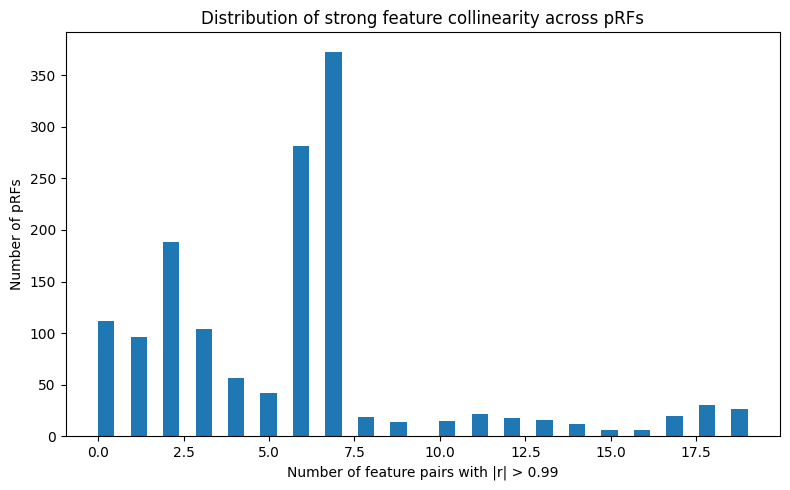

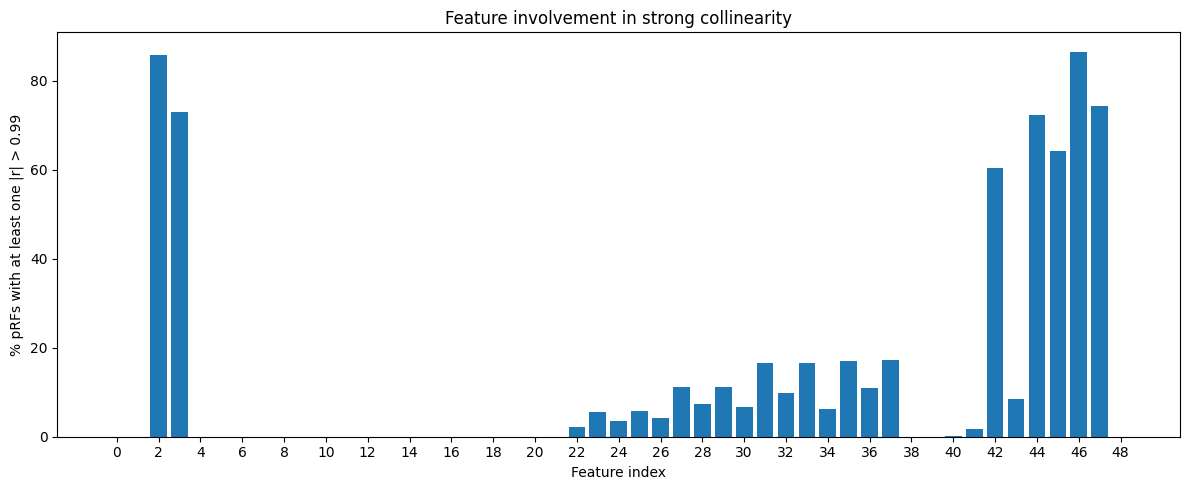

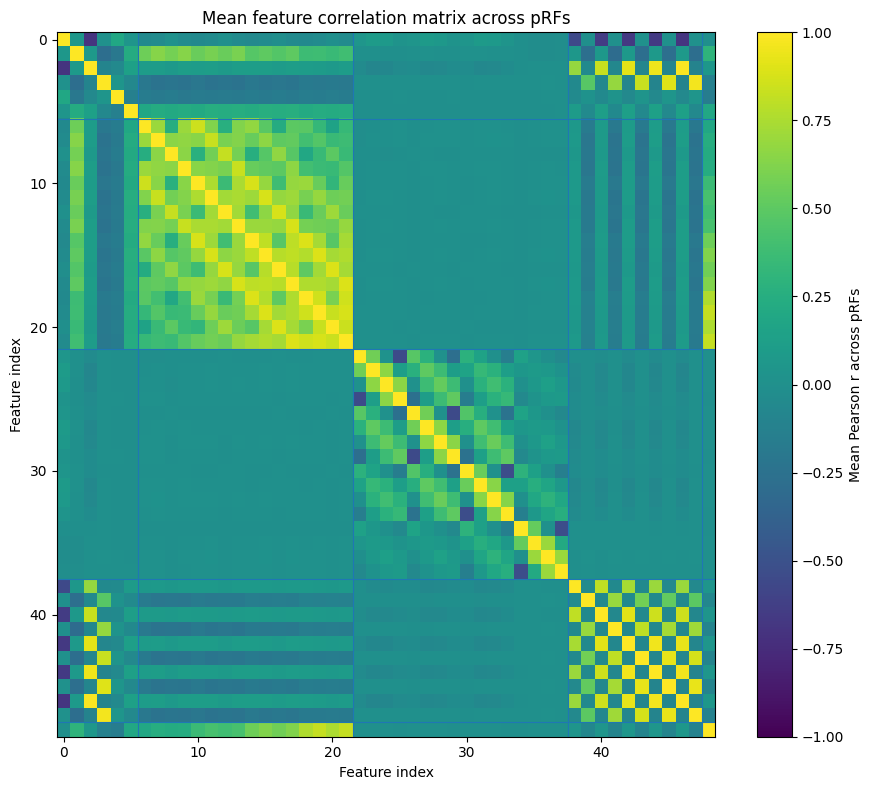

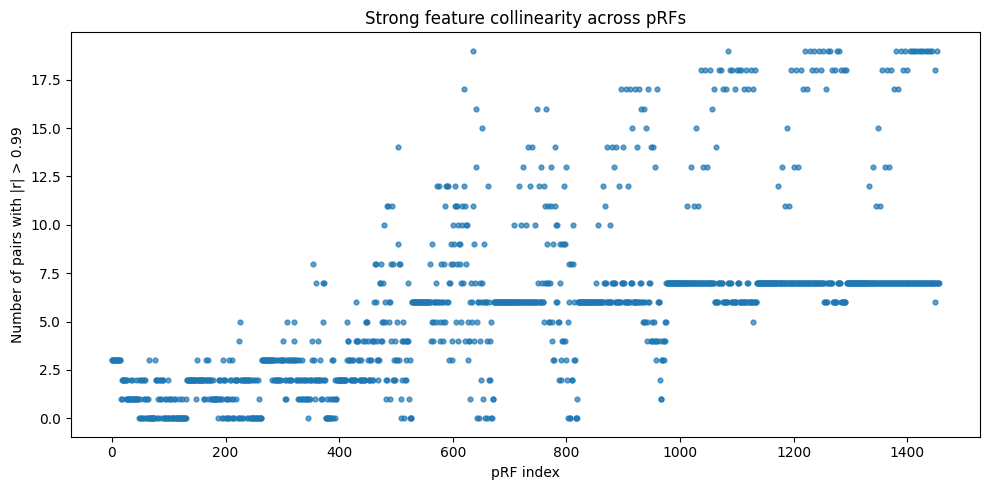


NEAR-ZERO VARIANCE vs COLLINEARITY
Spearman between # near-zero features and # pairs |r| > 0.99:
rho = -0.4371861289755497
p   = 5.079616917141296e-69

SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/per_prf_collinearity_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/high_correlation_pair_occurrences.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/feature_pair_collinearity_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/feature_collinearity_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/feature_family_collinearity_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/collinearity_diagnostics/S01_pcaHL0/mean_feature_correlation_matrix.npy

DONE.


In [ ]:
# ============================================================
# TEST 1: MAP COLLINEARITY ACROSS THE TS FEATURE SPACE
#
# S01
# pcaHL0 = 49 raw low-level features
# 4 orientations x 4 spatial-frequency scales
# grid5 = 1456 pRFs
#
# Questions:
# 1. Which feature pairs are highly correlated?
# 2. Which feature families are involved?
# 3. Is collinearity concentrated in particular scales/orientations?
# 4. Is it concentrated in particular pRFs?
# 5. Which pairs repeatedly become highly correlated across pRFs?
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1

FEATURE_FILE = (
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v0/"
    "S1_4ori_4sf_pcaHL_concat_v0pct_grid5.h5py"
)

# If your pcaHL0 file has a slightly different name,
# the automatic search below will try to find it.

FEATURE_DIR = (
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v0"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/V2_drift/texturemodel/"
    "drift_results/collinearity_diagnostics/S01_pcaHL0"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Correlation thresholds
THRESHOLDS = [0.90, 0.95, 0.99, 0.999]

# Near-zero SD threshold.
# Correlations involving essentially constant columns are not meaningful.
MIN_SD_FOR_CORR = 1e-10


# ============================================================
# FIND FEATURE FILE IF NEEDED
# ============================================================

if not os.path.exists(FEATURE_FILE):

    print("Configured feature file not found.")
    print("Searching directory:")
    print(FEATURE_DIR)

    candidates = []

    if os.path.exists(FEATURE_DIR):
        for fn in os.listdir(FEATURE_DIR):
            if (
                fn.endswith(".h5py")
                and "S1_" in fn
                and "4ori_4sf" in fn
                and "pcaHL" in fn
                and "grid5" in fn
            ):
                candidates.append(os.path.join(FEATURE_DIR, fn))

    print("\nCandidates:")
    for c in candidates:
        print(c)

    if len(candidates) == 1:
        FEATURE_FILE = candidates[0]
    elif len(candidates) == 0:
        raise FileNotFoundError(
            "Could not find the S01 pcaHL0 feature file."
        )
    else:
        raise RuntimeError(
            "More than one candidate found. "
            "Set FEATURE_FILE manually to the correct file."
        )


print("=" * 110)
print("FEATURE FILE")
print("=" * 110)
print(FEATURE_FILE)
print("Exists:", os.path.exists(FEATURE_FILE))


# ============================================================
# FEATURE METADATA
#
# 49 low-level features:
#
# 0-5   pixel_stats
# 6-21  mean_magnitudes
# 22-37 mean_realparts
# 38-47 marginal_stats_lowpass_recons
# 48    variance_highpass_resid
#
# For mean_magnitudes and mean_realparts:
# 4 scales x 4 orientations
# ============================================================

def get_feature_metadata(feature_idx):

    feature_idx = int(feature_idx)

    if 0 <= feature_idx <= 5:
        family = "pixel_stats"
        simple_family = "pixel"
        scale = np.nan
        orientation = np.nan

    elif 6 <= feature_idx <= 21:
        family = "mean_magnitudes"
        simple_family = "energy-mean"

        local_idx = feature_idx - 6
        scale = local_idx // 4
        orientation = local_idx % 4

    elif 22 <= feature_idx <= 37:
        family = "mean_realparts"
        simple_family = "linear-mean"

        local_idx = feature_idx - 22
        scale = local_idx // 4
        orientation = local_idx % 4

    elif 38 <= feature_idx <= 47:
        family = "marginal_stats_lowpass_recons"
        simple_family = "marginal"

        # These are not arranged as 4 orientations.
        scale = np.nan
        orientation = np.nan

    elif feature_idx == 48:
        family = "variance_highpass_resid"
        simple_family = "marginal"
        scale = np.nan
        orientation = np.nan

    else:
        family = "unknown"
        simple_family = "unknown"
        scale = np.nan
        orientation = np.nan

    return {
        "feature": feature_idx,
        "family": family,
        "simple_family": simple_family,
        "scale": scale,
        "orientation": orientation,
    }


feature_meta = pd.DataFrame(
    [get_feature_metadata(ii) for ii in range(49)]
)

print("\n" + "=" * 110)
print("FEATURE METADATA")
print("=" * 110)

print(feature_meta.to_string(index=False))


# ============================================================
# LOAD FEATURE DATASET
# ============================================================

h5 = h5py.File(FEATURE_FILE, "r")

print("\n" + "=" * 110)
print("HDF5 CONTENT")
print("=" * 110)

print("Keys:", list(h5.keys()))

if "features" not in h5:
    h5.close()
    raise KeyError(
        "Expected dataset 'features' was not found."
    )

X = h5["features"]

print("Feature matrix shape:", X.shape)
print("dtype:", X.dtype)

if len(X.shape) != 3:
    h5.close()
    raise ValueError(
        f"Expected 3D feature array, got shape {X.shape}"
    )

n_images, n_features, n_prfs = X.shape

print("N images:", n_images)
print("N features:", n_features)
print("N pRFs:", n_prfs)

if n_features != 49:
    h5.close()
    raise ValueError(
        f"Expected 49 pcaHL0 low-level features, got {n_features}"
    )


# ============================================================
# STORAGE
# ============================================================

# Per-pRF summary
prf_rows = []

# Every high-correlation pair
pair_rows = []

# How often each pair is highly correlated across pRFs
pair_counts = {}

# Sum correlations so we can construct an average correlation matrix
corr_sum = np.zeros((n_features, n_features), dtype=np.float64)
corr_count = np.zeros((n_features, n_features), dtype=np.int64)


# ============================================================
# LOOP OVER pRFs
# ============================================================

print("\n" + "=" * 110)
print("COMPUTING CORRELATIONS FOR ALL pRFs")
print("=" * 110)

for prf in range(n_prfs):

    if prf % 100 == 0:
        print(f"pRF {prf}/{n_prfs}")

    # Shape: images x features
    arr = np.asarray(X[:, :, prf], dtype=np.float64)

    # Remove images with any non-finite feature
    valid_rows = np.all(np.isfinite(arr), axis=1)
    arr = arr[valid_rows]

    if arr.shape[0] < 3:
        continue

    # SD per feature
    sd = np.std(arr, axis=0, ddof=0)

    usable = (
        np.isfinite(sd)
        & (sd > MIN_SD_FOR_CORR)
    )

    n_usable = int(np.sum(usable))
    n_near_zero = int(np.sum(sd <= MIN_SD_FOR_CORR))

    # Initialize full matrix with NaNs
    corr_full = np.full(
        (n_features, n_features),
        np.nan,
        dtype=np.float64
    )

    usable_inds = np.where(usable)[0]

    if len(usable_inds) >= 2:

        arr_use = arr[:, usable_inds]

        # Standard Pearson correlation between feature columns
        C = np.corrcoef(arr_use, rowvar=False)

        # Put back into full 49 x 49 matrix
        corr_full[
            np.ix_(usable_inds, usable_inds)
        ] = C

    # Accumulate average correlation matrix
    finite_corr = np.isfinite(corr_full)

    corr_sum[finite_corr] += corr_full[finite_corr]
    corr_count[finite_corr] += 1

    # Upper triangle only
    iu, ju = np.triu_indices(n_features, k=1)

    rvals = corr_full[iu, ju]

    valid_pairs = np.isfinite(rvals)

    ii = iu[valid_pairs]
    jj = ju[valid_pairs]
    rr = rvals[valid_pairs]

    abs_rr = np.abs(rr)

    if len(abs_rr) > 0:
        max_abs_r = float(np.max(abs_rr))
        median_abs_r = float(np.median(abs_rr))
    else:
        max_abs_r = np.nan
        median_abs_r = np.nan

    row = {
        "prf": prf,
        "n_images": arr.shape[0],
        "n_usable_features": n_usable,
        "n_near_zero_features": n_near_zero,
        "min_feature_sd": float(np.nanmin(sd)),
        "median_feature_sd": float(np.nanmedian(sd)),
        "max_abs_feature_corr": max_abs_r,
        "median_abs_feature_corr": median_abs_r,
    }

    for thr in THRESHOLDS:
        row[f"n_pairs_abs_r_gt_{thr}"] = int(
            np.sum(abs_rr > thr)
        )

    prf_rows.append(row)

    # Save detailed pairs for |r| > .90
    keep = abs_rr > 0.90

    for f1, f2, r in zip(
        ii[keep],
        jj[keep],
        rr[keep]
    ):

        meta1 = get_feature_metadata(f1)
        meta2 = get_feature_metadata(f2)

        pair_rows.append({
            "prf": prf,

            "feature_1": int(f1),
            "feature_2": int(f2),

            "r": float(r),
            "abs_r": float(abs(r)),

            "family_1": meta1["family"],
            "family_2": meta2["family"],

            "simple_family_1": meta1["simple_family"],
            "simple_family_2": meta2["simple_family"],

            "scale_1": meta1["scale"],
            "scale_2": meta2["scale"],

            "orientation_1": meta1["orientation"],
            "orientation_2": meta2["orientation"],
        })

        key = (int(f1), int(f2))

        if key not in pair_counts:
            pair_counts[key] = {
                "n_abs_r_gt_090": 0,
                "n_abs_r_gt_095": 0,
                "n_abs_r_gt_099": 0,
                "n_abs_r_gt_0999": 0,
                "sum_abs_r": 0.0,
                "max_abs_r": 0.0,
            }

        pair_counts[key]["n_abs_r_gt_090"] += 1
        pair_counts[key]["sum_abs_r"] += abs(r)
        pair_counts[key]["max_abs_r"] = max(
            pair_counts[key]["max_abs_r"],
            abs(r)
        )

        if abs(r) > 0.95:
            pair_counts[key]["n_abs_r_gt_095"] += 1

        if abs(r) > 0.99:
            pair_counts[key]["n_abs_r_gt_099"] += 1

        if abs(r) > 0.999:
            pair_counts[key]["n_abs_r_gt_0999"] += 1


h5.close()


# ============================================================
# DATAFRAMES
# ============================================================

prf_df = pd.DataFrame(prf_rows)
pairs_df = pd.DataFrame(pair_rows)

pair_summary_rows = []

for (f1, f2), vals in pair_counts.items():

    m1 = get_feature_metadata(f1)
    m2 = get_feature_metadata(f2)

    n090 = vals["n_abs_r_gt_090"]

    pair_summary_rows.append({
        "feature_1": f1,
        "feature_2": f2,

        "family_1": m1["family"],
        "family_2": m2["family"],

        "simple_family_1": m1["simple_family"],
        "simple_family_2": m2["simple_family"],

        "scale_1": m1["scale"],
        "scale_2": m2["scale"],

        "orientation_1": m1["orientation"],
        "orientation_2": m2["orientation"],

        "n_prfs_abs_r_gt_090": n090,
        "pct_prfs_abs_r_gt_090": 100 * n090 / n_prfs,

        "n_prfs_abs_r_gt_095":
            vals["n_abs_r_gt_095"],

        "pct_prfs_abs_r_gt_095":
            100 * vals["n_abs_r_gt_095"] / n_prfs,

        "n_prfs_abs_r_gt_099":
            vals["n_abs_r_gt_099"],

        "pct_prfs_abs_r_gt_099":
            100 * vals["n_abs_r_gt_099"] / n_prfs,

        "n_prfs_abs_r_gt_0999":
            vals["n_abs_r_gt_0999"],

        "pct_prfs_abs_r_gt_0999":
            100 * vals["n_abs_r_gt_0999"] / n_prfs,

        "mean_abs_r_when_gt_090":
            vals["sum_abs_r"] / n090,

        "max_abs_r":
            vals["max_abs_r"],
    })


pair_summary_df = pd.DataFrame(pair_summary_rows)

if len(pair_summary_df) > 0:
    pair_summary_df = pair_summary_df.sort_values(
        [
            "n_prfs_abs_r_gt_099",
            "n_prfs_abs_r_gt_095",
            "max_abs_r",
        ],
        ascending=False
    ).reset_index(drop=True)


# ============================================================
# FAMILY-PAIR SUMMARY
# ============================================================

if len(pairs_df) > 0:

    # Use only |r| > .99 for the main family summary
    p99 = pairs_df[pairs_df["abs_r"] > 0.99].copy()

    if len(p99) > 0:

        # Make family pair order symmetric
        p99["family_pair"] = p99.apply(
            lambda row:
                "  <->  ".join(
                    sorted([
                        row["simple_family_1"],
                        row["simple_family_2"]
                    ])
                ),
            axis=1
        )

        family_summary = (
            p99.groupby("family_pair")
            .agg(
                n_occurrences=("abs_r", "size"),
                n_prfs=("prf", "nunique"),
                median_abs_r=("abs_r", "median"),
                max_abs_r=("abs_r", "max"),
            )
            .reset_index()
            .sort_values(
                ["n_prfs", "n_occurrences"],
                ascending=False
            )
        )

    else:
        family_summary = pd.DataFrame()

else:
    p99 = pd.DataFrame()
    family_summary = pd.DataFrame()


# ============================================================
# FEATURE SUMMARY
# ============================================================

feature_rows = []

for feat in range(n_features):

    if len(p99) > 0:

        mask = (
            (p99["feature_1"] == feat)
            | (p99["feature_2"] == feat)
        )

        tmp = p99[mask]

        n_occurrences = len(tmp)
        n_prfs_feat = tmp["prf"].nunique()

        if len(tmp) > 0:
            median_abs_r = tmp["abs_r"].median()
            max_abs_r = tmp["abs_r"].max()
        else:
            median_abs_r = np.nan
            max_abs_r = np.nan

    else:
        n_occurrences = 0
        n_prfs_feat = 0
        median_abs_r = np.nan
        max_abs_r = np.nan

    meta = get_feature_metadata(feat)

    feature_rows.append({
        **meta,
        "n_occurrences_abs_r_gt_099":
            n_occurrences,

        "n_prfs_with_abs_r_gt_099":
            n_prfs_feat,

        "pct_prfs_with_abs_r_gt_099":
            100 * n_prfs_feat / n_prfs,

        "median_abs_r_when_gt_099":
            median_abs_r,

        "max_abs_r":
            max_abs_r,
    })


feature_summary = pd.DataFrame(feature_rows)

feature_summary = feature_summary.sort_values(
    "n_prfs_with_abs_r_gt_099",
    ascending=False
).reset_index(drop=True)


# ============================================================
# AVERAGE CORRELATION MATRIX
# ============================================================

mean_corr = np.full(
    (n_features, n_features),
    np.nan,
    dtype=np.float64
)

valid = corr_count > 0

mean_corr[valid] = (
    corr_sum[valid] /
    corr_count[valid]
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("\n" + "=" * 110)
print("PER-pRF COLLINEARITY SUMMARY")
print("=" * 110)

cols_show = [
    "n_usable_features",
    "n_near_zero_features",
    "max_abs_feature_corr",
    "median_abs_feature_corr",
    "n_pairs_abs_r_gt_0.9",
    "n_pairs_abs_r_gt_0.95",
    "n_pairs_abs_r_gt_0.99",
    "n_pairs_abs_r_gt_0.999",
]

print(prf_df[cols_show].describe().T)


print("\n" + "=" * 110)
print("TOP FEATURE PAIRS — MOST OFTEN |r| > 0.99")
print("=" * 110)

if len(pair_summary_df) > 0:

    display(
        pair_summary_df[
            [
                "feature_1",
                "feature_2",
                "family_1",
                "family_2",
                "scale_1",
                "scale_2",
                "orientation_1",
                "orientation_2",
                "n_prfs_abs_r_gt_099",
                "pct_prfs_abs_r_gt_099",
                "n_prfs_abs_r_gt_0999",
                "pct_prfs_abs_r_gt_0999",
                "max_abs_r",
            ]
        ].head(50)
    )


print("\n" + "=" * 110)
print("FEATURES MOST OFTEN INVOLVED IN |r| > 0.99")
print("=" * 110)

display(
    feature_summary.head(49)
)


print("\n" + "=" * 110)
print("FEATURE-FAMILY PAIRS FOR |r| > 0.99")
print("=" * 110)

if len(family_summary) > 0:
    display(family_summary)
else:
    print("No pairs exceeded |r| > 0.99.")


# ============================================================
# SPECIFIC CHECK: FEATURES 34-37
# ============================================================

print("\n" + "=" * 110)
print("SPECIFIC CHECK — FEATURES 34-37")
print("=" * 110)

if len(pair_summary_df) > 0:

    mask_3437 = (
        pair_summary_df["feature_1"].isin([34,35,36,37])
        | pair_summary_df["feature_2"].isin([34,35,36,37])
    )

    specific_3437 = pair_summary_df[
        mask_3437
    ].copy()

    display(
        specific_3437[
            [
                "feature_1",
                "feature_2",
                "family_1",
                "family_2",
                "scale_1",
                "scale_2",
                "orientation_1",
                "orientation_2",
                "n_prfs_abs_r_gt_090",
                "n_prfs_abs_r_gt_095",
                "n_prfs_abs_r_gt_099",
                "n_prfs_abs_r_gt_0999",
                "max_abs_r",
            ]
        ].head(100)
    )


# ============================================================
# PLOT 1:
# DISTRIBUTION OF NUMBER OF HIGHLY CORRELATED PAIRS PER pRF
# ============================================================

plt.figure(figsize=(8,5))

plt.hist(
    prf_df["n_pairs_abs_r_gt_0.99"],
    bins=40
)

plt.xlabel("Number of feature pairs with |r| > 0.99")
plt.ylabel("Number of pRFs")
plt.title("Distribution of strong feature collinearity across pRFs")

plt.tight_layout()

fn = os.path.join(
    OUTPUT_DIR,
    "distribution_pairs_abs_r_gt_099.png"
)

plt.savefig(fn, dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# PLOT 2:
# FEATURES MOST OFTEN INVOLVED IN HIGH CORRELATIONS
# ============================================================

plot_df = feature_summary.sort_values(
    "feature"
)

plt.figure(figsize=(12,5))

plt.bar(
    plot_df["feature"],
    plot_df["pct_prfs_with_abs_r_gt_099"]
)

plt.xlabel("Feature index")
plt.ylabel("% pRFs with at least one |r| > 0.99")
plt.title(
    "Feature involvement in strong collinearity"
)

plt.xticks(
    np.arange(0,49,2)
)

plt.tight_layout()

fn = os.path.join(
    OUTPUT_DIR,
    "feature_involvement_abs_r_gt_099.png"
)

plt.savefig(fn, dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# PLOT 3:
# MEAN FEATURE CORRELATION MATRIX
# ============================================================

plt.figure(figsize=(9,8))

im = plt.imshow(
    mean_corr,
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(
    im,
    label="Mean Pearson r across pRFs"
)

plt.xlabel("Feature index")
plt.ylabel("Feature index")
plt.title(
    "Mean feature correlation matrix across pRFs"
)

# Family boundaries
for boundary in [5.5, 21.5, 37.5, 47.5]:
    plt.axvline(boundary, linewidth=0.8)
    plt.axhline(boundary, linewidth=0.8)

plt.tight_layout()

fn = os.path.join(
    OUTPUT_DIR,
    "mean_feature_correlation_matrix.png"
)

plt.savefig(fn, dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# PLOT 4:
# pRF INDEX VS NUMBER OF HIGH-CORRELATION PAIRS
# ============================================================

plt.figure(figsize=(10,5))

plt.scatter(
    prf_df["prf"],
    prf_df["n_pairs_abs_r_gt_0.99"],
    s=12,
    alpha=0.7
)

plt.xlabel("pRF index")
plt.ylabel("Number of pairs with |r| > 0.99")
plt.title(
    "Strong feature collinearity across pRFs"
)

plt.tight_layout()

fn = os.path.join(
    OUTPUT_DIR,
    "collinearity_by_prf.png"
)

plt.savefig(fn, dpi=200, bbox_inches="tight")
plt.show()


# ============================================================
# RELATION BETWEEN NEAR-ZERO VARIANCE AND COLLINEARITY
# ============================================================

rho, p = spearmanr(
    prf_df["n_near_zero_features"],
    prf_df["n_pairs_abs_r_gt_0.99"],
    nan_policy="omit"
)

print("\n" + "=" * 110)
print("NEAR-ZERO VARIANCE vs COLLINEARITY")
print("=" * 110)

print(
    "Spearman between # near-zero features "
    "and # pairs |r| > 0.99:"
)
print("rho =", rho)
print("p   =", p)


# ============================================================
# SAVE EVERYTHING
# ============================================================

prf_file = os.path.join(
    OUTPUT_DIR,
    "per_prf_collinearity_summary.csv"
)

pair_file = os.path.join(
    OUTPUT_DIR,
    "high_correlation_pair_occurrences.csv"
)

pair_summary_file = os.path.join(
    OUTPUT_DIR,
    "feature_pair_collinearity_summary.csv"
)

feature_summary_file = os.path.join(
    OUTPUT_DIR,
    "feature_collinearity_summary.csv"
)

family_summary_file = os.path.join(
    OUTPUT_DIR,
    "feature_family_collinearity_summary.csv"
)

matrix_file = os.path.join(
    OUTPUT_DIR,
    "mean_feature_correlation_matrix.npy"
)

prf_df.to_csv(
    prf_file,
    index=False
)

pairs_df.to_csv(
    pair_file,
    index=False
)

pair_summary_df.to_csv(
    pair_summary_file,
    index=False
)

feature_summary.to_csv(
    feature_summary_file,
    index=False
)

family_summary.to_csv(
    family_summary_file,
    index=False
)

np.save(
    matrix_file,
    mean_corr
)


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(prf_file)
print(pair_file)
print(pair_summary_file)
print(feature_summary_file)
print(family_summary_file)
print(matrix_file)

print("\nDONE.")

# TEST 2:

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IMAGE SELECTION
Whole-data images: 9209
Images checked: 100
First indices: [0 1 2 3 4 5 6 7 8 9]

LOOKING FOR STIMULUS FILE
/content/drive/MyDrive/V2_drift/features/raw/S1_images.npy False
/content/drive/MyDrive/V1_Drift/NSD/stimuli/nsd_stimuli.hdf5 False
/content/drive/MyDrive/V1_Drift/NSD/stimuli/nsd_stimuli.npy False

Using project nsd_utils.

LOADING IMAGE PIXELS

GET_IMAGE_DATA SIGNATURE
(subject, random_images=False, native=False, npix=256)

Loading images for subject 1

image data size: (10000, 3, 256, 256) , dtype: uint8 , value range: 0 255
All subject images shape: (10000, 3, 256, 256)
Max requested image index: 108
Number of available subject images: 10000
Selected image shape: (100, 3, 256, 256)
dtype: uint8
Loaded image shape: (100, 3, 256, 256)
dtype: uint8

FORMATTING IMAGES FOR PYRAMID
Input shape: (100, 3, 256, 256)
Grayscale shape: (100, 256

,prf,prf_x,prf_y,prf_sigma,scale,orientation,final_feature_index,signed_mean_abs_median,unsigned_mean_median,signed_sd_across_images,unsigned_sd_across_images,median_cancellation_ratio,mean_cancellation_ratio,pct_images_ratio_lt_0.1,pct_images_ratio_lt_0.01,pct_images_ratio_lt_0.001
24,318,-7.816735e-02,7.816735e-02,0.047707,3,0,34,1.768622e-09,3.739034,3.261976e-09,2.263106,5.038810e-10,6.493149e-10,100.0,100.0,100.0
25,318,-7.816735e-02,7.816735e-02,0.047707,3,1,35,1.661381e-09,3.588680,3.101210e-09,1.921901,5.124203e-10,6.385551e-10,100.0,100.0,100.0
43,358,1.738543e-01,-1.738544e-01,0.047707,3,3,37,1.599215e-09,3.143182,3.388726e-09,2.108632,5.164569e-10,6.907919e-10,100.0,100.0,100.0
27,318,-7.816735e-02,7.816735e-02,0.047707,3,3,37,1.601742e-09,3.623566,3.463283e-09,2.089201,5.365484e-10,6.666586e-10,100.0,100.0,100.0
29,329,1.569238e-01,6.499998e-02,0.047707,3,1,35,1.688377e-09,3.124684,2.784894e-09,2.005495,5.563034e-10,6.771359e-10,100.0,100.0,100.0
26,318,-7.816735e-02,7.816735e-02,0.047707,3,2,36,1.901432e-09,3.826427,3.896247e-09,2.246012,5.569567e-10,6.834119e-10,100.0,100.0,100.0
28,329,1.569238e-01,6.499998e-02,0.047707,3,0,34,1.326344e-09,3.265381,3.843175e-09,2.436352,5.600335e-10,6.962330e-10,100.0,100.0,100.0
23,303,-5.937965e-02,2.459586e-02,0.047707,3,3,37,2.002935e-09,3.614856,4.034611e-09,2.171069,5.826460e-10,6.934382e-10,100.0,100.0,100.0
31,329,1.569238e-01,6.499998e-02,0.047707,3,3,37,1.492899e-09,3.406678,3.564542e-09,2.090216,5.839498e-10,6.960001e-10,100.0,100.0,100.0
30,329,1.569238e-01,6.499998e-02,0.047707,3,2,36,2.055678e-09,3.710917,3.865281e-09,2.521006,5.939598e-10,7.134003e-10,100.0,100.0,100.0



SUMMARY BY FEATURE / ORIENTATION


,final_feature_index,orientation,n_prfs,median_signed_sd,median_unsigned_sd,median_cancellation_ratio,median_pct_images_ratio_lt_01,median_pct_images_ratio_lt_001
0,34,0,13,5.558009e-09,2.284814,8.739843e-10,100.0,100.0
1,35,1,13,5.183754e-09,1.921901,7.647432e-10,100.0,100.0
2,36,2,13,5.505169e-09,2.345861,8.776020e-10,100.0,100.0
3,37,3,13,4.924621e-09,2.105159,8.537420e-10,100.0,100.0



CANCELLATION vs FINAL FEATURE SD
Spearman rho: 0.9591906428754374
p: 4.350780474953183e-29


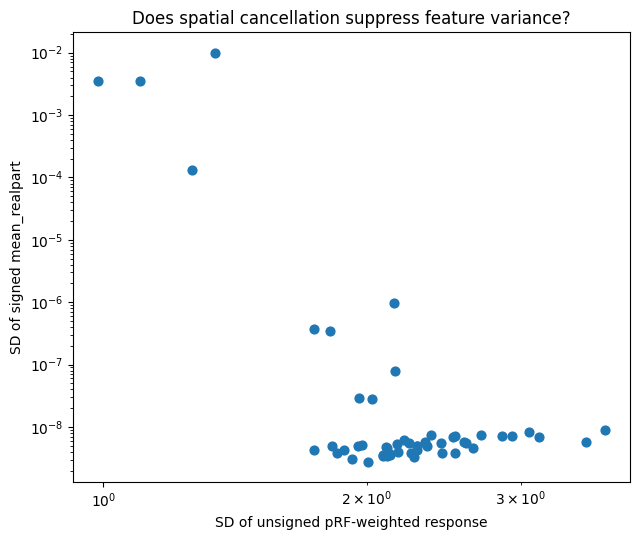

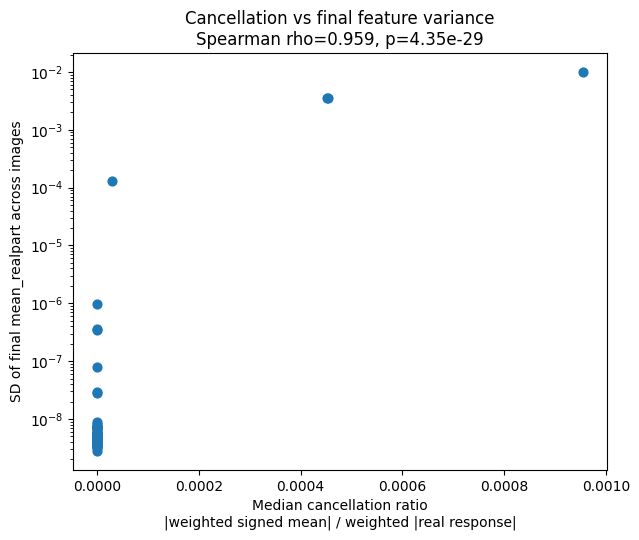

/tmp/ipykernel_3833/2200816824.py:999: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


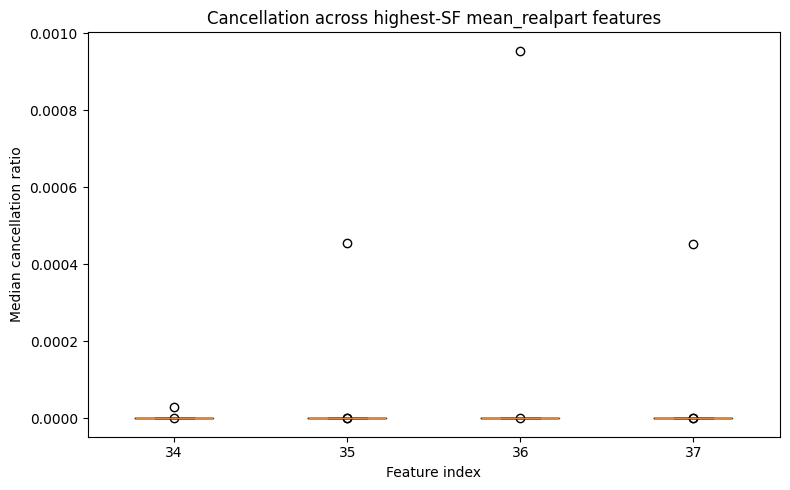


Saved:
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/cancellation_diagnostics/S01_scale3_mean_realparts/scale3_mean_realpart_cancellation_detail.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/cancellation_diagnostics/S01_scale3_mean_realparts/scale3_mean_realpart_cancellation_summary.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/cancellation_diagnostics/S01_scale3_mean_realparts/signed_vs_unsigned_sd.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/cancellation_diagnostics/S01_scale3_mean_realparts/cancellation_ratio_vs_feature_sd.png
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/cancellation_diagnostics/S01_scale3_mean_realparts/cancellation_by_feature.png

DONE.


In [ ]:
# ============================================================
# TEST 2:
# DOES pRF-WEIGHTED AVERAGING CREATE THE NEAR-ZERO
# mean_realparts FEATURES THROUGH POSITIVE/NEGATIVE CANCELLATION?
#
# Focus:
#   S01
#   highest-SF scale = scale 3
#   orientations 0-3
#   final features = 34-37
#
# We compare:
#
#   signed_mean =
#       sum(w * real_coeff)
#
#   unsigned_mean =
#       sum(w * abs(real_coeff))
#
# Strong cancellation means:
#
#   |signed_mean| << unsigned_mean
#
# No regression is run.
# ============================================================
from google.colab import drive
drive.mount("/content/drive", force_remount=False)

!pip install -q pyrtools

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# PATHS
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

PATHS_TO_ADD = [
    ROOT / "texturemodel",
    ROOT / "texturemodel" / "code",
    ROOT / "texturemodel" / "code" / "model_fitting",
]

for p in PATHS_TO_ADD:
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)


# ============================================================
# PROJECT IMPORTS
# ============================================================

from feature_extraction import texture_statistics_pyramid
from utils import prf_utils


# ============================================================
# CONFIG
# ============================================================

SUBJECT = 1

N_IMAGES = 100

# pRFs that already appeared among extreme-weight cases,
# plus several additional examples.
PRFS_TO_CHECK = [
    182,
    195,
    196,
    220,
    301,
    303,
    318,
    329,
    330,
    348,
    358,
    461,
    1292,
]

SCALE = 3

ORIENTATIONS = [0, 1, 2, 3]

EPS = 1e-12

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "cancellation_diagnostics"
    / "S01_scale3_mean_realparts"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# LOAD NSD IMAGE INDICES USED FOR THE SUBJECT
#
# We reuse the whole-data image order saved in your
# fixed-global-normalization file.
# ============================================================

GLOBAL_STATS_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "global_feature_zscore"
    / "S01_pcaHL0_4ori_4sf_grid5_wholedata_fixed_mean_std.npz"
)

G = np.load(
    GLOBAL_STATS_FILE,
    allow_pickle=True
)

image_order = np.asarray(
    G["image_order"],
    dtype=int
).reshape(-1)

unique_images = np.unique(
    image_order
)

images_test = unique_images[
    :N_IMAGES
]

print("=" * 100)
print("IMAGE SELECTION")
print("=" * 100)

print("Whole-data images:", len(unique_images))
print("Images checked:", len(images_test))
print("First indices:", images_test[:10])


# ============================================================
# LOAD NSD STIMULUS IMAGES
#
# IMPORTANT:
# change this path only if your NSD stimuli live elsewhere.
#
# Expected array shape:
# [n_images, height, width, channels]
# or similar.
#
# This section tries common paths.
# ============================================================

candidate_files = [

    ROOT
    / "features"
    / "raw"
    / "S1_images.npy",

    Path(
        "/content/drive/MyDrive/V1_Drift/NSD/"
        "stimuli/nsd_stimuli.hdf5"
    ),

    Path(
        "/content/drive/MyDrive/V1_Drift/NSD/"
        "stimuli/nsd_stimuli.npy"
    ),
]

print("\n" + "=" * 100)
print("LOOKING FOR STIMULUS FILE")
print("=" * 100)

for fn in candidate_files:
    print(fn, fn.exists())


# ============================================================
# TRY TO LOAD USING PROJECT nsd_utils
#
# This is usually safer than guessing the raw NSD path.
# ============================================================

try:

    from utils import nsd_utils

    print("\nUsing project nsd_utils.")

except Exception:

    try:

        import nsd_utils

        print("\nUsing nsd_utils.")

    except Exception as e:

        raise RuntimeError(
            "Could not import nsd_utils. "
            "Use the same import/path setup from your working "
            "feature extraction notebook."
        ) from e


# ============================================================
# LOAD IMAGE PIXELS
# ============================================================

print("\n" + "=" * 100)
print("LOADING IMAGE PIXELS")
print("=" * 100)


import inspect

print("\n" + "=" * 100)
print("GET_IMAGE_DATA SIGNATURE")
print("=" * 100)

print(inspect.signature(nsd_utils.get_image_data))

# Load all subject-specific NSD images
images_all = nsd_utils.get_image_data(
    SUBJECT,
    random_images=False,
    native=False,
    npix=256
)

images_all = np.asarray(
    images_all
)

print(
    "All subject images shape:",
    images_all.shape
)

print(
    "Max requested image index:",
    np.max(images_test)
)

print(
    "Number of available subject images:",
    images_all.shape[0]
)

assert np.max(images_test) < images_all.shape[0], (
    "The image indices in image_order do not match the indexing "
    "of the array returned by get_image_data()."
)

# Select only the images needed for this diagnostic
images = images_all[
    images_test
].copy()

# Free the full array
del images_all

print(
    "Selected image shape:",
    images.shape
)

print(
    "dtype:",
    images.dtype
)

images = np.asarray(
    images
)

print(
    "Loaded image shape:",
    images.shape
)

print(
    "dtype:",
    images.dtype
)


# ============================================================
# FORMAT FOR THE PYRAMID
#
# Expected input from nsd_utils:
# [batch, channels, H, W]
#
# texture_statistics_pyramid expects:
# [batch, 1, H, W]
# ============================================================

print("\n" + "=" * 100)
print("FORMATTING IMAGES FOR PYRAMID")
print("=" * 100)

print("Input shape:", images.shape)

# ------------------------------------------------------------
# Case 1:
# channels-first RGB:
# [batch, 3, H, W]
# ------------------------------------------------------------

if (
    images.ndim == 4
    and images.shape[1] == 3
):

    images = np.mean(
        images,
        axis=1
    )

# ------------------------------------------------------------
# Case 2:
# channels-last RGB:
# [batch, H, W, 3]
# ------------------------------------------------------------

elif (
    images.ndim == 4
    and images.shape[-1] == 3
):

    images = np.mean(
        images,
        axis=-1
    )

# ------------------------------------------------------------
# Case 3:
# already grayscale with singleton channel
# [batch, 1, H, W]
# ------------------------------------------------------------

elif (
    images.ndim == 4
    and images.shape[1] == 1
):

    images = images[:, 0, :, :]


if images.ndim != 3:

    raise ValueError(
        f"Unexpected image shape after grayscale conversion: "
        f"{images.shape}"
    )


images = images.astype(
    np.float32
)


# Add singleton channel dimension:
# [batch, 1, H, W]
images_pyr = images[
    :,
    None,
    :,
    :
]


print(
    "Grayscale shape:",
    images.shape
)

print(
    "Pyramid input shape:",
    images_pyr.shape
)

print(
    "dtype:",
    images_pyr.dtype
)

print(
    "value range:",
    np.min(images_pyr),
    np.max(images_pyr)
)


# ============================================================
# BUILD STEERABLE PYRAMID
# ============================================================

print("\n" + "=" * 100)
print("BUILDING STEERABLE PYRAMID")
print("=" * 100)


fmaps_fn = (
    texture_statistics_pyramid
    .steerable_pyramid_extractor(
        pyr_height=4,
        n_ori=4,
    )
)


fmaps = fmaps_fn(
    images_pyr,
    to_torch=False,
    device="cpu:0"
)


fmaps_complex = fmaps[0]


print(
    "Number of scales:",
    len(
        fmaps_complex
    )
)

for ss, arr in enumerate(
    fmaps_complex
):

    print(
        f"Scale {ss}:",
        arr.shape
    )


# ============================================================
# LOAD pRF GRID
#
# We use the same grid saved inside the whole-data model.
# ============================================================

WHOLE_FIT = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / "S01"
    / "texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca0_use_nsd_grid5_pRFs"
    / "Aug-23-2026_0856_24"
    / "all_fit_params.npy"
)


D = np.load(
    WHOLE_FIT,
    allow_pickle=True
).item()


prf_models = np.asarray(
    D["models"],
    dtype=np.float64
)


print("\n" + "=" * 100)
print("pRF GRID")
print("=" * 100)

print(
    "Shape:",
    prf_models.shape
)


# ============================================================
# COMPUTE CANCELLATION
# ============================================================

rows = []


scale_maps = (
    fmaps_complex[
        SCALE
    ]
)


# shape:
# images x orientations x H x W
n_trials = scale_maps.shape[0]
n_ori = scale_maps.shape[1]
n_pix = scale_maps.shape[2]


print("\n" + "=" * 100)
print("CANCELLATION ANALYSIS")
print("=" * 100)

print(
    "Scale:",
    SCALE
)

print(
    "Map shape:",
    scale_maps.shape
)


for prf in PRFS_TO_CHECK:

    x, y, sigma = (
        prf_models[
            prf,
            :3
        ]
    )


    spatial_weights = (
        prf_utils.gauss_2d(
            center=[
                x,
                y
            ],
            sd=sigma,
            patch_size=n_pix,
            aperture=1.0,
            dtype=np.float32,
        )
    )


    # normalize exactly like mean_realparts code
    spatial_weights = (
        spatial_weights
        /
        np.sum(
            spatial_weights
        )
    )


    for ori in ORIENTATIONS:

        real_map = np.real(
            scale_maps[
                :,
                ori,
                :,
                :
            ]
        ).astype(
            np.float64
        )


        # ----------------------------------------------------
        # signed pRF weighted mean
        #
        # equivalent to mean_realparts
        # ----------------------------------------------------

        signed_mean = np.sum(
            real_map
            *
            spatial_weights[
                None,
                :,
                :
            ],
            axis=(
                1,
                2
            )
        )


        # ----------------------------------------------------
        # unsigned weighted mean
        #
        # how much real-part response is actually present
        # if positive and negative values cannot cancel.
        # ----------------------------------------------------

        unsigned_mean = np.sum(
            np.abs(
                real_map
            )
            *
            spatial_weights[
                None,
                :,
                :
            ],
            axis=(
                1,
                2
            )
        )


        # ----------------------------------------------------
        # cancellation ratio
        #
        # 1 = no cancellation
        # 0 = nearly complete cancellation
        # ----------------------------------------------------

        cancellation_ratio = (
            np.abs(
                signed_mean
            )
            /
            (
                unsigned_mean
                +
                EPS
            )
        )


        # ----------------------------------------------------
        # variability across images
        # ----------------------------------------------------

        signed_sd = np.std(
            signed_mean,
            ddof=0
        )

        unsigned_sd = np.std(
            unsigned_mean,
            ddof=0
        )


        rows.append({

            "prf":
                prf,

            "prf_x":
                x,

            "prf_y":
                y,

            "prf_sigma":
                sigma,

            "scale":
                SCALE,

            "orientation":
                ori,

            "final_feature_index":
                34 + ori,

            "signed_mean_abs_median":
                np.median(
                    np.abs(
                        signed_mean
                    )
                ),

            "unsigned_mean_median":
                np.median(
                    unsigned_mean
                ),

            "signed_sd_across_images":
                signed_sd,

            "unsigned_sd_across_images":
                unsigned_sd,

            "median_cancellation_ratio":
                np.median(
                    cancellation_ratio
                ),

            "mean_cancellation_ratio":
                np.mean(
                    cancellation_ratio
                ),

            "pct_images_ratio_lt_0.1":
                100
                *
                np.mean(
                    cancellation_ratio
                    <
                    0.1
                ),

            "pct_images_ratio_lt_0.01":
                100
                *
                np.mean(
                    cancellation_ratio
                    <
                    0.01
                ),

            "pct_images_ratio_lt_0.001":
                100
                *
                np.mean(
                    cancellation_ratio
                    <
                    0.001
                ),
        })


result_df = pd.DataFrame(
    rows
)


# ============================================================
# PRINT
# ============================================================

print("\n" + "=" * 100)
print("CANCELLATION RESULTS")
print("=" * 100)

display(
    result_df.sort_values(
        [
            "median_cancellation_ratio",
            "signed_sd_across_images",
        ]
    )
)


# ============================================================
# SUMMARY BY FEATURE / ORIENTATION
# ============================================================

orientation_summary = (
    result_df
    .groupby(
        [
            "final_feature_index",
            "orientation",
        ]
    )
    .agg(

        n_prfs=(
            "prf",
            "nunique"
        ),

        median_signed_sd=(
            "signed_sd_across_images",
            "median"
        ),

        median_unsigned_sd=(
            "unsigned_sd_across_images",
            "median"
        ),

        median_cancellation_ratio=(
            "median_cancellation_ratio",
            "median"
        ),

        median_pct_images_ratio_lt_01=(
            "pct_images_ratio_lt_0.1",
            "median"
        ),

        median_pct_images_ratio_lt_001=(
            "pct_images_ratio_lt_0.01",
            "median"
        ),
    )
    .reset_index()
)


print("\n" + "=" * 100)
print("SUMMARY BY FEATURE / ORIENTATION")
print("=" * 100)

display(
    orientation_summary
)


# ============================================================
# DOES LOW SIGNED SD TRACK CANCELLATION?
# ============================================================

from scipy.stats import spearmanr


rho, p = spearmanr(
    result_df[
        "median_cancellation_ratio"
    ],
    result_df[
        "signed_sd_across_images"
    ],
    nan_policy="omit"
)


print("\n" + "=" * 100)
print("CANCELLATION vs FINAL FEATURE SD")
print("=" * 100)

print(
    "Spearman rho:",
    rho
)

print(
    "p:",
    p
)


# ============================================================
# FIGURE 1:
# SIGNED vs UNSIGNED SD
# ============================================================

plt.figure(
    figsize=(
        6.5,
        5.5
    )
)

plt.scatter(
    result_df[
        "unsigned_sd_across_images"
    ],
    result_df[
        "signed_sd_across_images"
    ],
    s=40
)

plt.xscale(
    "log"
)

plt.yscale(
    "log"
)

plt.xlabel(
    "SD of unsigned pRF-weighted response"
)

plt.ylabel(
    "SD of signed mean_realpart"
)

plt.title(
    "Does spatial cancellation suppress feature variance?"
)

plt.tight_layout()


fn1 = (
    OUT_DIR
    / "signed_vs_unsigned_sd.png"
)

plt.savefig(
    fn1,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2:
# CANCELLATION RATIO vs FINAL FEATURE SD
# ============================================================

plt.figure(
    figsize=(
        6.5,
        5.5
    )
)

plt.scatter(
    result_df[
        "median_cancellation_ratio"
    ],
    result_df[
        "signed_sd_across_images"
    ],
    s=40
)

plt.yscale(
    "log"
)

plt.xlabel(
    "Median cancellation ratio\n"
    "|weighted signed mean| / weighted |real response|"
)

plt.ylabel(
    "SD of final mean_realpart across images"
)

plt.title(
    f"Cancellation vs final feature variance\n"
    f"Spearman rho={rho:.3f}, p={p:.3g}"
)

plt.tight_layout()


fn2 = (
    OUT_DIR
    / "cancellation_ratio_vs_feature_sd.png"
)

plt.savefig(
    fn2,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3:
# CANCELLATION BY FEATURE 34-37
# ============================================================

plt.figure(
    figsize=(
        8,
        5
    )
)


data_to_plot = [
    result_df.loc[
        result_df[
            "final_feature_index"
        ]
        ==
        f,
        "median_cancellation_ratio"
    ].to_numpy()

    for f in [
        34,
        35,
        36,
        37
    ]
]


plt.boxplot(
    data_to_plot,
    labels=[
        "34",
        "35",
        "36",
        "37",
    ]
)


plt.xlabel(
    "Feature index"
)

plt.ylabel(
    "Median cancellation ratio"
)

plt.title(
    "Cancellation across highest-SF mean_realpart features"
)

plt.tight_layout()


fn3 = (
    OUT_DIR
    / "cancellation_by_feature.png"
)

plt.savefig(
    fn3,
    dpi=250,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# SAVE
# ============================================================

detail_file = (
    OUT_DIR
    / "scale3_mean_realpart_cancellation_detail.csv"
)

summary_file = (
    OUT_DIR
    / "scale3_mean_realpart_cancellation_summary.csv"
)


result_df.to_csv(
    detail_file,
    index=False
)

orientation_summary.to_csv(
    summary_file,
    index=False
)


print("\nSaved:")
print(detail_file)
print(summary_file)
print(fn1)
print(fn2)
print(fn3)

print("\nDONE.")

# Test 3

Mounted at /content/drive
FAST FILE SEARCH
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_2x2_cross_session.h5py
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py


USING:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py
pRF diagnostic index range: 0 to 1455

pRF DIAGNOSTIC
Rows: 1456
Columns:
['prf', 'prf_x', 'prf_y', 'prf_sigma', 'prf_ecc', 'min_feature_sd', 'median_feature_sd', 'raw_condition', 'log10_raw_condition', 'standardized_condition', 'log10_standardized_condition', 'raw_sigma_min', 'standardized_sigma_min', 'raw_rank', 'standardized_rank', 'max_abs_feature_corr', 'n_feature_pairs_abs_r_gt_099', 'n_feature_pairs_abs_r_gt_0999', 'n

,voxel,voxel_index,prf,raw_log10_condition,standardized_log10_condition,min_feature_sd,n_features_sd_lt_1e-08,max_abs_feature_corr,n_pairs_abs_r_gt_099,median_weight_pearson_all,median_weight_cosine_all,median_relative_weight_change_all,median_weight_pearson_LL,median_weight_cosine_LL,median_relative_weight_change_LL,median_weight_norm,weight_norm_mean,weight_norm_sd,weight_norm_cv,max_abs_weight
0,0,267967,968,6.843785,2.387601,9.036636e-05,0.0,0.998326,3.0,-0.029246,-0.029957,1.667291,-0.030012,-0.029957,1.667291,3.083579e+06,3.477071e+06,2.458082e+06,0.706941,7.690844e+06
1,1,268049,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,-0.014688,-0.009193,1.559752,-0.013928,-0.009193,1.559752,1.494425e+08,1.588154e+08,7.720115e+07,0.486106,2.770410e+08
2,2,268131,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,-0.001375,0.002946,1.528331,-0.001782,0.002946,1.528331,1.309445e+08,1.762517e+08,1.096034e+08,0.621857,3.407917e+08
3,3,268132,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,-0.033457,-0.041623,1.516444,-0.032306,-0.041623,1.516444,1.289315e+08,1.412576e+08,6.350634e+07,0.449578,2.101366e+08
4,4,268293,304,11.912627,2.165348,6.232818e-11,4.0,0.996340,2.0,0.008247,0.001463,1.442360,0.011594,0.001463,1.442360,2.203090e+11,2.333565e+11,8.029840e+10,0.344102,3.022654e+11



VAL_R2 SHAPE INTERPRETATION
val_r2 shape: (30, 30, 1350, 1)
Squeezed shape: (30, 30, 1350)
Normalized val_r2: (30, 30, 1350) (train x test x voxel)

CONDITIONING vs WEIGHT INSTABILITY


,predictor,outcome,n,spearman_r,spearman_p,pearson_r,pearson_p
36,min_feature_sd,max_abs_weight,1350,-0.902445,0.000000e+00,-0.128786,2.061588e-06
35,raw_log10_condition,max_abs_weight,1350,0.858510,0.000000e+00,0.545958,1.002467e-105
37,n_features_sd_lt_1e-08,max_abs_weight,1350,0.852286,0.000000e+00,0.696628,1.219943e-196
32,n_features_sd_lt_1e-08,weight_norm_cv,1350,-0.463381,8.233246e-73,-0.493553,8.384489e-84
27,n_features_sd_lt_1e-08,median_relative_weight_change_LL,1350,-0.358264,3.717411e-42,-0.350385,2.810781e-40
12,n_features_sd_lt_1e-08,median_relative_weight_change_all,1350,-0.358264,3.717411e-42,-0.350385,2.810781e-40
31,min_feature_sd,weight_norm_cv,1350,0.350239,3.040899e-40,-0.019928,4.644203e-01
34,n_pairs_abs_r_gt_099,weight_norm_cv,1350,0.319322,2.234122e-33,0.394103,2.143746e-51
29,n_pairs_abs_r_gt_099,median_relative_weight_change_LL,1350,0.274492,9.219204e-25,0.318450,3.401251e-33
14,n_pairs_abs_r_gt_099,median_relative_weight_change_all,1350,0.274492,9.219204e-25,0.318450,3.401251e-33



CONDITIONING vs PREDICTION PERFORMANCE


,predictor,outcome,n,spearman_r,spearman_p,pearson_r,pearson_p
15,raw_log10_condition,sd_cross_session_r2,1350,0.576637,1.783347e-120,0.234266,2.753723e-18
5,raw_log10_condition,sd_same_session_r2,1350,0.300200,1.628058e-29,0.286059,7.713224e-27
0,raw_log10_condition,median_same_session_r2,1350,0.286237,7.153951e-27,0.271720,2.805419e-24
16,min_feature_sd,sd_cross_session_r2,1350,-0.285711,8.936915e-27,-0.050002,6.626375e-02
19,n_pairs_abs_r_gt_099,sd_cross_session_r2,1350,-0.186120,5.483049e-12,-0.022395,4.109784e-01
6,min_feature_sd,sd_same_session_r2,1350,-0.184557,8.284454e-12,-0.097535,3.320705e-04
17,n_features_sd_lt_1e-08,sd_cross_session_r2,1350,0.182379,1.463171e-11,0.007927,7.710510e-01
1,min_feature_sd,median_same_session_r2,1350,-0.161619,2.342546e-09,-0.053006,5.152086e-02
9,n_pairs_abs_r_gt_099,sd_same_session_r2,1350,-0.160045,3.356525e-09,-0.105531,1.024433e-04
7,n_features_sd_lt_1e-08,sd_same_session_r2,1350,0.145891,7.274343e-08,0.102122,1.709066e-04



PRIMARY TEST
raw log10(condition)
vs median session-pair weight cosine similarity
Spearman rho = -0.023620097818118944
p = 0.3858462011037901


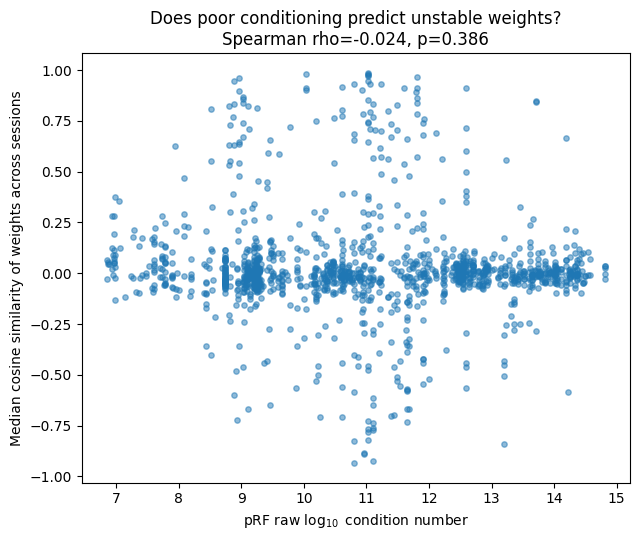

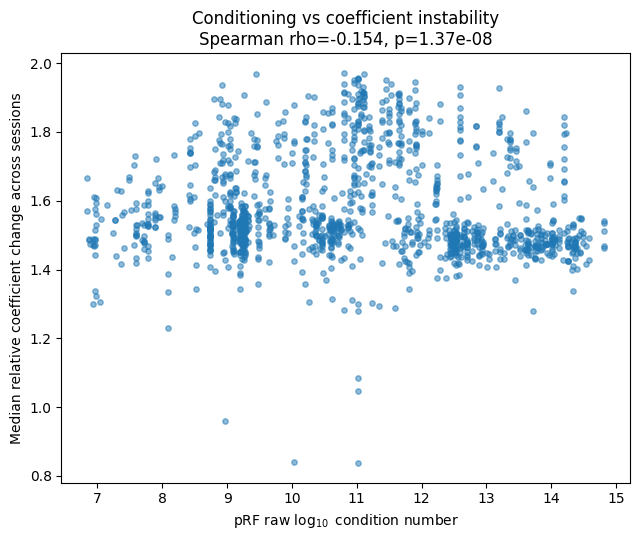

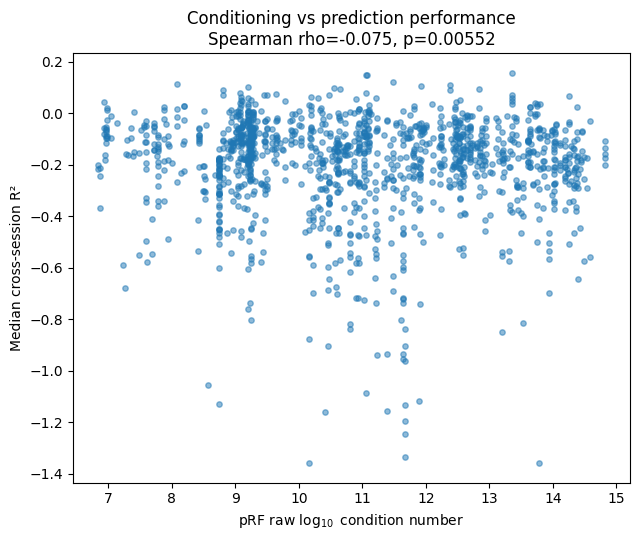

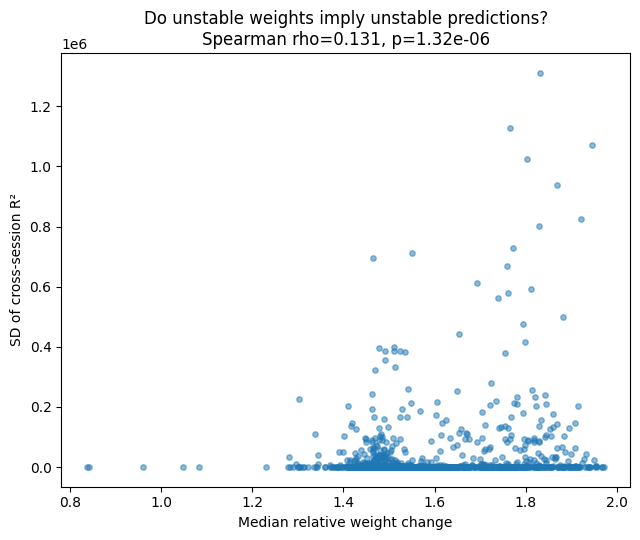


BEST vs WORST CONDITIONED VOXELS


,group,n_voxels,median_weight_cosine_LL,median_relative_weight_change_LL,median_cross_session_r2,median_sd_cross_session_r2
0,best-conditioned 25%,338,0.000015,1.533311,-0.138710,1.437292
1,worst-conditioned 25%,339,-0.002255,1.487510,-0.167696,6136.326172



SENSITIVITY TO REMOVING WORST-CONDITIONED VOXELS


,worst_conditioning_removed_pct,n_voxels_remaining,condition_cutoff,median_weight_cosine_LL,median_relative_weight_change_LL,median_weight_norm_cv,median_cross_session_r2,median_cross_session_r2_sd
0,0,1350,inf,-0.003496,1.527286,0.510381,-0.152895,36.177402
1,10,1217,13.749018,-0.004397,1.532704,0.525780,-0.148217,12.949844
2,20,1080,12.844521,-0.003031,1.538873,0.539564,-0.146646,5.193243
3,30,945,12.249557,-0.007587,1.548095,0.561712,-0.148259,5.981285
4,40,815,11.489881,-0.007514,1.544126,0.550324,-0.145603,5.460952
5,50,677,10.862877,-0.006790,1.532704,0.521640,-0.143162,2.733963


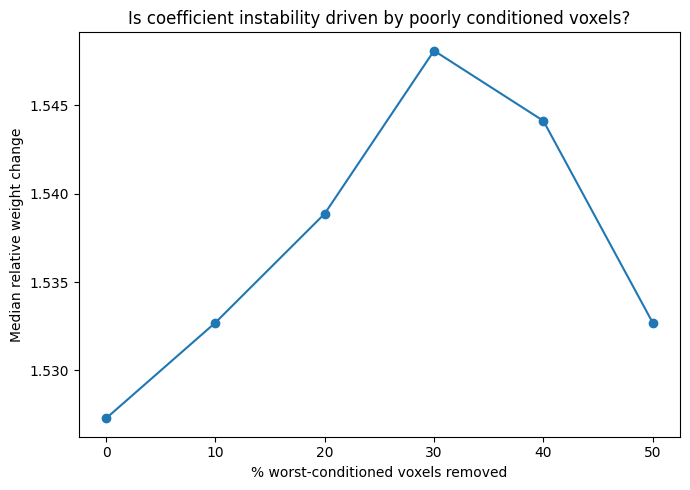


SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_identifiability/S01_V1_pcaHL95/voxel_conditioning_weight_prediction_stability.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_identifiability/S01_V1_pcaHL95/conditioning_vs_weight_stability.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_identifiability/S01_V1_pcaHL95/conditioning_vs_prediction_stability.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_identifiability/S01_V1_pcaHL95/best_vs_worst_conditioned_voxels.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/weight_identifiability/S01_V1_pcaHL95/conditioning_sensitivity_analysis.csv

DONE.


In [ ]:
# ============================================================
# TEST 3:
# DOES POOR FEATURE CONDITIONING PRODUCE APPARENT
# SESSION-TO-SESSION WEIGHT INSTABILITY?
#
# Core question:
#
#   poor conditioning
#           ↓
#   unstable OLS coefficient vectors across sessions
#
# while:
#
#   prediction performance remains comparatively stable
#
# This uses EXISTING FAST cross-session fits.
# No model is refit.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import spearmanr, pearsonr


# ============================================================
# CONFIG
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

SUBJECT = 1
ROI = "V1"

# ------------------------------------------------------------
# IMPORTANT:
# Use the actual cross-session model whose drift you ultimately
# want to interpret.
#
# Your existing main FAST fit was pcaHL95, zscore_features=0.
# ------------------------------------------------------------

PCA_PCT = 95
PCA_TYPE = "pcaHL"

N_SESSIONS = 30

# We will focus separately on:
#   ALL fitted dimensions
#   low-level raw TS dimensions 0:49
#
N_LOW_LEVEL = 49


# ============================================================
# FAST FILE
# ============================================================

FAST_DIR = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / f"S{SUBJECT:02d}"
    / "FAST_CROSS_SESSION"
)


candidate_fast = []

for fn in FAST_DIR.glob("*.h5py"):

    name = fn.name

    if (
        f"S{SUBJECT:02d}_{ROI}_" in name
        and f"{PCA_TYPE}_{ROI}_pca{PCA_PCT}_" in name
    ):
        candidate_fast.append(fn)


print("=" * 110)
print("FAST FILE SEARCH")
print("=" * 110)

for fn in candidate_fast:
    print(fn)


if len(candidate_fast) == 0:
    raise FileNotFoundError(
        "Could not find matching FAST cross-session file."
    )

elif len(candidate_fast) > 1:
    print(
        "\nWARNING: More than one candidate found. "
        "Using the most recently modified file."
    )

    candidate_fast = sorted(
        candidate_fast,
        key=lambda x: x.stat().st_mtime
    )


FAST_FILE = candidate_fast[-1]

print("\nUSING:")
print(FAST_FILE)


# ============================================================
# PRE-REGRESSION pRF CONDITIONING FILE
#
# This is the pcaHL0 diagnostic we already computed.
#
# It characterizes the raw low-level TS representation before
# regression for each of the 1456 pRFs.
# ============================================================

PRF_DIAG_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "pre_regression_diagnostics"
    / "S01_pcaHL0"
    / "prf_summary.csv"
)

assert PRF_DIAG_FILE.exists(), PRF_DIAG_FILE


prf_diag = pd.read_csv(
    PRF_DIAG_FILE
)

# Make pRF index the explicit lookup key
prf_diag = prf_diag.set_index(
    "prf",
    drop=False
)

print(
    "pRF diagnostic index range:",
    prf_diag.index.min(),
    "to",
    prf_diag.index.max()
)

assert prf_diag.index.is_unique

print("\n" + "=" * 110)
print("pRF DIAGNOSTIC")
print("=" * 110)

print("Rows:", len(prf_diag))
print("Columns:")
print(list(prf_diag.columns))


# ============================================================
# LOAD FAST FIT
# ============================================================

with h5py.File(
    FAST_FILE,
    "r"
) as f:

    print("\n" + "=" * 110)
    print("FAST FILE CONTENT")
    print("=" * 110)

    print("Datasets:")
    print(list(f.keys()))

    print("\nAttributes:")

    for key, val in f.attrs.items():
        print(
            f"{key:30s}:",
            val
        )

    W = np.asarray(
        f["best_weights"]
    )

    # --------------------------------------------------------
    # Session-wise stored pRF indices
    # --------------------------------------------------------
    best_prf_by_session = np.asarray(
        f["best_prf_models"]
    ).squeeze()

    # --------------------------------------------------------
    # Fixed precomputed pRF assigned to each voxel.
    # THIS is what we want for conditioning.
    # --------------------------------------------------------
    fixed_best_prf = np.asarray(
        f["fixed_best_model_each_voxel"]
    ).squeeze()

    val_r2 = np.asarray(
        f["val_r2"]
    )

    voxel_index = np.asarray(
        f["voxel_index"]
    ).squeeze()


print("\nShapes:")
print("Weights                    :", W.shape)
print("best_prf_models            :", best_prf_by_session.shape)
print("fixed_best_model_each_voxel:", fixed_best_prf.shape)
print("val_r2                     :", val_r2.shape)
print("voxel_index                :", voxel_index.shape)


# ============================================================
# NORMALIZE WEIGHT ARRAY SHAPE
# ============================================================

W = np.squeeze(
    W
)

if W.ndim != 3:
    raise ValueError(
        f"Unexpected weight shape after squeeze: {W.shape}"
    )

n_sessions_w, n_voxels, n_features = W.shape

print("\nNormalized weight shape:")
print(
    n_sessions_w,
    "sessions x",
    n_voxels,
    "voxels x",
    n_features,
    "features"
)

assert n_sessions_w == N_SESSIONS


# ============================================================
# VERIFY FIXED pRF ASSIGNMENT
# ============================================================

fixed_best_prf = np.asarray(
    fixed_best_prf
).reshape(-1)

print("\n" + "=" * 110)
print("FIXED pRF CHECK")
print("=" * 110)

print(
    "N fixed pRF assignments:",
    len(fixed_best_prf)
)

print(
    "N voxels:",
    n_voxels
)

assert len(fixed_best_prf) == n_voxels, (
    f"Expected one fixed pRF per voxel, but got "
    f"{len(fixed_best_prf)} pRFs for {n_voxels} voxels."
)

fixed_best_prf = fixed_best_prf.astype(int)


# ============================================================
# CHECK WHETHER best_prf_models AGREES WITH FIXED pRFs
# ============================================================

best_prf_by_session = np.asarray(
    best_prf_by_session
)

print(
    "Session-wise pRF array shape:",
    best_prf_by_session.shape
)

if best_prf_by_session.ndim == 2:

    if best_prf_by_session.shape == (
        N_SESSIONS,
        n_voxels
    ):

        agreement_by_session = []

        for ss in range(
            N_SESSIONS
        ):

            agreement = np.mean(
                best_prf_by_session[
                    ss
                ].astype(int)
                ==
                fixed_best_prf
            )

            agreement_by_session.append(
                agreement
            )

        print(
            "Agreement with fixed pRFs:"
        )

        print(
            "min:",
            np.min(
                agreement_by_session
            )
        )

        print(
            "median:",
            np.median(
                agreement_by_session
            )
        )

        print(
            "max:",
            np.max(
                agreement_by_session
            )
        )


# ============================================================
# USE FIXED pRF FOR ALL FOLLOWING ANALYSES
# ============================================================

best_prf = fixed_best_prf


print(
    "\nUnique pRFs used by voxels:",
    len(
        np.unique(
            best_prf
        )
    )
)

print(
    "pRF index range:",
    np.min(
        best_prf
    ),
    "to",
    np.max(
        best_prf
    )
)


# ============================================================
# CHECK INDICES AGAINST pRF DIAGNOSTIC TABLE
# ============================================================

assert np.min(best_prf) >= 0

assert np.max(best_prf) < len(prf_diag), (
    f"Max pRF index {np.max(best_prf)} exceeds "
    f"diagnostic table size {len(prf_diag)}."
)

print(
    "\n✓ Fixed voxel → pRF mapping is valid."
)


# ============================================================
# HELPERS
# ============================================================

def safe_corr(
    a,
    b
):

    a = np.asarray(
        a,
        dtype=np.float64
    )

    b = np.asarray(
        b,
        dtype=np.float64
    )


    good = (
        np.isfinite(a)
        &
        np.isfinite(b)
    )


    a = a[
        good
    ]

    b = b[
        good
    ]


    if len(a) < 3:
        return np.nan


    if (
        np.std(a) == 0
        or
        np.std(b) == 0
    ):
        return np.nan


    return np.corrcoef(
        a,
        b
    )[0, 1]


def cosine_similarity(
    a,
    b
):

    a = np.asarray(
        a,
        dtype=np.float64
    )

    b = np.asarray(
        b,
        dtype=np.float64
    )


    good = (
        np.isfinite(a)
        &
        np.isfinite(b)
    )


    a = a[
        good
    ]

    b = b[
        good
    ]


    if len(a) == 0:
        return np.nan


    na = np.linalg.norm(a)
    nb = np.linalg.norm(b)


    if (
        na == 0
        or
        nb == 0
    ):
        return np.nan


    return np.dot(
        a,
        b
    ) / (
        na * nb
    )


# ============================================================
# PAIRWISE SESSION WEIGHT STABILITY PER VOXEL
#
# We calculate all 30 choose 2 session pairs.
#
# Metrics:
#
#   weight Pearson
#   weight cosine similarity
#   relative Euclidean difference
#
# relative difference:
#
# ||w_i - w_j||
# ---------------------------
# 0.5(||w_i|| + ||w_j||)
#
# Larger = less stable.
# ============================================================

print("\n" + "=" * 110)
print("CALCULATING WEIGHT STABILITY")
print("=" * 110)


voxel_rows = []


for vv in range(
    n_voxels
):

    if vv % 200 == 0:
        print(
            f"voxel {vv}/{n_voxels}"
        )


    wv = W[
        :,
        vv,
        :
    ]


    # --------------------------------------------------------
    # ALL FEATURE DIMENSIONS
    # --------------------------------------------------------

    pearsons_all = []
    cosines_all = []
    rel_diffs_all = []


    # --------------------------------------------------------
    # LOW-LEVEL 49 ONLY
    # --------------------------------------------------------

    pearsons_ll = []
    cosines_ll = []
    rel_diffs_ll = []


    for s1 in range(
        n_sessions_w
    ):

        for s2 in range(
            s1 + 1,
            n_sessions_w
        ):


            # =================================================
            # ALL FEATURES
            # =================================================

            a = wv[
                s1,
                :
            ]

            b = wv[
                s2,
                :
            ]


            pearsons_all.append(
                safe_corr(
                    a,
                    b
                )
            )


            cosines_all.append(
                cosine_similarity(
                    a,
                    b
                )
            )


            denom = (
                0.5
                *
                (
                    np.linalg.norm(a)
                    +
                    np.linalg.norm(b)
                )
            )


            if denom > 0:

                rel_diffs_all.append(
                    np.linalg.norm(
                        a - b
                    )
                    /
                    denom
                )

            else:

                rel_diffs_all.append(
                    np.nan
                )


            # =================================================
            # LOW-LEVEL FEATURES ONLY
            # =================================================

            a_ll = a[
                :min(
                    N_LOW_LEVEL,
                    n_features
                )
            ]

            b_ll = b[
                :min(
                    N_LOW_LEVEL,
                    n_features
                )
            ]


            pearsons_ll.append(
                safe_corr(
                    a_ll,
                    b_ll
                )
            )


            cosines_ll.append(
                cosine_similarity(
                    a_ll,
                    b_ll
                )
            )


            denom_ll = (
                0.5
                *
                (
                    np.linalg.norm(
                        a_ll
                    )
                    +
                    np.linalg.norm(
                        b_ll
                    )
                )
            )


            if denom_ll > 0:

                rel_diffs_ll.append(
                    np.linalg.norm(
                        a_ll
                        -
                        b_ll
                    )
                    /
                    denom_ll
                )

            else:

                rel_diffs_ll.append(
                    np.nan
                )


    # --------------------------------------------------------
    # Weight norm across sessions
    # --------------------------------------------------------

    norms = np.linalg.norm(
        wv,
        axis=1
    )


    norm_mean = np.nanmean(
        norms
    )

    norm_sd = np.nanstd(
        norms
    )


    norm_cv = (
        norm_sd
        /
        norm_mean
        if norm_mean > 0
        else np.nan
    )


    # --------------------------------------------------------
    # pRF diagnostic attached to this voxel
    # --------------------------------------------------------

    prf = int(
        best_prf[
            vv
        ]
    )


    p = prf_diag.loc[
        prf
    ]


    voxel_rows.append({

        "voxel":
            vv,

        "voxel_index":
            voxel_index[
                vv
            ],

        "prf":
            prf,


        # ================================================
        # FEATURE-SPACE CONDITIONING
        # ================================================

        "raw_log10_condition":
            p[
                "log10_raw_condition"
            ],

        "standardized_log10_condition":
            p[
                "log10_standardized_condition"
            ],

        "min_feature_sd":
            p[
                "min_feature_sd"
            ],

        "n_features_sd_lt_1e-08":
            p[
                "n_features_sd_lt_1e-08"
            ],

        "max_abs_feature_corr":
            p[
                "max_abs_feature_corr"
            ],

        "n_pairs_abs_r_gt_099":
            p[
                "n_feature_pairs_abs_r_gt_099"
            ],


        # ================================================
        # WEIGHT STABILITY — ALL FEATURES
        # ================================================

        "median_weight_pearson_all":
            np.nanmedian(
                pearsons_all
            ),

        "median_weight_cosine_all":
            np.nanmedian(
                cosines_all
            ),

        "median_relative_weight_change_all":
            np.nanmedian(
                rel_diffs_all
            ),


        # ================================================
        # WEIGHT STABILITY — LOW LEVEL ONLY
        # ================================================

        "median_weight_pearson_LL":
            np.nanmedian(
                pearsons_ll
            ),

        "median_weight_cosine_LL":
            np.nanmedian(
                cosines_ll
            ),

        "median_relative_weight_change_LL":
            np.nanmedian(
                rel_diffs_ll
            ),


        # ================================================
        # WEIGHT MAGNITUDE STABILITY
        # ================================================

        "median_weight_norm":
            np.nanmedian(
                norms
            ),

        "weight_norm_mean":
            norm_mean,

        "weight_norm_sd":
            norm_sd,

        "weight_norm_cv":
            norm_cv,

        "max_abs_weight":
            np.nanmax(
                np.abs(
                    wv
                )
            ),
    })


voxel_df = pd.DataFrame(
    voxel_rows
)


print("\n" + "=" * 110)
print("VOXEL WEIGHT-STABILITY TABLE")
print("=" * 110)

display(
    voxel_df.head()
)


# ============================================================
# INSPECT val_r2 SHAPE
# ============================================================

print("\n" + "=" * 110)
print("VAL_R2 SHAPE INTERPRETATION")
print("=" * 110)

print(
    "val_r2 shape:",
    val_r2.shape
)


# ============================================================
# STANDARDIZE val_r2 INTO:
#
# [train_session, test_session, voxel]
#
# We handle common FAST layouts automatically.
# ============================================================

R = np.squeeze(
    val_r2
)


if R.ndim != 3:

    raise ValueError(
        f"Expected 3D val_r2 matrix after squeeze. "
        f"Got {R.shape}"
    )


print(
    "Squeezed shape:",
    R.shape
)


# Try to identify voxel axis
if (
    R.shape[0] == N_SESSIONS
    and
    R.shape[1] == N_SESSIONS
    and
    R.shape[2] == n_voxels
):

    # already:
    # train x test x voxel
    pass


elif (
    R.shape[0] == n_voxels
    and
    R.shape[1] == N_SESSIONS
    and
    R.shape[2] == N_SESSIONS
):

    R = np.transpose(
        R,
        (
            1,
            2,
            0
        )
    )


elif (
    R.shape[0] == N_SESSIONS
    and
    R.shape[1] == n_voxels
    and
    R.shape[2] == N_SESSIONS
):

    R = np.transpose(
        R,
        (
            0,
            2,
            1
        )
    )


else:

    raise ValueError(
        "Could not infer val_r2 axis order. "
        f"Shape = {R.shape}, n_voxels = {n_voxels}"
    )


print(
    "Normalized val_r2:",
    R.shape,
    "(train x test x voxel)"
)


# ============================================================
# PREDICTION STABILITY PER VOXEL
#
# We separate:
#
# diagonal:
#   model trained and tested on same session
#
# off-diagonal:
#   model trained on one session and tested on another
#
# We also measure variation in performance.
# ============================================================

prediction_rows = []


for vv in range(
    n_voxels
):

    rv = R[
        :,
        :,
        vv
    ]


    diag = np.diag(
        rv
    )


    off_mask = ~np.eye(
        N_SESSIONS,
        dtype=bool
    )


    off = rv[
        off_mask
    ]


    prediction_rows.append({

        "voxel":
            vv,

        "median_same_session_r2":
            np.nanmedian(
                diag
            ),

        "sd_same_session_r2":
            np.nanstd(
                diag
            ),

        "median_cross_session_r2":
            np.nanmedian(
                off
            ),

        "sd_cross_session_r2":
            np.nanstd(
                off
            ),

        "mean_cross_session_r2":
            np.nanmean(
                off
            ),

        "cross_session_r2_range":
            (
                np.nanmax(off)
                -
                np.nanmin(off)
            ),
    })


prediction_df = pd.DataFrame(
    prediction_rows
)


voxel_df = voxel_df.merge(
    prediction_df,
    on="voxel",
    how="left"
)


# ============================================================
# CORRELATION ANALYSIS
# ============================================================

def correlation_table(
    df,
    outcome_vars,
    predictor_vars
):

    rows = []


    for outcome in outcome_vars:

        for predictor in predictor_vars:

            x = np.asarray(
                df[
                    predictor
                ],
                dtype=float
            )

            y = np.asarray(
                df[
                    outcome
                ],
                dtype=float
            )


            good = (
                np.isfinite(x)
                &
                np.isfinite(y)
            )


            x = x[
                good
            ]

            y = y[
                good
            ]


            if len(x) < 3:

                sr = sp = pr = pp = np.nan

            else:

                sr, sp = spearmanr(
                    x,
                    y
                )

                pr, pp = pearsonr(
                    x,
                    y
                )


            rows.append({

                "predictor":
                    predictor,

                "outcome":
                    outcome,

                "n":
                    len(x),

                "spearman_r":
                    sr,

                "spearman_p":
                    sp,

                "pearson_r":
                    pr,

                "pearson_p":
                    pp,
            })


    return pd.DataFrame(
        rows
    )


conditioning_vars = [

    "raw_log10_condition",

    "min_feature_sd",

    "n_features_sd_lt_1e-08",

    "max_abs_feature_corr",

    "n_pairs_abs_r_gt_099",
]


weight_outcomes = [

    "median_weight_pearson_all",

    "median_weight_cosine_all",

    "median_relative_weight_change_all",

    "median_weight_pearson_LL",

    "median_weight_cosine_LL",

    "median_relative_weight_change_LL",

    "weight_norm_cv",

    "max_abs_weight",
]


prediction_outcomes = [

    "median_same_session_r2",

    "sd_same_session_r2",

    "median_cross_session_r2",

    "sd_cross_session_r2",
]


weight_corr = correlation_table(
    voxel_df,
    weight_outcomes,
    conditioning_vars
)


prediction_corr = correlation_table(
    voxel_df,
    prediction_outcomes,
    conditioning_vars
)


print("\n" + "=" * 110)
print("CONDITIONING vs WEIGHT INSTABILITY")
print("=" * 110)

display(
    weight_corr.sort_values(
        "spearman_r",
        key=lambda x: np.abs(x),
        ascending=False
    )
)


print("\n" + "=" * 110)
print("CONDITIONING vs PREDICTION PERFORMANCE")
print("=" * 110)

display(
    prediction_corr.sort_values(
        "spearman_r",
        key=lambda x: np.abs(x),
        ascending=False
    )
)


# ============================================================
# PRIMARY RELATIONSHIP
#
# raw conditioning
# vs
# low-level weight stability
# ============================================================

x = voxel_df[
    "raw_log10_condition"
].to_numpy(
    dtype=float
)

y = voxel_df[
    "median_weight_cosine_LL"
].to_numpy(
    dtype=float
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


rho_w, p_w = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


print("\n" + "=" * 110)
print("PRIMARY TEST")
print("=" * 110)

print(
    "raw log10(condition)"
)

print(
    "vs median session-pair weight cosine similarity"
)

print(
    "Spearman rho =",
    rho_w
)

print(
    "p =",
    p_w
)


# ============================================================
# FIGURE 1:
# CONDITIONING vs WEIGHT STABILITY
# ============================================================

plt.figure(
    figsize=(6.5, 5.5)
)

plt.scatter(
    voxel_df[
        "raw_log10_condition"
    ],
    voxel_df[
        "median_weight_cosine_LL"
    ],
    s=15,
    alpha=0.5
)

plt.xlabel(
    r"pRF raw $\log_{10}$ condition number"
)

plt.ylabel(
    "Median cosine similarity of weights across sessions"
)

plt.title(
    "Does poor conditioning predict unstable weights?\n"
    f"Spearman rho={rho_w:.3f}, p={p_w:.3g}"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 2:
# CONDITIONING vs RELATIVE WEIGHT CHANGE
# ============================================================

x = voxel_df[
    "raw_log10_condition"
].to_numpy(
    dtype=float
)

y = voxel_df[
    "median_relative_weight_change_LL"
].to_numpy(
    dtype=float
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


rho_d, p_d = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


plt.figure(
    figsize=(6.5, 5.5)
)

plt.scatter(
    x[
        good
    ],
    y[
        good
    ],
    s=15,
    alpha=0.5
)

plt.xlabel(
    r"pRF raw $\log_{10}$ condition number"
)

plt.ylabel(
    "Median relative coefficient change across sessions"
)

plt.title(
    "Conditioning vs coefficient instability\n"
    f"Spearman rho={rho_d:.3f}, p={p_d:.3g}"
)

plt.tight_layout()

plt.show()


# ============================================================
# FIGURE 3:
# CONDITIONING vs CROSS-SESSION R2
# ============================================================

x = voxel_df[
    "raw_log10_condition"
].to_numpy(
    dtype=float
)

y = voxel_df[
    "median_cross_session_r2"
].to_numpy(
    dtype=float
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


rho_r2, p_r2 = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


plt.figure(
    figsize=(6.5, 5.5)
)

plt.scatter(
    x[
        good
    ],
    y[
        good
    ],
    s=15,
    alpha=0.5
)

plt.xlabel(
    r"pRF raw $\log_{10}$ condition number"
)

plt.ylabel(
    "Median cross-session R²"
)

plt.title(
    "Conditioning vs prediction performance\n"
    f"Spearman rho={rho_r2:.3f}, p={p_r2:.3g}"
)

plt.tight_layout()

plt.show()


# ============================================================
# CRITICAL PLOT:
#
# weight instability vs prediction instability
#
# If weights are unstable but predictions remain stable,
# that is consistent with coefficient non-identifiability.
# ============================================================

x = voxel_df[
    "median_relative_weight_change_LL"
].to_numpy(
    dtype=float
)

y = voxel_df[
    "sd_cross_session_r2"
].to_numpy(
    dtype=float
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


rho_wp, p_wp = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


plt.figure(
    figsize=(6.5, 5.5)
)

plt.scatter(
    x[
        good
    ],
    y[
        good
    ],
    s=15,
    alpha=0.5
)

plt.xlabel(
    "Median relative weight change"
)

plt.ylabel(
    "SD of cross-session R²"
)

plt.title(
    "Do unstable weights imply unstable predictions?\n"
    f"Spearman rho={rho_wp:.3f}, p={p_wp:.3g}"
)

plt.tight_layout()

plt.show()


# ============================================================
# GOOD vs BAD CONDITIONING GROUPS
#
# Compare bottom and top quartiles.
# ============================================================

q25 = voxel_df[
    "raw_log10_condition"
].quantile(
    0.25
)

q75 = voxel_df[
    "raw_log10_condition"
].quantile(
    0.75
)


good_cond = voxel_df[
    voxel_df[
        "raw_log10_condition"
    ]
    <=
    q25
]


bad_cond = voxel_df[
    voxel_df[
        "raw_log10_condition"
    ]
    >=
    q75
]


group_summary = pd.DataFrame({

    "group": [
        "best-conditioned 25%",
        "worst-conditioned 25%",
    ],

    "n_voxels": [
        len(
            good_cond
        ),
        len(
            bad_cond
        ),
    ],

    "median_weight_cosine_LL": [
        good_cond[
            "median_weight_cosine_LL"
        ].median(),

        bad_cond[
            "median_weight_cosine_LL"
        ].median(),
    ],

    "median_relative_weight_change_LL": [
        good_cond[
            "median_relative_weight_change_LL"
        ].median(),

        bad_cond[
            "median_relative_weight_change_LL"
        ].median(),
    ],

    "median_cross_session_r2": [
        good_cond[
            "median_cross_session_r2"
        ].median(),

        bad_cond[
            "median_cross_session_r2"
        ].median(),
    ],

    "median_sd_cross_session_r2": [
        good_cond[
            "sd_cross_session_r2"
        ].median(),

        bad_cond[
            "sd_cross_session_r2"
        ].median(),
    ],
})


print("\n" + "=" * 110)
print("BEST vs WORST CONDITIONED VOXELS")
print("=" * 110)

display(
    group_summary
)


# ============================================================
# SENSITIVITY ANALYSIS
#
# What happens if we exclude the worst-conditioned voxels?
#
# This does NOT alter the fit.
# It only asks whether the observed weight-instability summary
# is dominated by the worst numerical cases.
# ============================================================

sensitivity_rows = []


for remove_pct in [
    0,
    10,
    20,
    30,
    40,
    50,
]:

    if remove_pct == 0:

        keep = np.ones(
            len(
                voxel_df
            ),
            dtype=bool
        )

        cutoff = np.inf

    else:

        cutoff = np.nanpercentile(
            voxel_df[
                "raw_log10_condition"
            ],
            100
            -
            remove_pct
        )

        keep = (
            voxel_df[
                "raw_log10_condition"
            ]
            <=
            cutoff
        )


    tmp = voxel_df[
        keep
    ]


    sensitivity_rows.append({

        "worst_conditioning_removed_pct":
            remove_pct,

        "n_voxels_remaining":
            len(
                tmp
            ),

        "condition_cutoff":
            cutoff,

        "median_weight_cosine_LL":
            tmp[
                "median_weight_cosine_LL"
            ].median(),

        "median_relative_weight_change_LL":
            tmp[
                "median_relative_weight_change_LL"
            ].median(),

        "median_weight_norm_cv":
            tmp[
                "weight_norm_cv"
            ].median(),

        "median_cross_session_r2":
            tmp[
                "median_cross_session_r2"
            ].median(),

        "median_cross_session_r2_sd":
            tmp[
                "sd_cross_session_r2"
            ].median(),
    })


sensitivity_df = pd.DataFrame(
    sensitivity_rows
)


print("\n" + "=" * 110)
print("SENSITIVITY TO REMOVING WORST-CONDITIONED VOXELS")
print("=" * 110)

display(
    sensitivity_df
)


# ============================================================
# SENSITIVITY PLOT
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    sensitivity_df[
        "worst_conditioning_removed_pct"
    ],
    sensitivity_df[
        "median_relative_weight_change_LL"
    ],
    marker="o"
)

plt.xlabel(
    "% worst-conditioned voxels removed"
)

plt.ylabel(
    "Median relative weight change"
)

plt.title(
    "Is coefficient instability driven by poorly conditioned voxels?"
)

plt.tight_layout()

plt.show()


# ============================================================
# SAVE
# ============================================================

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "weight_identifiability"
    / f"S{SUBJECT:02d}_{ROI}_{PCA_TYPE}{PCA_PCT}"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


voxel_file = (
    OUT_DIR
    / "voxel_conditioning_weight_prediction_stability.csv"
)

weight_corr_file = (
    OUT_DIR
    / "conditioning_vs_weight_stability.csv"
)

prediction_corr_file = (
    OUT_DIR
    / "conditioning_vs_prediction_stability.csv"
)

group_file = (
    OUT_DIR
    / "best_vs_worst_conditioned_voxels.csv"
)

sensitivity_file = (
    OUT_DIR
    / "conditioning_sensitivity_analysis.csv"
)


voxel_df.to_csv(
    voxel_file,
    index=False
)

weight_corr.to_csv(
    weight_corr_file,
    index=False
)

prediction_corr.to_csv(
    prediction_corr_file,
    index=False
)

group_summary.to_csv(
    group_file,
    index=False
)

sensitivity_df.to_csv(
    sensitivity_file,
    index=False
)


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(voxel_file)
print(weight_corr_file)
print(prediction_corr_file)
print(group_file)
print(sensitivity_file)

print("\nDONE.")

# Test 4

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FAST FILE SEARCH
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

USING:
/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/FAST_CROSS_SESSION/S01_V1_texture_pyramid_OLS_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_30x30_cross_session.h5py

pRF DIAGNOSTIC
Rows: 1456
pRF range: 0 to 1455

FAST DATA
val_r2: (30, 30, 1350, 1)
fixed_best_prf: (1350,)
voxel_index: (1350,)
Normalized R² shape: (30, 30, 1350)

SESSION-LAG CHECK
Lag range: 1.0 to 29.0
Number of off-diagonal train-test pairs: 870

CALCULATING VOXEL-WISE DRIFT
voxel 0/1350
voxel 200/1350
voxel 400/1350
voxel 600/1350
voxel 800/1350
voxel 1000/1350
voxel 1200/1350

VOXEL DRIFT TABLE


,voxel,voxel_index,prf,raw_log10_condition,standardized_log10_condition,min_feature_sd,n_features_sd_lt_1e-08,max_abs_feature_corr,n_pairs_abs_r_gt_099,drift_spearman_rho,drift_spearman_p,drift_linear_slope,median_cross_session_r2,p1_cross_session_r2,p99_cross_session_r2,min_cross_session_r2,max_cross_session_r2,frac_r2_lt_minus1,frac_r2_lt_minus10,frac_r2_lt_minus100
0,0,267967,968,6.843785,2.387601,9.036636e-05,0.0,0.998326,3.0,-0.040223,2.359428e-01,0.000098,-0.215801,-2.214913,-0.022321,-6.907598,-0.005468,0.048276,0.000000,0.0
1,1,268049,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,0.054868,1.058241e-01,0.020614,-0.328925,-8.111204,-0.012134,-19.877989,0.035163,0.221839,0.008046,0.0
2,2,268131,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,-0.114414,7.222530e-04,0.000697,-0.423610,-9.977999,-0.037474,-32.867085,-0.016250,0.259770,0.009195,0.0
3,3,268132,0,8.737507,2.023889,1.661561e-07,0.0,0.995502,3.0,-0.151796,6.892659e-06,-0.003270,-0.280758,-7.294802,-0.024843,-17.136986,0.002933,0.163218,0.005747,0.0
4,4,268293,304,11.912627,2.165348,6.232818e-11,4.0,0.996340,2.0,-0.306718,2.084377e-20,-0.011673,-0.258359,-4.027822,-0.015356,-21.113338,0.035381,0.132184,0.005747,0.0



CONDITIONING vs VOXEL DRIFT


,predictor,outcome,n,spearman_r,spearman_p,pearson_r,pearson_p
1,raw_log10_condition,drift_linear_slope,1350,0.275115,7.167738e-25,0.173698,1.318101e-10
3,min_feature_sd,drift_linear_slope,1350,-0.158629,4.624387e-09,-0.029028,2.865203e-01
5,n_features_sd_lt_1e-08,drift_linear_slope,1350,0.145896,7.267246e-08,0.035882,1.876439e-01
7,max_abs_feature_corr,drift_linear_slope,1350,0.125489,3.749745e-06,0.037930,1.636686e-01
0,raw_log10_condition,drift_spearman_rho,1350,0.124572,4.417146e-06,0.153096,1.574371e-08
6,max_abs_feature_corr,drift_spearman_rho,1350,0.057178,3.567344e-02,-0.049224,7.060303e-02
2,min_feature_sd,drift_spearman_rho,1350,-0.036892,1.755155e-01,0.051669,5.770338e-02
8,n_pairs_abs_r_gt_099,drift_spearman_rho,1350,0.028102,3.021780e-01,0.030154,2.682208e-01
9,n_pairs_abs_r_gt_099,drift_linear_slope,1350,0.015699,5.644041e-01,-0.021425,4.315362e-01
4,n_features_sd_lt_1e-08,drift_spearman_rho,1350,0.013324,6.247641e-01,0.022787,4.028293e-01


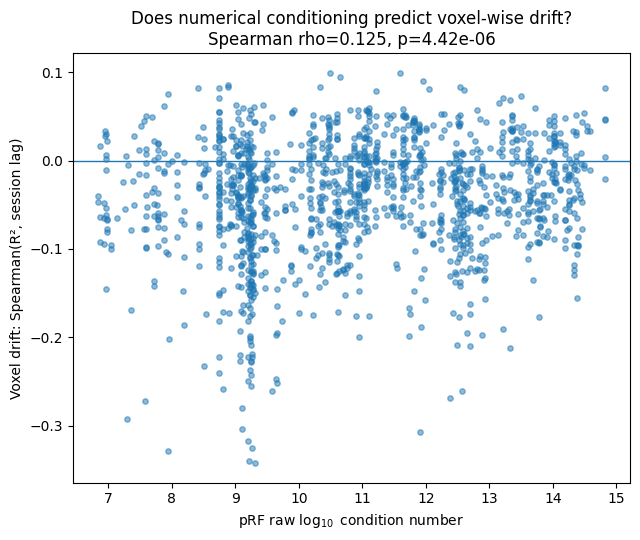


CONDITIONING vs EXTREME R² OUTLIERS


,outcome,spearman_r,spearman_p
0,min_cross_session_r2,-0.581140,8.964013e-123
1,frac_r2_lt_minus1,0.386993,1.808609e-49
2,frac_r2_lt_minus10,0.508903,7.830230e-90
3,frac_r2_lt_minus100,0.545497,1.626621e-105



DRIFT SENSITIVITY TO REMOVING WORST-CONDITIONED VOXELS


,worst_conditioning_removed_pct,condition_cutoff,n_voxels_remaining,median_voxel_drift_rho,median_voxel_drift_slope,pooled_lagcurve_rho,pooled_lagcurve_p,pooled_lagcurve_slope
0,0,inf,1350,-0.033004,0.003537,-0.765517,1.310728e-06,-0.001488
1,5,14.193522,1291,-0.033589,0.002599,-0.771921,9.400558e-07,-0.001476
2,10,13.749018,1217,-0.033929,0.001420,-0.770443,1.015952e-06,-0.001506
3,20,12.844521,1080,-0.035188,0.000519,-0.794581,2.647724e-07,-0.001580
4,30,12.249557,945,-0.033149,0.000259,-0.830542,2.474777e-08,-0.001651
5,40,11.489881,815,-0.037718,0.000077,-0.850739,5.062076e-09,-0.001802
6,50,10.862877,677,-0.046404,-0.001104,-0.898030,3.952872e-11,-0.001997


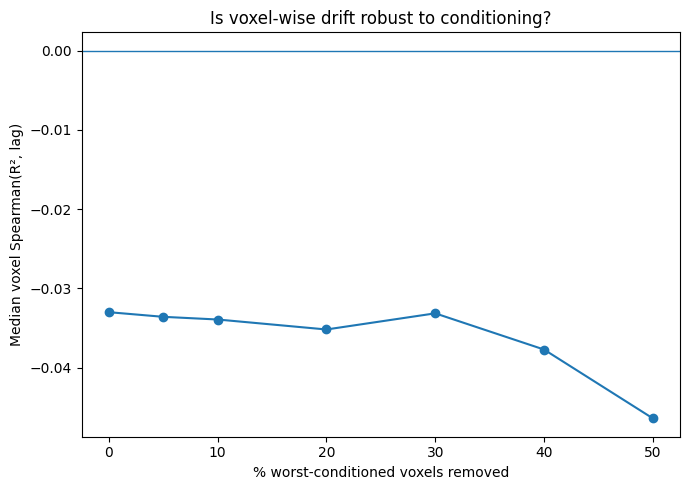

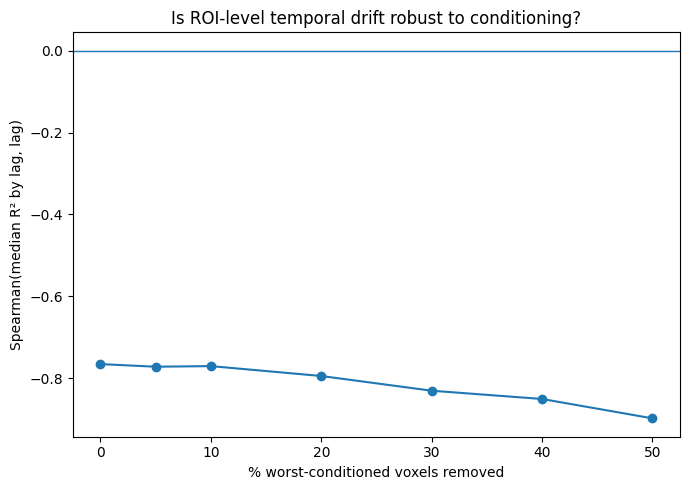

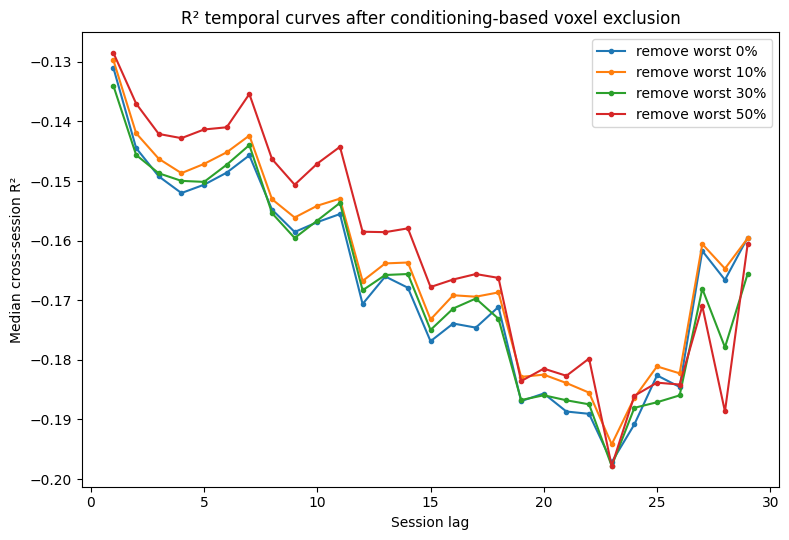


ROBUST CHECK — EXCLUDING VOXELS WITH MIN R² <= -10
N remaining: 276
Spearman conditioning vs drift: -0.042397660451198985
p: 0.48300250313499127

SAVED
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_vs_drift/S01_V1_pcaHL95/voxel_conditioning_vs_drift.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_vs_drift/S01_V1_pcaHL95/conditioning_vs_drift_correlations.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_vs_drift/S01_V1_pcaHL95/conditioning_vs_r2_outliers.csv
/content/drive/MyDrive/V2_drift/texturemodel/drift_results/conditioning_vs_drift/S01_V1_pcaHL95/conditioning_drift_sensitivity.csv

DONE.


In [ ]:
# ============================================================
# TEST 4:
# DOES NUMERICAL CONDITIONING AFFECT THE ACTUAL DRIFT METRIC?
#
# Main question:
#
#   pRF conditioning
#          ↓
#   voxel-wise temporal drift estimate?
#
# Drift metric:
#   Spearman correlation between cross-session R² and session lag
#
# More negative rho =
#   stronger decrease in model generalization with time
#
# Also performs sensitivity analysis:
#   remove worst-conditioned 10%, 20%, 30%, 40%, 50%
#   and recompute ROI-level drift.
#
# No fitting is rerun.
# ============================================================

from google.colab import drive
drive.mount("/content/drive", force_remount=False)

import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.stats import spearmanr, pearsonr


# ============================================================
# CONFIG
# ============================================================

ROOT = Path("/content/drive/MyDrive/V2_drift")

SUBJECT = 1
ROI = "V1"

PCA_PCT = 95
PCA_TYPE = "pcaHL"

N_SESSIONS = 30


# ============================================================
# FAST CROSS-SESSION FILE
# ============================================================

FAST_DIR = (
    ROOT
    / "texturemodel"
    / "model_fits"
    / f"S{SUBJECT:02d}"
    / "FAST_CROSS_SESSION"
)

candidate_fast = []

for fn in FAST_DIR.glob("*.h5py"):

    name = fn.name

    if (
        f"S{SUBJECT:02d}_{ROI}_" in name
        and f"{PCA_TYPE}_{ROI}_pca{PCA_PCT}_" in name
        and "30x30_cross_session" in name
    ):
        candidate_fast.append(fn)


print("=" * 110)
print("FAST FILE SEARCH")
print("=" * 110)

for fn in candidate_fast:
    print(fn)


if len(candidate_fast) == 0:
    raise FileNotFoundError(
        "Could not find matching 30x30 FAST cross-session file."
    )

elif len(candidate_fast) > 1:

    candidate_fast = sorted(
        candidate_fast,
        key=lambda x: x.stat().st_mtime
    )


FAST_FILE = candidate_fast[-1]

print("\nUSING:")
print(FAST_FILE)


# ============================================================
# pRF CONDITIONING FILE
# ============================================================

PRF_DIAG_FILE = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "pre_regression_diagnostics"
    / "S01_pcaHL0"
    / "prf_summary.csv"
)

assert PRF_DIAG_FILE.exists(), PRF_DIAG_FILE


prf_diag = pd.read_csv(
    PRF_DIAG_FILE
)

prf_diag = prf_diag.set_index(
    "prf",
    drop=False
)

assert prf_diag.index.is_unique


print("\n" + "=" * 110)
print("pRF DIAGNOSTIC")
print("=" * 110)

print(
    "Rows:",
    len(prf_diag)
)

print(
    "pRF range:",
    prf_diag.index.min(),
    "to",
    prf_diag.index.max()
)


# ============================================================
# LOAD FAST DATA
# ============================================================

with h5py.File(
    FAST_FILE,
    "r"
) as f:

    val_r2 = np.asarray(
        f["val_r2"]
    )

    fixed_best_prf = np.asarray(
        f["fixed_best_model_each_voxel"]
    ).squeeze()

    voxel_index = np.asarray(
        f["voxel_index"]
    ).squeeze()


print("\n" + "=" * 110)
print("FAST DATA")
print("=" * 110)

print(
    "val_r2:",
    val_r2.shape
)

print(
    "fixed_best_prf:",
    fixed_best_prf.shape
)

print(
    "voxel_index:",
    voxel_index.shape
)


# ============================================================
# NORMALIZE R² SHAPE TO:
# [train_session, test_session, voxel]
# ============================================================

R = np.squeeze(
    val_r2
)

if R.ndim != 3:

    raise ValueError(
        f"Unexpected val_r2 shape after squeeze: {R.shape}"
    )


n_voxels = len(
    fixed_best_prf
)


if (
    R.shape[0] == N_SESSIONS
    and
    R.shape[1] == N_SESSIONS
    and
    R.shape[2] == n_voxels
):

    pass

elif (
    R.shape[0] == n_voxels
    and
    R.shape[1] == N_SESSIONS
    and
    R.shape[2] == N_SESSIONS
):

    R = np.transpose(
        R,
        (
            1,
            2,
            0
        )
    )

elif (
    R.shape[0] == N_SESSIONS
    and
    R.shape[1] == n_voxels
    and
    R.shape[2] == N_SESSIONS
):

    R = np.transpose(
        R,
        (
            0,
            2,
            1
        )
    )

else:

    raise ValueError(
        f"Could not infer val_r2 axis order: {R.shape}"
    )


print(
    "Normalized R² shape:",
    R.shape
)


# ============================================================
# FIXED pRF ASSIGNMENT
# ============================================================

fixed_best_prf = np.asarray(
    fixed_best_prf
).reshape(-1).astype(int)


assert len(
    fixed_best_prf
) == n_voxels


assert np.min(
    fixed_best_prf
) >= 0


assert np.max(
    fixed_best_prf
) <= prf_diag.index.max()


# ============================================================
# SESSION LAG MATRIX
#
# train session 0, test session 0 -> lag 0
# train session 0, test session 5 -> lag 5
# ============================================================

session_ids = np.arange(
    N_SESSIONS
)

lag_matrix = np.abs(
    session_ids[:, None]
    -
    session_ids[None, :]
)


# ============================================================
# OFF-DIAGONAL MASK
#
# We exclude lag 0 because diagonal values correspond to
# same-session evaluation.
# ============================================================

offdiag_mask = (
    lag_matrix > 0
)

lags_all = lag_matrix[
    offdiag_mask
].astype(
    np.float64
)


print("\n" + "=" * 110)
print("SESSION-LAG CHECK")
print("=" * 110)

print(
    "Lag range:",
    np.min(
        lags_all
    ),
    "to",
    np.max(
        lags_all
    )
)

print(
    "Number of off-diagonal train-test pairs:",
    len(
        lags_all
    )
)


# ============================================================
# VOXEL-WISE DRIFT
#
# For each voxel:
#
# Spearman:
#     R² vs absolute session lag
#
# Also compute:
#     linear slope
#     median R²
#     extreme-R² diagnostics
# ============================================================

voxel_rows = []


print("\n" + "=" * 110)
print("CALCULATING VOXEL-WISE DRIFT")
print("=" * 110)


for vv in range(
    n_voxels
):

    if vv % 200 == 0:

        print(
            f"voxel {vv}/{n_voxels}"
        )


    rv = R[
        :,
        :,
        vv
    ]


    r2_values = rv[
        offdiag_mask
    ].astype(
        np.float64
    )


    good = (
        np.isfinite(
            r2_values
        )
        &
        np.isfinite(
            lags_all
        )
    )


    r2_good = r2_values[
        good
    ]

    lag_good = lags_all[
        good
    ]


    # --------------------------------------------------------
    # Drift Spearman
    # --------------------------------------------------------

    if len(
        r2_good
    ) >= 3:

        drift_rho, drift_p = spearmanr(
            lag_good,
            r2_good
        )

    else:

        drift_rho = np.nan
        drift_p = np.nan


    # --------------------------------------------------------
    # Linear slope
    # --------------------------------------------------------

    if (
        len(
            r2_good
        ) >= 3
        and
        np.std(
            lag_good
        ) > 0
    ):

        slope = np.polyfit(
            lag_good,
            r2_good,
            deg=1
        )[0]

    else:

        slope = np.nan


    # --------------------------------------------------------
    # pRF conditioning
    # --------------------------------------------------------

    prf = int(
        fixed_best_prf[
            vv
        ]
    )

    p = prf_diag.loc[
        prf
    ]


    # --------------------------------------------------------
    # R² robustness diagnostics
    # --------------------------------------------------------

    if len(
        r2_good
    ) > 0:

        median_r2 = np.nanmedian(
            r2_good
        )

        p1_r2 = np.nanpercentile(
            r2_good,
            1
        )

        p99_r2 = np.nanpercentile(
            r2_good,
            99
        )

        min_r2 = np.nanmin(
            r2_good
        )

        max_r2 = np.nanmax(
            r2_good
        )

        frac_r2_lt_minus1 = np.mean(
            r2_good < -1
        )

        frac_r2_lt_minus10 = np.mean(
            r2_good < -10
        )

        frac_r2_lt_minus100 = np.mean(
            r2_good < -100
        )

    else:

        median_r2 = np.nan
        p1_r2 = np.nan
        p99_r2 = np.nan
        min_r2 = np.nan
        max_r2 = np.nan

        frac_r2_lt_minus1 = np.nan
        frac_r2_lt_minus10 = np.nan
        frac_r2_lt_minus100 = np.nan


    voxel_rows.append({

        "voxel":
            vv,

        "voxel_index":
            voxel_index[
                vv
            ],

        "prf":
            prf,

        # ================================================
        # CONDITIONING
        # ================================================

        "raw_log10_condition":
            p[
                "log10_raw_condition"
            ],

        "standardized_log10_condition":
            p[
                "log10_standardized_condition"
            ],

        "min_feature_sd":
            p[
                "min_feature_sd"
            ],

        "n_features_sd_lt_1e-08":
            p[
                "n_features_sd_lt_1e-08"
            ],

        "max_abs_feature_corr":
            p[
                "max_abs_feature_corr"
            ],

        "n_pairs_abs_r_gt_099":
            p[
                "n_feature_pairs_abs_r_gt_099"
            ],

        # ================================================
        # DRIFT
        # ================================================

        "drift_spearman_rho":
            drift_rho,

        "drift_spearman_p":
            drift_p,

        "drift_linear_slope":
            slope,

        # ================================================
        # PREDICTION DISTRIBUTION
        # ================================================

        "median_cross_session_r2":
            median_r2,

        "p1_cross_session_r2":
            p1_r2,

        "p99_cross_session_r2":
            p99_r2,

        "min_cross_session_r2":
            min_r2,

        "max_cross_session_r2":
            max_r2,

        "frac_r2_lt_minus1":
            frac_r2_lt_minus1,

        "frac_r2_lt_minus10":
            frac_r2_lt_minus10,

        "frac_r2_lt_minus100":
            frac_r2_lt_minus100,
    })


voxel_df = pd.DataFrame(
    voxel_rows
)


print("\n" + "=" * 110)
print("VOXEL DRIFT TABLE")
print("=" * 110)

display(
    voxel_df.head()
)


# ============================================================
# PRIMARY TEST:
# CONDITIONING vs DRIFT
# ============================================================

conditioning_vars = [

    "raw_log10_condition",

    "min_feature_sd",

    "n_features_sd_lt_1e-08",

    "max_abs_feature_corr",

    "n_pairs_abs_r_gt_099",
]


drift_vars = [

    "drift_spearman_rho",

    "drift_linear_slope",
]


corr_rows = []


for predictor in conditioning_vars:

    for outcome in drift_vars:

        x = voxel_df[
            predictor
        ].to_numpy(
            dtype=float
        )

        y = voxel_df[
            outcome
        ].to_numpy(
            dtype=float
        )


        good = (
            np.isfinite(x)
            &
            np.isfinite(y)
        )


        if np.sum(
            good
        ) >= 3:

            sr, sp = spearmanr(
                x[
                    good
                ],
                y[
                    good
                ]
            )

            pr, pp = pearsonr(
                x[
                    good
                ],
                y[
                    good
                ]
            )

        else:

            sr = sp = pr = pp = np.nan


        corr_rows.append({

            "predictor":
                predictor,

            "outcome":
                outcome,

            "n":
                int(
                    np.sum(
                        good
                    )
                ),

            "spearman_r":
                sr,

            "spearman_p":
                sp,

            "pearson_r":
                pr,

            "pearson_p":
                pp,
        })


drift_corr_df = pd.DataFrame(
    corr_rows
)


print("\n" + "=" * 110)
print("CONDITIONING vs VOXEL DRIFT")
print("=" * 110)

display(
    drift_corr_df.sort_values(
        "spearman_r",
        key=lambda x: np.abs(x),
        ascending=False
    )
)


# ============================================================
# PRIMARY SCATTER:
# RAW CONDITIONING vs SPEARMAN DRIFT
# ============================================================

x = voxel_df[
    "raw_log10_condition"
].to_numpy(
    dtype=float
)

y = voxel_df[
    "drift_spearman_rho"
].to_numpy(
    dtype=float
)


good = (
    np.isfinite(x)
    &
    np.isfinite(y)
)


rho_cond_drift, p_cond_drift = spearmanr(
    x[
        good
    ],
    y[
        good
    ]
)


plt.figure(
    figsize=(6.5, 5.5)
)

plt.scatter(
    x[
        good
    ],
    y[
        good
    ],
    s=15,
    alpha=0.5
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    r"pRF raw $\log_{10}$ condition number"
)

plt.ylabel(
    "Voxel drift: Spearman(R², session lag)"
)

plt.title(
    "Does numerical conditioning predict voxel-wise drift?\n"
    f"Spearman rho={rho_cond_drift:.3f}, "
    f"p={p_cond_drift:.3g}"
)

plt.tight_layout()

plt.show()


# ============================================================
# CONDITIONING vs EXTREME R² OUTLIERS
#
# This helps distinguish:
#
# actual temporal drift
# from
# a few numerical prediction explosions
# ============================================================

outlier_metrics = [

    "min_cross_session_r2",

    "frac_r2_lt_minus1",

    "frac_r2_lt_minus10",

    "frac_r2_lt_minus100",
]


outlier_rows = []


for outcome in outlier_metrics:

    x = voxel_df[
        "raw_log10_condition"
    ].to_numpy(
        dtype=float
    )

    y = voxel_df[
        outcome
    ].to_numpy(
        dtype=float
    )


    good = (
        np.isfinite(x)
        &
        np.isfinite(y)
    )


    sr, sp = spearmanr(
        x[
            good
        ],
        y[
            good
        ]
    )


    outlier_rows.append({

        "outcome":
            outcome,

        "spearman_r":
            sr,

        "spearman_p":
            sp,
    })


outlier_df = pd.DataFrame(
    outlier_rows
)


print("\n" + "=" * 110)
print("CONDITIONING vs EXTREME R² OUTLIERS")
print("=" * 110)

display(
    outlier_df
)


# ============================================================
# ROI-LEVEL DRIFT FUNCTION
#
# Two summaries:
#
# 1. median voxel drift
# 2. pooled ROI drift:
#       median R² at each lag across voxels/pairs
#       then Spearman vs lag
# ============================================================

def compute_roi_summary(
    voxel_mask
):

    voxel_mask = np.asarray(
        voxel_mask,
        dtype=bool
    )


    selected_voxels = np.where(
        voxel_mask
    )[0]


    # --------------------------------------------------------
    # Median voxel-wise drift
    # --------------------------------------------------------

    median_voxel_rho = np.nanmedian(
        voxel_df.loc[
            voxel_mask,
            "drift_spearman_rho"
        ]
    )


    median_voxel_slope = np.nanmedian(
        voxel_df.loc[
            voxel_mask,
            "drift_linear_slope"
        ]
    )


    # --------------------------------------------------------
    # Build lag curve
    # --------------------------------------------------------

    lag_values = np.arange(
        1,
        N_SESSIONS
    )


    lag_medians = []


    for lag in lag_values:

        lag_mask = (
            lag_matrix == lag
        )


        vals = R[
            :,
            :,
            selected_voxels
        ][
            lag_mask,
            :
        ].reshape(-1)


        vals = vals[
            np.isfinite(
                vals
            )
        ]


        if len(
            vals
        ) > 0:

            lag_medians.append(
                np.nanmedian(
                    vals
                )
            )

        else:

            lag_medians.append(
                np.nan
            )


    lag_medians = np.asarray(
        lag_medians,
        dtype=float
    )


    good = (
        np.isfinite(
            lag_medians
        )
    )


    if np.sum(
        good
    ) >= 3:

        pooled_rho, pooled_p = spearmanr(
            lag_values[
                good
            ],
            lag_medians[
                good
            ]
        )

        pooled_slope = np.polyfit(
            lag_values[
                good
            ],
            lag_medians[
                good
            ],
            1
        )[0]

    else:

        pooled_rho = np.nan
        pooled_p = np.nan
        pooled_slope = np.nan


    return {

        "n_voxels":
            len(
                selected_voxels
            ),

        "median_voxel_drift_rho":
            median_voxel_rho,

        "median_voxel_drift_slope":
            median_voxel_slope,

        "pooled_lagcurve_rho":
            pooled_rho,

        "pooled_lagcurve_p":
            pooled_p,

        "pooled_lagcurve_slope":
            pooled_slope,

        "lag_values":
            lag_values,

        "lag_medians":
            lag_medians,
    }


# ============================================================
# SENSITIVITY ANALYSIS:
# REMOVE WORST CONDITIONING
# ============================================================

remove_levels = [

    0,
    5,
    10,
    20,
    30,
    40,
    50,
]


sensitivity_rows = []

lagcurve_store = {}


for remove_pct in remove_levels:

    cond = voxel_df[
        "raw_log10_condition"
    ].to_numpy(
        dtype=float
    )


    if remove_pct == 0:

        keep = np.isfinite(
            cond
        )

        cutoff = np.inf

    else:

        cutoff = np.nanpercentile(
            cond,
            100 - remove_pct
        )

        keep = (
            np.isfinite(
                cond
            )
            &
            (
                cond <= cutoff
            )
        )


    summary = compute_roi_summary(
        keep
    )


    sensitivity_rows.append({

        "worst_conditioning_removed_pct":
            remove_pct,

        "condition_cutoff":
            cutoff,

        "n_voxels_remaining":
            summary[
                "n_voxels"
            ],

        "median_voxel_drift_rho":
            summary[
                "median_voxel_drift_rho"
            ],

        "median_voxel_drift_slope":
            summary[
                "median_voxel_drift_slope"
            ],

        "pooled_lagcurve_rho":
            summary[
                "pooled_lagcurve_rho"
            ],

        "pooled_lagcurve_p":
            summary[
                "pooled_lagcurve_p"
            ],

        "pooled_lagcurve_slope":
            summary[
                "pooled_lagcurve_slope"
            ],
    })


    lagcurve_store[
        remove_pct
    ] = (
        summary[
            "lag_values"
        ],
        summary[
            "lag_medians"
        ]
    )


sensitivity_df = pd.DataFrame(
    sensitivity_rows
)


print("\n" + "=" * 110)
print("DRIFT SENSITIVITY TO REMOVING WORST-CONDITIONED VOXELS")
print("=" * 110)

display(
    sensitivity_df
)


# ============================================================
# PLOT:
# MEDIAN VOXEL DRIFT vs CONDITIONING FILTER
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    sensitivity_df[
        "worst_conditioning_removed_pct"
    ],
    sensitivity_df[
        "median_voxel_drift_rho"
    ],
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    "% worst-conditioned voxels removed"
)

plt.ylabel(
    "Median voxel Spearman(R², lag)"
)

plt.title(
    "Is voxel-wise drift robust to conditioning?"
)

plt.tight_layout()

plt.show()


# ============================================================
# PLOT:
# POOLED ROI DRIFT vs CONDITIONING FILTER
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.plot(
    sensitivity_df[
        "worst_conditioning_removed_pct"
    ],
    sensitivity_df[
        "pooled_lagcurve_rho"
    ],
    marker="o"
)

plt.axhline(
    0,
    linewidth=1
)

plt.xlabel(
    "% worst-conditioned voxels removed"
)

plt.ylabel(
    "Spearman(median R² by lag, lag)"
)

plt.title(
    "Is ROI-level temporal drift robust to conditioning?"
)

plt.tight_layout()

plt.show()


# ============================================================
# PLOT:
# LAG CURVES BEFORE / AFTER FILTERING
# ============================================================

plt.figure(
    figsize=(8, 5.5)
)


for remove_pct in [
    0,
    10,
    30,
    50,
]:

    lags, curve = lagcurve_store[
        remove_pct
    ]

    plt.plot(
        lags,
        curve,
        marker="o",
        markersize=3,
        label=f"remove worst {remove_pct}%"
    )


plt.xlabel(
    "Session lag"
)

plt.ylabel(
    "Median cross-session R²"
)

plt.title(
    "R² temporal curves after conditioning-based voxel exclusion"
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# OPTIONAL ROBUSTNESS:
#
# Does the conditioning-drift relationship remain if we ignore
# voxels with extremely pathological prediction values?
#
# Example threshold:
# minimum cross-session R² > -10
# ============================================================

robust_mask = (
    np.isfinite(
        voxel_df[
            "raw_log10_condition"
        ]
    )
    &
    np.isfinite(
        voxel_df[
            "drift_spearman_rho"
        ]
    )
    &
    (
        voxel_df[
            "min_cross_session_r2"
        ]
        >
        -10
    )
)


x = voxel_df.loc[
    robust_mask,
    "raw_log10_condition"
].to_numpy(
    dtype=float
)

y = voxel_df.loc[
    robust_mask,
    "drift_spearman_rho"
].to_numpy(
    dtype=float
)


if len(
    x
) >= 3:

    rho_robust, p_robust = spearmanr(
        x,
        y
    )

else:

    rho_robust = np.nan
    p_robust = np.nan


print("\n" + "=" * 110)
print("ROBUST CHECK — EXCLUDING VOXELS WITH MIN R² <= -10")
print("=" * 110)

print(
    "N remaining:",
    len(
        x
    )
)

print(
    "Spearman conditioning vs drift:",
    rho_robust
)

print(
    "p:",
    p_robust
)


# ============================================================
# SAVE
# ============================================================

OUT_DIR = (
    ROOT
    / "texturemodel"
    / "drift_results"
    / "conditioning_vs_drift"
    / f"S{SUBJECT:02d}_{ROI}_{PCA_TYPE}{PCA_PCT}"
)

OUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


voxel_file = (
    OUT_DIR
    / "voxel_conditioning_vs_drift.csv"
)

corr_file = (
    OUT_DIR
    / "conditioning_vs_drift_correlations.csv"
)

outlier_file = (
    OUT_DIR
    / "conditioning_vs_r2_outliers.csv"
)

sensitivity_file = (
    OUT_DIR
    / "conditioning_drift_sensitivity.csv"
)


voxel_df.to_csv(
    voxel_file,
    index=False
)

drift_corr_df.to_csv(
    corr_file,
    index=False
)

outlier_df.to_csv(
    outlier_file,
    index=False
)

sensitivity_df.to_csv(
    sensitivity_file,
    index=False
)


print("\n" + "=" * 110)
print("SAVED")
print("=" * 110)

print(
    voxel_file
)

print(
    corr_file
)

print(
    outlier_file
)

print(
    sensitivity_file
)

print("\nDONE.")

In [ ]:
import numpy as np
from pathlib import Path

ROOT = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01"
)

files = sorted(ROOT.glob(
    "texture_pyramid_OLS_session_*_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs/*/all_fit_params.npy"
))

print(f"Found {len(files)} fit files.\n")

if len(files) == 0:
    raise FileNotFoundError("No all_fit_params.npy files found.")

for file in files:

    print("=" * 90)
    print(file.parent.parent.name)
    print(file.parent.name)
    print("=" * 90)

    d = np.load(file, allow_pickle=True).item()

    print(f"Exists: {file.exists()}")
    print(f"Size: {file.stat().st_size / 1024**2:.2f} MB")

    print("\nRun settings:")
    for key in [
        "subject",
        "roi_name",
        "debug",
        "single_sess",
        "single_val_sess",
        "whole_session_split",
        "pca_pct_var",
        "zscore_features",
        "ridge",
    ]:
        print(f"  {key:25s}: {d.get(key)}")

    print("\nCompletion:")
    print("  training :", d["voxel_subset_is_done_trn"])
    print("  validation:", d["voxel_subset_is_done_val"])

    best_params = d["best_params"]

    names = [
        "best_prf_model_parameters",
        "best_weights",
        "best_biases",
        "features_mean",
        "features_std",
        "best_prf_models",
    ]

    print("\nBest parameter shapes:")

    for name, value in zip(names, best_params):

        if value is None:
            print(f"  {name:28s}: None")
        else:
            print(
                f"  {name:28s}: "
                f"{value.shape} {value.dtype}"
            )

    best_prf_models = best_params[5]

    print("\nSelected pRFs:")

    print("  unique:", np.unique(best_prf_models).size)
    print("  min   :", np.min(best_prf_models))
    print("  max   :", np.max(best_prf_models))

    arrays = {
        "best_losses": d["best_losses"],
        "best_lambdas": d["best_lambdas"],
        "best_weights": best_params[1],
        "best_biases": best_params[2],
        "features_mean": best_params[3],
        "features_std": best_params[4],
        "val_cc": d["val_cc"],
        "val_r2": d["val_r2"],
    }

    print("\nDiagnostics:")

    for name, arr in arrays.items():

        if arr is None:
            print(f"  {name:18s}: None")
            continue

        print(
            f"  {name:18s}"
            f" shape={arr.shape}"
            f" NaN={np.isnan(arr).sum():6d}"
            f" Inf={np.isinf(arr).sum():6d}"
            f" min={np.nanmin(arr):10.5g}"
            f" max={np.nanmax(arr):10.5g}"
            f" mean={np.nanmean(arr):10.5g}"
        )

    if d["val_cc"] is not None:
        print(
            "\nValidation summary:"
        )
        print(
            f"  median val_cc = {np.nanmedian(d['val_cc']):.4f}"
        )

    if d["val_r2"] is not None:
        print(
            f"  median val_r2 = {np.nanmedian(d['val_r2']):.4f}"
        )

    print()

In [ ]:
# now with z scoring featrues

import numpy as np
from pathlib import Path

FILE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_session_1_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_validated_on_session_2/Jul-27-2026_1359_57/all_fit_params.npy"
)

print("Exists:", FILE.exists())
print("Size (MB):", FILE.stat().st_size / 1024**2)

d = np.load(FILE, allow_pickle=True).item()

print("\nSaved keys:")
print(sorted(d.keys()))

print("\nRun settings:")
for key in [
    "subject",
    "roi_name",
    "debug",
    "single_sess",
    "single_val_sess",
    "whole_session_split",
    "pca_pct_var",
    "zscore_features",
    "ridge",
]:
    print(f"{key}: {d.get(key)}")

print("\nCompletion flags:")
print("training:", d["voxel_subset_is_done_trn"])
print("validation:", d["voxel_subset_is_done_val"])

print("\nMain array shapes:")
for key in [
    "image_order",
    "voxel_index",
    "voxel_ncsnr",
    "best_losses",
    "best_lambdas",
    "val_cc",
    "val_r2",
]:
    value = d.get(key)
    print(
        f"{key}:",
        None if value is None else value.shape,
        None if value is None else value.dtype,
    )

best_params = d["best_params"]

names = [
    "best_prf_model_parameters",
    "best_weights",
    "best_biases",
    "features_mean",
    "features_std",
    "best_prf_models",
]

print("\nbest_params:")
for name, value in zip(names, best_params):
    if value is None:
        print(f"{name}: None")
    else:
        print(f"{name}: shape={value.shape}, dtype={value.dtype}")

best_prf_models = best_params[5]

print("\nBest pRF diagnostics:")
print("Number of unique selected pRFs:", np.unique(best_prf_models).size)
print("Selected pRF indices:", np.unique(best_prf_models))
print("Minimum pRF index:", np.min(best_prf_models))
print("Maximum pRF index:", np.max(best_prf_models))

print("\nNumerical diagnostics:")
arrays = {
    "best_losses": d["best_losses"],
    "best_lambdas": d["best_lambdas"],
    "best_weights": best_params[1],
    "best_biases": best_params[2],
    "features_mean": best_params[3],
    "features_std": best_params[4],
    "val_cc": d["val_cc"],
    "val_r2": d["val_r2"],
}

for name, arr in arrays.items():
    if arr is None:
        print(f"{name}: None")
        continue

    print(
        f"{name}: "
        f"shape={arr.shape}, "
        f"NaNs={np.isnan(arr).sum()}, "
        f"Infs={np.isinf(arr).sum()}, "
        f"min={np.nanmin(arr):.6g}, "
        f"max={np.nanmax(arr):.6g}, "
        f"mean={np.nanmean(arr):.6g}"
    )

In [ ]:
import numpy as np

FILE_ZSCORE = (
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_session_1_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs_validated_on_session_2/Jul-27-2026_1359_57/all_fit_params.npy"
)

res_z = np.load(FILE_ZSCORE, allow_pickle=True).item()

print("zscore_features:", res_z["zscore_features"])
print("best_params type:", type(res_z["best_params"]))

In [ ]:
best_params = res_z["best_params"]

if isinstance(best_params, dict):
    best_prf = np.asarray(best_params["best_prf_models"])[:, 0]
    features_std = np.asarray(best_params["features_std"])[:, :, 0]

elif isinstance(best_params, (list, tuple)):
    (
        best_prf_model_parameters,
        best_weights,
        best_biases,
        features_mean,
        features_std,
        best_prf_models,
    ) = best_params

    best_prf = np.asarray(best_prf_models)[:, 0]
    features_std = np.asarray(features_std)[:, :, 0]

else:
    raise TypeError(f"Unexpected best_params type: {type(best_params)}")

In [ ]:
used_prfs = np.unique(best_prf)
used_std = features_std[used_prfs, :]

print("\nUsed pRFs:", len(used_prfs))
print("Used pRF-feature values:", used_std.size)
print("NaNs:", np.isnan(used_std).sum())
print("Infs:", np.isinf(used_std).sum())
print("Exactly zero:", np.sum(used_std == 0))

positive_std = used_std[
    np.isfinite(used_std) & (used_std > 0)
]

print("Finite positive values:", positive_std.size)

if positive_std.size > 0:
    print(
        "Positive std percentiles:",
        np.percentile(
            positive_std,
            [0, 0.1, 1, 5, 50, 95, 99, 100]
        )
    )
else:
    print("No finite positive standard deviations found.")

In [ ]:
thresholds = [1.01e-6, 1.1e-6, 2e-6, 1e-5, 1e-4, 1e-3]

for threshold in thresholds:
    count = np.sum(positive_std <= threshold)
    pct = 100 * count / positive_std.size
    print(f"std <= {threshold:.2e}: {count} ({pct:.3f}%)")

In [ ]:
ll_std = used_std[:, :49]
hl_std = used_std[:, 49:]

print("LL")
print(" shape:", ll_std.shape)
print(" median:", np.nanmedian(ll_std))
print(" <1e-6 :", np.mean(ll_std <= 1e-6))
print(" <1e-4 :", np.mean(ll_std <= 1e-4))
print(" <1e-3 :", np.mean(ll_std <= 1e-3))

print("\nHL PCs")
print(" shape:", hl_std.shape)
print(" median:", np.nanmedian(hl_std))
print(" <1e-6 :", np.mean(hl_std <= 1e-6))
print(" <1e-4 :", np.mean(hl_std <= 1e-4))
print(" <1e-3 :", np.mean(hl_std <= 1e-3))

In [ ]:
hl_std = used_std[:, 49:]

for i in range(5):
    print(
        f"PC{i+1}:",
        np.sum(hl_std[:, i] > 1e-6),
        "non-zero std"
    )

In [ ]:
import numpy as np
import pandas as pd

res = np.load(FILE, allow_pickle=True).item()

# ------------------------------------------------------------
# Extract best_params safely
# ------------------------------------------------------------
best_params = res["best_params"]

if isinstance(best_params, dict):
    best_prf = np.asarray(best_params["best_prf_models"])[:, 0]

elif isinstance(best_params, (list, tuple)):
    (
        best_prf_model_parameters,
        best_weights,
        best_biases,
        features_mean,
        features_std,
        best_prf,
    ) = best_params

    best_prf = np.asarray(best_prf)[:, 0]

else:
    raise TypeError(
        f"Unexpected best_params type: {type(best_params)}"
    )

loss = np.asarray(res["best_losses"])[:, 0]
val_cc = np.asarray(res["val_cc"])[:, 0]
val_r2 = np.asarray(res["val_r2"])[:, 0]

# Voxels actually fitted during debug mode
valid = (
    np.isfinite(loss)
    & (best_prf >= 0)
)

print("Total voxels:", len(valid))
print("Fitted debug voxels:", valid.sum())

cc = val_cc[valid]
r2 = val_r2[valid]
prf = best_prf[valid]

summary = pd.DataFrame({
    "val_cc": cc,
    "val_r2": r2,
    "best_prf": prf,
})

display(
    summary.describe(
        percentiles=[
            0.01, 0.05, 0.25,
            0.50, 0.75, 0.95, 0.99
        ]
    )
)

print("\nValidation correlation:")
print("  finite:", np.isfinite(cc).sum())
print("  positive:", np.sum(cc > 0))
print("  zero:", np.sum(cc == 0))
print("  negative:", np.sum(cc < 0))
print("  mean:", np.nanmean(cc))
print("  median:", np.nanmedian(cc))
print("  min:", np.nanmin(cc))
print("  max:", np.nanmax(cc))

print("\nValidation R²:")
print("  finite:", np.isfinite(r2).sum())
print("  positive:", np.sum(r2 > 0))
print("  zero:", np.sum(r2 == 0))
print("  negative:", np.sum(r2 < 0))
print("  mean:", np.nanmean(r2))
print("  median:", np.nanmedian(r2))
print("  min:", np.nanmin(r2))
print("  max:", np.nanmax(r2))

print("\nSelected pRFs:")
print(
    pd.Series(prf)
    .value_counts()
    .sort_index()
)

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

# ============================================================
# EDIT THIS PATH
# ============================================================
RESULTS_FILE = Path(
    "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/"
    "texture_pyramid_OLS_session_1_4ori_4sf_pcaHL_V1_pca95_use_nsd_grid5_pRFs/Jul-27-2026_1304_14_DEBUG/all_fit_params.npy"
)

# ============================================================
# LOAD RESULTS
# ============================================================
results = np.load(
    RESULTS_FILE,
    allow_pickle=True,
).item()

best_params = results["best_params"]

# best_params can be either a dictionary or a list/tuple,
# depending on how the results were saved.
if isinstance(best_params, dict):
    weights = np.asarray(best_params["best_weights"])
    biases = np.asarray(best_params["best_biases"])
    best_prf = np.asarray(best_params["best_prf_models"])
    features_mean = np.asarray(best_params["features_mean"])
    features_std = np.asarray(best_params["features_std"])
else:
    (
        best_prf_model_parameters,
        weights,
        biases,
        features_mean,
        features_std,
        best_prf,
    ) = best_params

losses = np.asarray(results["best_losses"])
best_lambdas = np.asarray(results["best_lambdas"])

# Remove the model-version dimension.
loss = losses[:, 0]
best_lambda = best_lambdas[:, 0]
best_prf = best_prf[:, 0]
weights = weights[:, :, 0]
biases = biases[:, 0]

# A voxel was fitted when it has a valid pRF and finite loss.
valid = (
    np.isfinite(loss)
    & (best_prf >= 0)
)

print("=" * 70)
print("RUN SETTINGS")
print("=" * 70)

for key in [
    "subject",
    "roi_name",
    "debug",
    "single_sess",
    "single_val_sess",
    "whole_session_split",
    "zscore_features",
    "ridge",
]:
    print(f"{key}: {results.get(key)}")

print("\n" + "=" * 70)
print("VALID VOXELS")
print("=" * 70)

print(f"Total voxels: {len(valid)}")
print(f"Valid fitted voxels: {valid.sum()}")
print(f"Unfitted voxels: {(~valid).sum()}")
print(f"Selected pRFs: {np.unique(best_prf[valid])}")

# ============================================================
# VOXEL-WISE NUMERICAL SUMMARY
# ============================================================
valid_weights = weights[valid]
valid_biases = biases[valid]
valid_losses = loss[valid]
valid_prfs = best_prf[valid]

summary = pd.DataFrame({
    "loss": valid_losses,
    "max_abs_weight": np.max(np.abs(valid_weights), axis=1),
    "mean_abs_weight": np.mean(np.abs(valid_weights), axis=1),
    "weight_l2": np.linalg.norm(valid_weights, axis=1),
    "abs_bias": np.abs(valid_biases),
    "best_prf": valid_prfs,
})

display(summary.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

print("\nLarge-weight counts:")
max_abs_weight = summary["max_abs_weight"].to_numpy()

for threshold in [10, 100, 1_000, 10_000, 1e6, 1e8]:
    count = np.sum(max_abs_weight > threshold)
    print(
        f"|weight| > {threshold:g}: "
        f"{count} of {len(max_abs_weight)}"
    )

# ============================================================
# CHECK WHETHER ZERO LOSSES ARE REAL
# ============================================================
print("\n" + "=" * 70)
print("LOSS DIAGNOSTICS")
print("=" * 70)

print("Unique finite losses:", np.unique(valid_losses)[:20])
print("Number with loss exactly zero:", np.sum(valid_losses == 0))
print("Number with positive loss:", np.sum(valid_losses > 0))

if len(valid_losses) > 0 and np.all(valid_losses == 0):
    print(
        "\nWARNING: Every fitted voxel has loss = 0.\n"
        "In this fitting implementation, best_losses is the held-out SSE.\n"
        "A zero loss for every voxel usually means that the held-out set was\n"
        "empty, rather than that the model predicted every response perfectly."
    )

# ============================================================
# CHECK STANDARD DEVIATIONS FOR ACTUALLY SELECTED pRFs
# ============================================================
print("\n" + "=" * 70)
print("FEATURE-STANDARDIZATION DIAGNOSTICS")
print("=" * 70)

selected_prfs = np.unique(valid_prfs)
selected_prfs = selected_prfs[selected_prfs >= 0]

for prf in selected_prfs:
    sd = np.asarray(features_std[prf, :, 0]).reshape(-1)
    mean = np.asarray(features_mean[prf, :, 0]).reshape(-1)

    defined = (
        np.isfinite(sd)
        & np.isfinite(mean)
        & (sd > 0)
    )

    print(f"\npRF {prf}")
    print(f"  Saved feature slots: {len(sd)}")
    print(f"  Positive finite SDs: {defined.sum()}")
    print(f"  Zero SDs: {(sd == 0).sum()}")
    print(f"  Non-finite SDs: {(~np.isfinite(sd)).sum()}")

    if np.any(defined):
        print(f"  Minimum positive SD: {sd[defined].min():.8g}")
        print(f"  Median positive SD: {np.median(sd[defined]):.8g}")
        print(f"  Maximum positive SD: {sd[defined].max():.8g}")

# ============================================================
# VERIFY WHETHER pRF SELECTION WAS MEANINGFUL
# ============================================================
print("\n" + "=" * 70)
print("pRF-SELECTION CHECK")
print("=" * 70)

prf_counts = pd.Series(valid_prfs).value_counts().sort_index()
print(prf_counts)

if (
    len(valid_losses) > 0
    and np.all(valid_losses == 0)
    and len(prf_counts) <= 2
):
    print(
        "\nThe pRF comparison is not meaningful in this run.\n"
        "Because every held-out SSE is zero, the first tested pRF generally\n"
        "remains selected. This explains why almost all voxels selected pRF 0."
    )


In [ ]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

N_PRFS = 100          # Use None for all pRFs
STD_EPS = 0.0         # Remove only exactly constant columns
ZSCORE_EPS = 1e-6

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/analysis/numerical_conditioning"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# NUMERICAL SUMMARY
# ============================================================

def summarize_feature_matrix(X, model, prf):
    """
    Summarize an images × features matrix.

    Parameters
    ----------
    X : array
        Expected shape: n_images × n_features
    model : str
    prf : int
    """

    X = np.asarray(X, dtype=np.float64)

    if X.ndim != 2:
        raise ValueError(
            f"{model}, pRF {prf}: expected a 2D matrix, got shape {X.shape}"
        )

    print(
        f"{model}, pRF {prf}: initial shape={X.shape}, "
        f"finite fraction={np.isfinite(X).mean():.6f}"
    )

    # A feature must contain at least two finite values
    finite_counts = np.sum(np.isfinite(X), axis=0)
    keep_finite = finite_counts >= 2

    if not np.any(keep_finite):
        raise ValueError(
            f"{model}, pRF {prf}: no feature columns contain at least "
            f"two finite values. This likely indicates incorrect axis slicing."
        )

    X = X[:, keep_finite]

    # Replace occasional nonfinite values with the feature mean
    feature_means = np.nanmean(
        np.where(np.isfinite(X), X, np.nan),
        axis=0
    )

    bad = ~np.isfinite(X)
    if np.any(bad):
        X = X.copy()
        rows, cols = np.where(bad)
        X[rows, cols] = feature_means[cols]

    feature_sd = np.std(X, axis=0)

    keep_variable = (
        np.isfinite(feature_sd)
        & (feature_sd > STD_EPS)
    )

    print(
        f"{model}, pRF {prf}: "
        f"{keep_finite.sum()} finite columns, "
        f"{keep_variable.sum()} variable columns"
    )

    if not np.any(keep_variable):
        print("Feature SD values:")
        print(feature_sd)

        raise ValueError(
            f"{model}, pRF {prf}: all columns are constant or invalid. "
            f"The likely cause is incorrect SP axis ordering."
        )

    X = X[:, keep_variable]
    feature_sd = feature_sd[keep_variable]

    # Center before condition-number calculation.
    # This evaluates conditioning of variation around the mean.
    X_centered = X - X.mean(axis=0, keepdims=True)

    # np.linalg.cond uses singular-value decomposition
    condition_raw = np.linalg.cond(X_centered)

    X_z = X_centered / (feature_sd[None, :] + ZSCORE_EPS)
    condition_zscore = np.linalg.cond(X_z)

    return {
        "model": model,
        "prf": prf,
        "n_images": X.shape[0],
        "n_features_original": int(keep_finite.size),
        "n_features_retained": X.shape[1],
        "min_feature_sd": float(np.min(feature_sd)),
        "median_feature_sd": float(np.median(feature_sd)),
        "max_feature_sd": float(np.max(feature_sd)),
        "condition_raw": float(condition_raw),
        "condition_zscore": float(condition_zscore),
    }


# ============================================================
# INSPECT HDF5 CONTENT
# ============================================================

def print_h5_structure(group, prefix=""):
    """Print every dataset and its shape."""

    for key in group.keys():
        item = group[key]
        path = f"{prefix}/{key}"

        if isinstance(item, h5py.Dataset):
            print(
                f"{path}: shape={item.shape}, dtype={item.dtype}"
            )
        else:
            print(f"{path}/")
            print_h5_structure(item, path)


# ============================================================
# AXIS DETECTION FOR SP ARRAYS
# ============================================================

def infer_image_axis(shape, expected_images=None):
    """
    Identify the image axis.

    Natural-scenes feature files usually have thousands of images,
    whereas feature and pRF dimensions are substantially smaller.
    """

    if expected_images is not None:
        matches = [
            i for i, size in enumerate(shape)
            if size == expected_images
        ]

        if len(matches) == 1:
            return matches[0]

    # Fallback: image axis is usually the largest dimension
    return int(np.argmax(shape))


def extract_prf_matrix(
    array,
    prf,
    expected_images=None,
    expected_prfs=None,
    array_name="array",
):
    """
    Extract one pRF and return an images × flattened-features matrix.

    Supports arrays with arbitrary axis ordering.
    """

    shape = array.shape
    ndim = len(shape)

    if ndim < 2:
        raise ValueError(
            f"{array_name}: expected at least 2 dimensions, got {shape}"
        )

    image_axis = infer_image_axis(
        shape,
        expected_images=expected_images
    )

    candidate_prf_axes = [
        axis for axis, size in enumerate(shape)
        if axis != image_axis
        and expected_prfs is not None
        and size == expected_prfs
    ]

    if len(candidate_prf_axes) == 1:
        prf_axis = candidate_prf_axes[0]

    elif len(candidate_prf_axes) > 1:
        raise ValueError(
            f"{array_name}: multiple axes match n_prfs="
            f"{expected_prfs}. Shape={shape}, matches={candidate_prf_axes}"
        )

    else:
        # Common fallback: among non-image axes, the pRF axis is
        # usually the largest dimension.
        non_image_axes = [
            axis for axis in range(ndim)
            if axis != image_axis
        ]

        prf_axis = max(
            non_image_axes,
            key=lambda axis: shape[axis]
        )

    if prf >= shape[prf_axis]:
        raise IndexError(
            f"{array_name}: requested pRF {prf}, but pRF axis "
            f"{prf_axis} has size {shape[prf_axis]}"
        )

    print(
        f"{array_name}: shape={shape}, "
        f"image_axis={image_axis}, pRF_axis={prf_axis}"
    )

    # Select one pRF
    indexer = [slice(None)] * ndim
    indexer[prf_axis] = prf

    X = np.asarray(array[tuple(indexer)], dtype=np.float64)

    # After removing pRF axis, update image-axis index
    image_axis_after = image_axis
    if prf_axis < image_axis:
        image_axis_after -= 1

    # Move image axis to the front
    X = np.moveaxis(X, image_axis_after, 0)

    # Flatten all remaining feature dimensions
    X = X.reshape(X.shape[0], -1)

    return X


# ============================================================
# TEXTURE STATISTICS
# ============================================================

def process_texture_file(ts_file, n_prfs=None):
    rows = []

    print("\n========================================")
    print("Processing Texture Statistics")
    print("========================================")

    with h5py.File(ts_file, "r") as f:
        print_h5_structure(f)

        features = f["features"]

        # Assumes texture matrix is images × features × pRFs,
        # as established in your PCA output.
        total_prfs = features.shape[2]

        if n_prfs is not None:
            total_prfs = min(total_prfs, n_prfs)

        for prf in range(total_prfs):
            X = np.asarray(
                features[:, :, prf],
                dtype=np.float64
            )

            rows.append(
                summarize_feature_matrix(
                    X=X,
                    model="Texture Statistics",
                    prf=prf,
                )
            )

    return rows


# ============================================================
# STEERABLE PYRAMID
# ============================================================

def process_sp_file(
    sp_file,
    level_dataset_path,
    orientation_dataset_path,
    n_prfs=None,
    expected_images=None,
    expected_prfs=None,
):
    rows = []

    print("\n========================================")
    print("Processing Steerable Pyramid")
    print("========================================")

    with h5py.File(sp_file, "r") as f:
        print("\nSP file structure:")
        print_h5_structure(f)

        level = f[level_dataset_path]
        orientation = f[orientation_dataset_path]

        print("\nSelected datasets:")
        print(
            f"Level:       {level_dataset_path}, "
            f"shape={level.shape}"
        )
        print(
            f"Orientation: {orientation_dataset_path}, "
            f"shape={orientation.shape}"
        )

        # Infer pRF count when it was not supplied.
        # This assumes both datasets share exactly one substantial
        # non-image dimension.
        if expected_prfs is None:
            image_axis_level = infer_image_axis(
                level.shape,
                expected_images
            )

            non_image_sizes = [
                size for axis, size in enumerate(level.shape)
                if axis != image_axis_level
            ]

            expected_prfs = max(non_image_sizes)

            print(
                f"Inferred expected_prfs={expected_prfs}. "
                "Verify this value from the printed shapes."
            )

        total_prfs = expected_prfs

        if n_prfs is not None:
            total_prfs = min(total_prfs, n_prfs)

        for prf in range(total_prfs):

            X_level = extract_prf_matrix(
                array=level,
                prf=prf,
                expected_images=expected_images,
                expected_prfs=expected_prfs,
                array_name="SP level",
            )

            X_orientation = extract_prf_matrix(
                array=orientation,
                prf=prf,
                expected_images=expected_images,
                expected_prfs=expected_prfs,
                array_name="SP orientation",
            )

            if X_level.shape[0] != X_orientation.shape[0]:
                raise ValueError(
                    f"pRF {prf}: number of images differs between "
                    f"level {X_level.shape} and orientation "
                    f"{X_orientation.shape}"
                )

            X = np.concatenate(
                [X_level, X_orientation],
                axis=1
            )

            rows.append(
                summarize_feature_matrix(
                    X=X,
                    model="Steerable Pyramid",
                    prf=prf,
                )
            )

    return rows

In [ ]:
# ============================================================
# EDIT THESE VALUES
# ============================================================

TS_FILE = Path(
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py"
)

SP_FILE = Path(
    "/content/drive/MyDrive/V1_Drift/prfsample_expand_6levels/prfSampleStim_v1_sub1.h5"
)

# Keep these only if they match the structure printed from your file.
SP_LEVEL_DATASET = "prfSampleLev/roi_0"
SP_ORIENTATION_DATASET = "prfSampleLevOri/roi_0"


# ============================================================
# RUN
# ============================================================

ts_rows = process_texture_file(
    ts_file=TS_FILE,
    n_prfs=N_PRFS,
)

sp_rows = process_sp_file(
    sp_file=SP_FILE,
    level_dataset_path=SP_LEVEL_DATASET,
    orientation_dataset_path=SP_ORIENTATION_DATASET,
    n_prfs=N_PRFS,

    # Set these when known. For subject 1, this is likely 10,000 images.
    expected_images=10000,

    # Use the actual number of pRF grid points.
    # Your grid-5 texture files appeared to contain 1,456 pRFs.
    expected_prfs=1456,
)


# ============================================================
# SAVE DETAILED RESULTS
# ============================================================

df_conditioning = pd.DataFrame(ts_rows + sp_rows)

detailed_file = OUTPUT_DIR / "conditioning_per_prf.csv"
df_conditioning.to_csv(detailed_file, index=False)

print("\nDetailed results:")
display(df_conditioning.head())

print(f"\nSaved detailed results to:\n{detailed_file}")


# ============================================================
# CREATE MODEL SUMMARY
# ============================================================

summary = (
    df_conditioning
    .groupby("model", as_index=False)
    .agg(
        n_prfs=("prf", "count"),
        median_n_features=("n_features_retained", "median"),

        min_sd_across_prfs=("min_feature_sd", "min"),
        median_min_feature_sd=("min_feature_sd", "median"),
        median_feature_sd=("median_feature_sd", "median"),
        median_max_feature_sd=("max_feature_sd", "median"),
        max_sd_across_prfs=("max_feature_sd", "max"),

        median_condition_raw=("condition_raw", "median"),
        max_condition_raw=("condition_raw", "max"),

        median_condition_zscore=("condition_zscore", "median"),
        max_condition_zscore=("condition_zscore", "max"),
    )
)

summary_file = OUTPUT_DIR / "conditioning_summary.csv"
summary.to_csv(summary_file, index=False)

print("\n========================================")
print("MODEL SUMMARY")
print("========================================")

display(summary)

print(f"\nSaved summary to:\n{summary_file}")

In [ ]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path

SP_FILE = Path(
    "/content/drive/MyDrive/V1_Drift/prfsample_expand_6levels/"
    "prfSampleStim_v1_sub1.h5"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/analysis/numerical_conditioning"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_PRFS = 100
EPS = 1e-6


def matrix_diagnostics(X, block, prf):
    X = np.asarray(X, dtype=np.float64)

    # Remove invalid columns
    finite_cols = np.all(np.isfinite(X), axis=0)
    X = X[:, finite_cols]

    sd = np.std(X, axis=0)
    variable_cols = np.isfinite(sd) & (sd > 0)

    X = X[:, variable_cols]
    sd = sd[variable_cols]

    Xc = X - X.mean(axis=0, keepdims=True)
    Xz = Xc / (sd[None, :] + EPS)

    singular_raw = np.linalg.svd(Xc, compute_uv=False)
    singular_z = np.linalg.svd(Xz, compute_uv=False)

    # Numerical matrix rank
    rank_raw = np.linalg.matrix_rank(Xc)
    rank_z = np.linalg.matrix_rank(Xz)

    return {
        "prf": prf,
        "block": block,
        "n_features": X.shape[1],
        "rank_raw": rank_raw,
        "rank_zscore": rank_z,
        "rank_deficiency_raw": X.shape[1] - rank_raw,
        "rank_deficiency_zscore": X.shape[1] - rank_z,
        "min_feature_sd": np.min(sd),
        "median_feature_sd": np.median(sd),
        "max_feature_sd": np.max(sd),
        "condition_raw": singular_raw[0] / singular_raw[-1],
        "condition_zscore": singular_z[0] / singular_z[-1],
        "smallest_singular_raw": singular_raw[-1],
        "smallest_singular_zscore": singular_z[-1],
    }


rows = []

with h5py.File(SP_FILE, "r") as f:
    level = f["prfSampleLev/roi_0"]          # images × voxels/pRFs × 8
    ori = f["prfSampleLevOri/roi_0"]         # images × voxels/pRFs × 6 × 4

    total_prfs = min(N_PRFS, level.shape[1])

    for prf in range(total_prfs):
        X_level = np.asarray(level[:, prf, :], dtype=np.float64)
        X_ori = np.asarray(ori[:, prf, :, :], dtype=np.float64)
        X_ori = X_ori.reshape(X_ori.shape[0], -1)

        X_combined = np.concatenate([X_level, X_ori], axis=1)

        rows.append(matrix_diagnostics(X_level, "SP level only", prf))
        rows.append(matrix_diagnostics(X_ori, "SP orientation only", prf))
        rows.append(matrix_diagnostics(X_combined, "SP combined", prf))

df_sp_blocks = pd.DataFrame(rows)

summary_sp_blocks = (
    df_sp_blocks
    .groupby("block", as_index=False)
    .agg(
        n_prfs=("prf", "count"),
        median_n_features=("n_features", "median"),
        median_rank=("rank_raw", "median"),
        median_rank_deficiency=("rank_deficiency_raw", "median"),
        median_min_sd=("min_feature_sd", "median"),
        median_max_sd=("max_feature_sd", "median"),
        median_condition_raw=("condition_raw", "median"),
        median_condition_zscore=("condition_zscore", "median"),
        median_smallest_singular_raw=("smallest_singular_raw", "median"),
    )
)

display(summary_sp_blocks)

detail_path = OUTPUT_DIR / "sp_conditioning_by_feature_block.csv"
summary_path = OUTPUT_DIR / "sp_conditioning_by_feature_block_summary.csv"

df_sp_blocks.to_csv(detail_path, index=False)
summary_sp_blocks.to_csv(summary_path, index=False)

print("Saved:")
print(detail_path)
print(summary_path)

In [ ]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

SP_FILE = Path(
    "/content/drive/MyDrive/V1_Drift/prfsample_expand_6levels/"
    "prfSampleStim_v1_sub1.h5"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/V2_drift/analysis/numerical_conditioning"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

N_PRFS = 100

rows = []

with h5py.File(SP_FILE, "r") as f:
    level = f["prfSampleLev/roi_0"]
    ori = f["prfSampleLevOri/roi_0"]

    total_prfs = min(N_PRFS, level.shape[1])

    for prf in range(total_prfs):
        X_level = np.asarray(level[:, prf, :], dtype=np.float64)
        X_ori = np.asarray(ori[:, prf, :, :], dtype=np.float64)
        X_ori = X_ori.reshape(X_ori.shape[0], -1)

        model = LinearRegression()
        model.fit(X_ori, X_level)
        pred = model.predict(X_ori)

        r2_per_level = r2_score(
            X_level,
            pred,
            multioutput="raw_values"
        )

        for level_index, r2 in enumerate(r2_per_level):
            rows.append({
                "prf": prf,
                "level_feature": level_index,
                "r2_from_orientation_features": r2,
            })

df_redundancy = pd.DataFrame(rows)

summary_redundancy = (
    df_redundancy
    .groupby("level_feature", as_index=False)
    .agg(
        median_r2=("r2_from_orientation_features", "median"),
        min_r2=("r2_from_orientation_features", "min"),
        max_r2=("r2_from_orientation_features", "max"),
    )
)

display(summary_redundancy)

df_redundancy.to_csv(
    OUTPUT_DIR / "sp_level_from_orientation_per_prf.csv",
    index=False
)

summary_redundancy.to_csv(
    OUTPUT_DIR / "sp_level_from_orientation_summary.csv",
    index=False
)

In [ ]:
import h5py
import numpy as np
import pandas as pd

FEATURE_FILE = (
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_pcaHL_concat_v95pct_grid5.h5py"
)

# The training run used session 0, which has 750 images.
# image_order is stored in the fitted-model dictionary d.
train_image_order = np.asarray(d["image_order"], dtype=int)

print("Training images:", train_image_order.shape)
print("Image index range:", train_image_order.min(), train_image_order.max())
print("Unique images:", np.unique(train_image_order).size)

with h5py.File(FEATURE_FILE, "r") as f:
    ds = f["features"]

    print("Full feature dataset:", ds.shape, ds.dtype)

    # h5py requires increasing unique indices
    unique_images, inverse = np.unique(
        train_image_order,
        return_inverse=True
    )

    print("Unique sorted images:", unique_images.shape)

    X0_unique = np.asarray(
        ds[unique_images, :, 0],
        dtype=np.float64
    )

    X1_unique = np.asarray(
        ds[unique_images, :, 1],
        dtype=np.float64
    )

    # Reconstruct the original 750-trial order,
    # including repeated image presentations
    X0_raw = X0_unique[inverse]
    X1_raw = X1_unique[inverse]

print("pRF 0 raw:", X0_raw.shape)
print("pRF 1 raw:", X1_raw.shape)

print(
    "Order reconstruction correct:",
    np.array_equal(unique_images[inverse], train_image_order)
)


def diagnose_prf(X_raw, prf_index):
    # The fitting log indicated that 54 loaded columns became 52 usable columns.
    finite_columns = np.all(np.isfinite(X_raw), axis=0)
    X = X_raw[:, finite_columns]

    removed_columns = np.where(~finite_columns)[0]

    feature_mean = np.mean(X, axis=0)
    feature_std = np.std(X, axis=0)

    X_centered = X - feature_mean

    singular_values = np.linalg.svd(
        X_centered,
        compute_uv=False
    )

    rank = np.linalg.matrix_rank(X_centered)

    if singular_values[-1] == 0:
        condition_number = np.inf
    else:
        condition_number = (
            singular_values[0] / singular_values[-1]
        )

    # Correlations among nonconstant columns
    nonconstant = feature_std > 0
    corr = np.corrcoef(X[:, nonconstant], rowvar=False)

    upper = np.triu_indices_from(corr, k=1)
    abs_corr = np.abs(corr[upper])

    print("\n" + "=" * 70)
    print(f"pRF {prf_index}")
    print("=" * 70)

    print("Raw shape:", X_raw.shape)
    print("Usable shape:", X.shape)
    print("Removed non-finite columns:", removed_columns)
    print("All usable values finite:", np.all(np.isfinite(X)))

    print("\nFeature-value range")
    print("Minimum:", np.min(X))
    print("Maximum:", np.max(X))
    print("Mean absolute value:", np.mean(np.abs(X)))

    print("\nFeature standard deviations")
    print("Minimum:", np.min(feature_std))
    print("1st percentile:", np.percentile(feature_std, 1))
    print("5th percentile:", np.percentile(feature_std, 5))
    print("Median:", np.median(feature_std))
    print("Maximum:", np.max(feature_std))

    for threshold in [1e-12, 1e-10, 1e-8, 1e-6, 1e-4]:
        print(
            f"std < {threshold:g}:",
            np.sum(feature_std < threshold)
        )

    print("\nLinear-algebra diagnostics")
    print("Centered matrix rank:", rank, "of", X.shape[1])
    print("Condition number:", condition_number)
    print("Largest singular value:", singular_values[0])
    print("Smallest singular value:", singular_values[-1])
    print("Ten smallest singular values:")
    print(singular_values[-10:])

    print("\nFeature correlations")
    print("Maximum |r|:", np.nanmax(abs_corr))
    print("Pairs with |r| > 0.99:", np.sum(abs_corr > 0.99))
    print("Pairs with |r| > 0.999:", np.sum(abs_corr > 0.999))
    print("Pairs with |r| > 0.9999:", np.sum(abs_corr > 0.9999))

    smallest_std_order = np.argsort(feature_std)

    smallest_features = pd.DataFrame({
        "usable_feature_index": smallest_std_order[:15],
        "original_feature_index": np.where(finite_columns)[0][
            smallest_std_order[:15]
        ],
        "mean": feature_mean[smallest_std_order[:15]],
        "std": feature_std[smallest_std_order[:15]],
        "min": np.min(X, axis=0)[smallest_std_order[:15]],
        "max": np.max(X, axis=0)[smallest_std_order[:15]],
    })

    print("\nFifteen smallest-variance features:")
    display(smallest_features)

    return {
        "X": X,
        "finite_columns": finite_columns,
        "feature_mean": feature_mean,
        "feature_std": feature_std,
        "singular_values": singular_values,
        "rank": rank,
        "condition_number": condition_number,
    }


diag0 = diagnose_prf(X0_raw, 0)
diag1 = diagnose_prf(X1_raw, 1)

LABEL_FILE = (
    "/content/drive/MyDrive/V2_drift/features/pyramid_texture/"
    "PCA_pcaHL_v95/"
    "S1_4ori_4sf_featurelabels_pcaHL_v95pct_grid5.npy"
)

feature_labels = np.load(LABEL_FILE, allow_pickle=True)

print("Number of labels:", len(feature_labels))
print("First labels:")
for i, label in enumerate(feature_labels[:10]):
    print(i, label)

In [ ]:
import h5py
import numpy as np

fname = "/content/drive/MyDrive/V1_Drift/prfsample_expand_6levels/prfSampleStim_v1_sub1.h5"

with h5py.File(fname, "r") as f:
    X_lev = np.asarray(f["prfSampleLev/roi_0"][:, 0, :], dtype=np.float64)
    X_ori = np.asarray(f["prfSampleLevOri/roi_0"][:, 0, :, :], dtype=np.float64)

# Flatten 6 levels × 4 orientations into 24 features
X_ori = X_ori.reshape(X_ori.shape[0], -1)

print("Level features:", X_lev.shape)
print("Orientation features:", X_ori.shape)

In [ ]:
def diagnose_raw_features(X, name, std_threshold=1e-6):
    X = np.asarray(X, dtype=np.float64)

    finite_rows = np.all(np.isfinite(X), axis=1)
    X = X[finite_rows]

    finite_columns = np.all(np.isfinite(X), axis=0)
    X = X[:, finite_columns]

    stds = np.std(X, axis=0)

    singular_values = np.linalg.svd(X, compute_uv=False)
    rank = np.linalg.matrix_rank(X)

    condition_number = (
        singular_values[0] / singular_values[-1]
        if singular_values[-1] > 0
        else np.inf
    )

    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)
    print("Shape:", X.shape)
    print("Minimum SD:", stds.min())
    print("Median SD:", np.median(stds))
    print("Maximum SD:", stds.max())
    print("Features with SD < 1e-6:", np.sum(stds < std_threshold))
    print("Rank:", rank, "of", X.shape[1])
    print("Condition number:", condition_number)
    print("Smallest singular value:", singular_values[-1])
    print("Largest singular value:", singular_values[0])

    print("\nFeature standard deviations:")
    for idx in np.argsort(stds):
        print(f"feature {idx:2d}: SD={stds[idx]:.6e}")

    return {
        "X": X,
        "stds": stds,
        "rank": rank,
        "condition_number": condition_number,
        "singular_values": singular_values,
    }


sp_lev = diagnose_raw_features(
    X_lev,
    "SP level-pooled features: ROI 0, voxel 0"
)

sp_ori = diagnose_raw_features(
    X_ori,
    "SP orientation features: ROI 0, voxel 0"
)

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01"

PCA_TYPE = "pcaHL" # "pcaHL" / "pcaAll"
PCA_PCT = 0

ROIS = ["V1", "V2", "V3", "hV4"]

rows = []

for roi in ROIS:

    pattern = os.path.join(
        ROOT,
        f"texture_pyramid_OLS_4ori_4sf_{PCA_TYPE}_{roi}_pca{PCA_PCT}_use_nsd_grid5_pRFs",
        "*",
        "all_fit_params.npy",
    )

    files = sorted(glob.glob(pattern))

    if len(files) == 0:
        print(f"Missing: {roi}")
        continue

    fn = files[-1]

    out = np.load(fn, allow_pickle=True).item()

    val_r2 = out["val_r2"][:,0]
    val_cc = out["val_cc"][:,0]
    ncsnr = out["voxel_ncsnr"]

    rows.append({

        "ROI": roi,

        "Voxels": len(val_r2),

        "Median R²": np.median(val_r2),
        "Mean R²": np.mean(val_r2),
        "Max R²": np.max(val_r2),

        "Median r": np.median(val_cc),
        "Mean r": np.mean(val_cc),
        "Max r": np.max(val_cc),

        "Positive R²": np.sum(val_r2 > 0),
        "% Positive R²": 100*np.mean(val_r2 > 0),

        "R² < -1": np.sum(val_r2 < -1),
        "R² < -10": np.sum(val_r2 < -10),

        "Median NCSNR": np.median(ncsnr),

        "Training done": bool(np.all(out["voxel_subset_is_done_trn"])),
        "Validation done": bool(np.all(out["voxel_subset_is_done_val"])),

    })

summary = pd.DataFrame(rows)

display(summary.round(4))

In [ ]:
val_r2 = out["val_r2"][:, 0]
val_cc = out["val_cc"][:, 0]

print("R2 > 0:", np.sum(val_r2 > 0), "/", len(val_r2))
print("R2 < -1:", np.sum(val_r2 < -1))
print("R2 < -10:", np.sum(val_r2 < -10))
print("R2 < -50:", np.sum(val_r2 < -50))

bad = np.where(val_r2 < -10)[0]

print("Bad voxel indices:", bad)
print("Bad voxel R2:", val_r2[bad])
print("Bad voxel CC:", val_cc[bad])
print("Bad voxel NCSNR:", out["voxel_ncsnr"][bad])
print("Bad voxel pRFs:", out["best_params"][5][bad, 0])
for q in [0, 1, 5, 25, 50, 75, 95, 99, 100]:
    print(f"{q}%:", np.percentile(val_r2, q))

In [ ]:
import os
import glob
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01"

PCA_TYPE = "pcaHL"
PCA_PCT = 95
ROIS = ["V1", "V2", "V3", "hV4"]

summary_rows = []
bad_rows = []

for roi in ROIS:

    pattern = os.path.join(
        ROOT,
        f"texture_pyramid_OLS_4ori_4sf_{PCA_TYPE}_{roi}_pca{PCA_PCT}_use_nsd_grid5_pRFs",
        "*",
        "all_fit_params.npy",
    )

    files = sorted(glob.glob(pattern))

    if len(files) == 0:
        print(f"Missing fit for {roi}")
        continue

    fit_file = files[-1]
    out = np.load(fit_file, allow_pickle=True).item()

    val_r2 = out["val_r2"][:, 0]
    val_cc = out["val_cc"][:, 0]
    ncsnr = out["voxel_ncsnr"]
    prf_inds = out["best_params"][5][:, 0]

    features_mean = out["best_params"][3]
    features_std = out["best_params"][4]
    weights = out["best_params"][1]

    print("\n" + "=" * 80)
    print(roi)
    print("=" * 80)

    percentiles = np.percentile(
        val_r2,
        [0, 0.1, 0.5, 1, 5, 25, 50, 75, 95, 99, 100],
    )

    print("R² percentiles:")
    for q, value in zip(
        [0, 0.1, 0.5, 1, 5, 25, 50, 75, 95, 99, 100],
        percentiles,
    ):
        print(f"{q:>5}%: {value:.6f}")

    print("\nWorst 20 R² values:")
    print(np.sort(val_r2)[:20])

    print("\nFeature std summary:")
    finite_std = features_std[np.isfinite(features_std)]

    print("min:", np.min(finite_std))
    print("median:", np.median(finite_std))
    print("max:", np.max(finite_std))
    print("std < 1e-8:", np.sum(finite_std < 1e-8))
    print("std < 1e-6:", np.sum(finite_std < 1e-6))
    print("std < 1e-4:", np.sum(finite_std < 1e-4))

    print("\nWeight summary:")
    finite_weights = weights[np.isfinite(weights)]

    print("min:", np.min(finite_weights))
    print("median abs:", np.median(np.abs(finite_weights)))
    print("max:", np.max(finite_weights))
    print("|weight| > 10:", np.sum(np.abs(finite_weights) > 10))
    print("|weight| > 100:", np.sum(np.abs(finite_weights) > 100))

    bad = np.where(val_r2 < -1)[0]
    very_bad = np.where(val_r2 < -10)[0]

    print("\nBad voxels:")
    print("R² < -1:", len(bad))
    print("R² < -10:", len(very_bad))

    for voxel in very_bad:

        prf = int(prf_inds[voxel])

        voxel_weights = weights[voxel, :, 0]
        valid_weight_mask = np.isfinite(voxel_weights)

        prf_std = features_std[prf, :, 0]
        valid_std_mask = np.isfinite(prf_std)

        bad_rows.append({
            "ROI": roi,
            "voxel": int(voxel),
            "R2": float(val_r2[voxel]),
            "Pearson_r": float(val_cc[voxel]),
            "NCSNR": float(ncsnr[voxel]),
            "pRF": prf,
            "min_feature_std_prf": float(
                np.min(prf_std[valid_std_mask])
            ),
            "median_feature_std_prf": float(
                np.median(prf_std[valid_std_mask])
            ),
            "max_abs_weight_voxel": float(
                np.max(np.abs(voxel_weights[valid_weight_mask]))
            ),
        })

    summary_rows.append({
        "ROI": roi,
        "Voxels": len(val_r2),
        "Median R2": np.median(val_r2),
        "Mean R2": np.mean(val_r2),
        "Min R2": np.min(val_r2),
        "R2 < -1": np.sum(val_r2 < -1),
        "R2 < -10": np.sum(val_r2 < -10),
        "Median r": np.median(val_cc),
        "Mean r": np.mean(val_cc),
    })

summary_df = pd.DataFrame(summary_rows)
bad_df = pd.DataFrame(bad_rows)

print("\n\n===== ROI SUMMARY =====")
display(summary_df.round(6))

print("\n\n===== VERY BAD VOXELS: R² < -10 =====")

if len(bad_df) == 0:
    print("No voxels with R² < -10")
else:
    display(
        bad_df.sort_values(["ROI", "R2"]).round(6)
    )

In [ ]:
bad = [343,345]

y_true = out["debug_y_true"]
y_pred = out["debug_y_pred"]

for i,v in enumerate(bad):

    print("Voxel",v)

    yt = y_true[:,i]
    yp = y_pred[:,i]

    print("var(y)",np.var(yt))
    print("mean(y)",np.mean(yt))
    print("std(y)",np.std(yt))

    print("corr",np.corrcoef(yt,yp)[0,1])

In [ ]:
import os

subject = 2

for root, dirs, files in os.walk("/content/drive/MyDrive/V2_drift"):
    for f in files:
        if f"subj{subject:02d}" in f.lower() and "roi" in f.lower():
            print(os.path.join(root, f))

In [ ]:
### Maggie's fits ('/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_ridge_4ori_4sf_pcaHL_fit_pRFs/May-13-2025_0923_00/all_fit_params.npy

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Load the .npy file
data = np.load('/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/May-18-2025_1143_48/all_fit_params.npy', allow_pickle=True).item()
# Extract validation correlation coefficients
val_r2 = data['val_r2'].squeeze()


mean_r2_v2 = np.mean(val_r2)
plt.figure(figsize=(8,5))
plt.hist(val_r2, bins=50, edgecolor='k')
plt.title(f'V2‐only Validation R² (mean = {mean_r2_v2:.4f})')

plt.xlabel('R2')
plt.ylabel('Number of Voxels')
plt.grid(True)
plt.show()


In [ ]:
data['full_dict']

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Specify (variance_label, .npy path) for each PCA variant
variants = [
    {
        'label': '95%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'May-18-2025_1143_48/all_fit_params.npy'
    },
    {
        'label': '90%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0703_25/all_fit_params.npy'
    },
    {
        'label': '85%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0708_43/all_fit_params.npy'
    }
]

# This dict will hold everything you might want later:
results = {}

for variant in variants:
    # Load the saved fit‐parameters dictionary
    data = np.load(variant['path'], allow_pickle=True).item()
    val_r2 = data['val_r2'].squeeze()
    mean_r2 = np.mean(val_r2)

    # Store in results[label] so you can access it later
    results[variant['label']] = {
        'full_dict': data,          # entire .item() dict
        'val_r2_array': val_r2,     # the R² vector
        'mean_r2': mean_r2          # scalar mean
    }

    # Plot histogram now
    plt.figure(figsize=(8, 5))
    plt.hist(val_r2, bins=50, edgecolor='k')
    plt.title(f'Validation R² ({variant["label"]} variance, mean = {mean_r2:.4f})')
    plt.xlabel('R²')
    plt.ylabel('Number of Voxels')
    plt.grid(True)
    plt.show()

# Example of later access:
# val_r2_95 = results['95%']['val_r2_array']
# mean_85 = results['85%']['mean_r2']
# full_data_90 = results['90%']['full_dict']


import numpy as np
import matplotlib.pyplot as plt

# Base lambdas (9 values)
base_lambdas = np.array([
    0.0000000e+00,
    6.4989425e-02,
    5.5234134e-01,
    4.2069650e+00,
    3.1612778e+01,
    2.3712740e+02,
    1.7782695e+03,
    1.3335206e+04,
    1.0000000e+05
], dtype=np.float32)

# Paths for each variant (ensure these are correct)
variants = [
    {
        'label': '95%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'May-18-2025_1143_48/all_fit_params.npy'
    },
    {
        'label': '90%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0703_25/all_fit_params.npy'
    },
    {
        'label': '85%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0708_43/all_fit_params.npy'
    }
]

for variant in variants:
    # Load the saved fit‐parameters dictionary
    data = np.load(variant['path'], allow_pickle=True).item()
    best_lambda_indices = data['best_lambdas']  # shape: (n_voxels, n_partial_versions)

    # Flatten indices
    flat_indices = best_lambda_indices.ravel()

    # Count occurrences of each index (0 through 80)
    counts = np.bincount(flat_indices, minlength=81)

    # Reshape to 9x9 (row -> lambda1 index, col -> lambda2 index)
    heatmap = counts.reshape((9, 9))

    # Plot heatmap
    plt.figure(figsize=(6, 5))
    im = plt.imshow(heatmap, cmap='inferno', origin='lower')
    plt.colorbar(im, label='Voxel Count')

    # Label ticks with lambda values
    ticks = np.arange(9)
    tick_labels = [f"{val:.2e}" for val in base_lambdas]
    plt.xticks(ticks, tick_labels, rotation=45, ha='right')
    plt.yticks(ticks, tick_labels)

    plt.xlabel('Lambda 2 (high-level)')
    plt.ylabel('Lambda 1 (low-level)')
    plt.title(f'Heatmap of Best-Lambda Frequencies ({variant["label"]} variance)')
    plt.tight_layout()
    plt.show()


In [ ]:
import numpy as np

# Your 9 “base” lambda values (as given)
base_lambdas = np.array([
    0.0000000e+00,
    6.4989425e-02,
    5.5234134e-01,
    4.2069650e+00,
    3.1612778e+01,
    2.3712740e+02,
    1.7782695e+03,
    1.3335206e+04,
    1.0000000e+05
], dtype=np.float32)

# Build Cartesian product of (lambda1, lambda2)
lambda1_grid, lambda2_grid = np.meshgrid(base_lambdas, base_lambdas, indexing='ij')
pairs = np.stack([lambda1_grid.ravel(), lambda2_grid.ravel()], axis=1)  # shape (81, 2)

# Paths for each variant
variants = [
    {
        'label': '95%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'May-18-2025_1143_48/all_fit_params.npy'
    },
    {
        'label': '90%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0703_25/all_fit_params.npy'
    },
    {
        'label': '85%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0708_43/all_fit_params.npy'
    }
]

# Compute and print range of lambda1, lambda2 for each variant
for variant in variants:
    data = np.load(variant['path'], allow_pickle=True).item()
    best_lambda_indices = data['best_lambdas']  # shape (n_voxels, n_partial_versions)

    # Flatten indices and look up corresponding (lambda1, lambda2) pairs
    all_indices = best_lambda_indices.ravel()
    selected_pairs = pairs[all_indices]  # shape (n_voxels*n_partial_versions, 2)

    lambda1_vals = selected_pairs[:, 0]
    lambda2_vals = selected_pairs[:, 1]

    # Compute min and max
    min_lambda1, max_lambda1 = lambda1_vals.min(), lambda1_vals.max()
    min_lambda2, max_lambda2 = lambda2_vals.min(), lambda2_vals.max()

    print(f"=== {variant['label']} variance ===")
    print(f"Lambda₁ range: [{min_lambda1:.6e}, {max_lambda1:.6e}]")
    print(f"Lambda₂ range: [{min_lambda2:.6e}, {max_lambda2:.6e}]\n")


In [ ]:
data['lambdas']

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Base lambdas (9 values)
base_lambdas = np.array([
    0.0000000e+00,
    6.4989425e-02,
    5.5234134e-01,
    4.2069650e+00,
    3.1612778e+01,
    2.3712740e+02,
    1.7782695e+03,
    1.3335206e+04,
    1.0000000e+05
], dtype=np.float32)

# Paths for each variant (ensure these are correct)
variants = [
    {
        'label': '95%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'May-18-2025_1143_48/all_fit_params.npy'
    },
    {
        'label': '90%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0703_25/all_fit_params.npy'
    },
    {
        'label': '85%',
        'path': '/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/'
                'texture_pyramid_ridge_4ori_4sf_pcaHL_use_v2_custom_pRFs/'
                'Jun-05-2025_0708_43/all_fit_params.npy'
    }
]

for variant in variants:
    # Load the saved fit‐parameters dictionary
    data = np.load(variant['path'], allow_pickle=True).item()
    best_lambda_indices = data['best_lambdas']  # shape: (n_voxels, n_partial_versions)

    # Flatten indices
    flat_indices = best_lambda_indices.ravel()

    # Count occurrences of each index (0 through 80)
    counts = np.bincount(flat_indices, minlength=81)

    # Reshape to 9x9 (row -> lambda1 index, col -> lambda2 index)
    heatmap = counts.reshape((9, 9))

    # Plot heatmap
    plt.figure(figsize=(6, 5))
    im = plt.imshow(heatmap, cmap='inferno', origin='lower')
    plt.colorbar(im, label='Voxel Count')

    # Label ticks with lambda values
    ticks = np.arange(9)
    tick_labels = [f"{val:.2e}" for val in base_lambdas]
    plt.xticks(ticks, tick_labels, rotation=45, ha='right')
    plt.yticks(ticks, tick_labels)

    plt.xlabel('Lambda 2 (high-level)')
    plt.ylabel('Lambda 1 (low-level)')
    plt.title(f'Heatmap of Best-Lambda Frequencies ({variant["label"]} variance)')
    plt.tight_layout()
    plt.show()


In [ ]:
results['85%']['val_r2_array']

In [ ]:
data.keys()

In [ ]:
import numpy as np

# Your 9 “base” λ values:
base_lambdas = np.array([
    0.0000000e+00,
    6.4989425e-02,
    5.5234134e-01,
    4.2069650e+00,
    3.1612778e+01,
    2.3712740e+02,
    1.7782695e+03,
    1.3335206e+04,
    1.0000000e+05
], dtype=np.float32)

# Build meshgrid so that lambda1[i,j] = base_lambdas[i], lambda2[i,j] = base_lambdas[j]
lambda1, lambda2 = np.meshgrid(base_lambdas, base_lambdas, indexing='ij')

# Stack into a (81 × 2) array, where each row is one (λ1, λ2) combination
pairs = np.stack([lambda1.ravel(), lambda2.ravel()], axis=1)

print("Shape of pairs:", pairs.shape)  # (9*9, 2) = (81, 2)
print("First 10 pairs:\n", pairs[:10])

data['best_lambdas']

In [ ]:
data['lambdas']

In [ ]:
data['best_params']

In [ ]:
import numpy as np

# Reload your data dict
data = np.load('/content/drive/MyDrive/V2_drift/texturemodel/model_fits/S01/texture_pyramid_ridge_4ori_4sf_pcaHL_fit_pRFs/May-13-2025_0923_00/all_fit_params.npy', allow_pickle=True).item()

# Full-brain retinotopy and mask
ret_full = data['voxel_roi'][0]
mask     = data['voxel_mask']

# Get full-brain indices for fitted voxels
all_indices    = np.where(mask)[0]
ret_masked     = ret_full[mask]

# Identify V2 voxels (labels 3 & 4)
v2_mask        = np.isin(ret_masked, [3, 4])

# Extract their original indices
v2_indices     = all_indices[v2_mask]
v2_indices_list = v2_indices.tolist()

print(f"Number of V2 voxels: {len(v2_indices_list)}")
print("First 10 V2 voxel indices:", v2_indices_list[:10])


In [ ]:
import numpy as np

# …after you’ve run the code to get `v2_indices`…

# 1) Save as a NumPy binary
np.save('v2_indices.npy', v2_indices)


In [ ]:
np.mean()

In [ ]:
%matplotlib widget

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import nibabel as nib
import numpy as np
import sys
import pandas as pd
import numpy as np
sys.path.extend(['/content/drive/MyDrive/V2_drift/texturemodel/code',
                '/content/drive/MyDrive/V2_drift/texturemodel/code/utils']
                )
from model_fitting import initialize_fitting
from prf_utils import pol_to_cart
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.widgets import Slider
import matplotlib.gridspec as gridspec
from ipywidgets import Text, HBox, Output
from IPython.display import display



In [ ]:
def size_to_sigma(size, exponent):
  sigma = size * np.sqrt(exponent)
  return sigma

In [ ]:
subject_list = range(1, 9)
mapping = {1: "V1v", 2: "V1d", 3: "V2v", 4: "V2d", 5: "V3v", 6: "V3d", 7: "hV4"}
all_subjects_data = {}
roi_transformed_dict = {}

In [ ]:
for subj in subject_list:
    # File paths
    base_path = f'/content/drive/MyDrive/V1_Drift/NSD/subj{str(subj).zfill(2)}/func1pt8mm/'

    # Load and flatten all necessary data
    paths = {
        'size': f'{base_path}prf_size.nii.gz',
        'eccentricity': f'{base_path}prf_eccentricity.nii.gz',
        'angle': f'{base_path}prf_angle.nii.gz',
        'exponent': f'{base_path}prf_exponent.nii.gz',
        'rois': f'{base_path}roi/prf-visualrois.nii.gz'
    }

    flattened = {key: nib.load(path).get_fdata().flatten() for key, path in paths.items()}
    flattened['rois'] = flattened['rois'].astype(int)

    roi_values_dict = {}

    # Process each ROI
    for value, area in mapping.items():
        indices = np.where(flattened['rois'] == value)[0]
        if len(indices) == 0:
            continue

        # Extract values for current ROI
        roi_values_dict[area] = [
            {'angle': flattened['angle'][i],
             'ecc': flattened['eccentricity'][i],
             'size': flattened['size'][i],
             'exp': flattened['exponent'][i]}
            for i in indices
        ]

    # Transform coordinates
    for area, values in roi_values_dict.items():
        roi_transformed_dict[area] = [
            (pol_to_cart(entry["angle"], entry["ecc"]) + (size_to_sigma(entry["size"], entry["exp"])/8.4,))
            for entry in values
        ]

In [ ]:
len(roi_transformed_dict['V2v'])

In [ ]:
merged_dict = {}

for roi_name in ['V1', 'V2', 'V3']:
    ventral = roi_transformed_dict.get(f'{roi_name}v', [])
    dorsal = roi_transformed_dict.get(f'{roi_name}d', [])

    # Concatenate (NumPy arrays or lists should both work)
    merged = np.concatenate([ventral, dorsal])

    merged_dict[roi_name] = merged

# Add hV4 as-is
merged_dict['hV4'] = roi_transformed_dict['hV4']

In [ ]:
def make_log_polar_grid(sigma_range=[0.02, 1], n_sigma_steps=10,
                        eccen_range=[0, 7/8.4], n_eccen_steps=10, n_angle_steps=16):
    sigma_vals = np.logspace(np.log(sigma_range[0]), np.log(sigma_range[1]),
                             base=np.e, num=n_sigma_steps)
    small_value = 0.10
    eccen_vals = np.logspace(np.log(eccen_range[0]+small_value), np.log(eccen_range[1]+small_value),
                             base=np.e, num=n_eccen_steps) - small_value
    angle_step = 2 * np.pi / n_angle_steps
    angle_vals = np.linspace(0, 2 * np.pi - angle_step, n_angle_steps)

    eccen_vals = eccen_vals.astype(np.float32)
    angle_vals = angle_vals.astype(np.float32)
    sigma_vals = sigma_vals.astype(np.float32)

    x_vals = eccen_vals[:, np.newaxis] * np.cos(angle_vals[np.newaxis, :])
    y_vals = eccen_vals[:, np.newaxis] * np.sin(angle_vals[np.newaxis, :])

    x_vals = np.tile(np.reshape(x_vals, [n_angle_steps * n_eccen_steps, 1]), [n_sigma_steps, 1])
    y_vals = np.tile(np.reshape(y_vals, [n_angle_steps * n_eccen_steps, 1]), [n_sigma_steps, 1])
    sigma_vals = np.repeat(sigma_vals, n_angle_steps * n_eccen_steps)[:, np.newaxis]

    prf_params = np.concatenate([x_vals, y_vals, sigma_vals], axis=1)
    _, inds = np.unique(prf_params, axis=0, return_index=True)
    prf_params = prf_params[np.sort(inds), :]

    n_std = 1
    left_extent = prf_params[:, 0] - prf_params[:, 2] * n_std
    right_extent = prf_params[:, 0] + prf_params[:, 2] * n_std
    top_extent = prf_params[:, 1] + prf_params[:, 2] * n_std
    bottom_extent = prf_params[:, 1] - prf_params[:, 2] * n_std

    out_of_bounds = (left_extent > 0.5) | (right_extent < -0.5) | \
                    (top_extent < -0.5) | (bottom_extent > 0.5)
    prf_params = prf_params[~out_of_bounds, :]

    return prf_params

# Generate pRF grid
prf_params = make_log_polar_grid()
x_positions = prf_params[:, 0]
y_positions = prf_params[:, 1]
sigmas = prf_params[:, 2]

In [ ]:
def create_zoomable_scatter_plot(x_positions, y_positions, sigma_values):
    fig = plt.figure(figsize=(8, 8))
    gs = gridspec.GridSpec(2, 1, height_ratios=[9, 1])

    ax_main = fig.add_subplot(gs[0])
    ax_control = fig.add_subplot(gs[1])
    zoom_min, zoom_max = 0.05, 1.0
    initial_zoom = 0.75

    sizes = 20 + 100 * (sigma_values - min(sigma_values)) / (max(sigma_values) - min(sigma_values))
    scatter = ax_main.scatter(x_positions, y_positions)

    ax_main.set_xlim(-initial_zoom, initial_zoom)
    ax_main.set_ylim(-initial_zoom, initial_zoom)
    ax_main.set_xlabel("X Position")
    ax_main.set_ylabel("Y Position")
    ax_main.set_title("pRF Grid\n(1600 candidate pRFs: 16 angles × 10 eccentricities × 10 sizes)")
    ax_main.grid(True, alpha=0.3)
    ax_main.set_aspect('equal')

    # Zoom slider
    ax_zoom = plt.axes([0.2, 0.12, 0.65, 0.03])
    zoom_slider = Slider(ax=ax_zoom, label='Zoom', valmin=zoom_min, valmax=zoom_max, valinit=initial_zoom)

    def update_zoom(val):
        visible_radius = zoom_max - zoom_slider.val + zoom_min
        ax_main.set_xlim(-visible_radius, visible_radius)
        ax_main.set_ylim(-visible_radius, visible_radius)
        fig.canvas.draw_idle()

    zoom_slider.on_changed(update_zoom)

    # Custom point + circle
    custom_point, = ax_main.plot([], [], 'rx', markersize=10, label='Custom pRF Center')
    custom_circle = Circle((0, 0), radius=0.0, edgecolor='red', fill=False, linestyle='--', linewidth=2)
    ax_main.add_patch(custom_circle)
    # Best match circle (blue)
    best_circle = Circle((0, 0), radius=0.0, edgecolor='green', fill=False, linestyle='--', linewidth=2)
    ax_main.add_patch(best_circle)

    # Best match point
    best_point, = ax_main.plot([], [], 'go', markersize=10, label='Best Matching pRF')
    best_text = ax_main.text(0, 0, '', color='green', fontsize=9, ha='right', va='bottom')

    ax_main.legend(loc='upper right')

    return fig, ax_main, zoom_slider, custom_point, custom_circle, best_circle, best_point, best_text

def compute_circle_iou(x1, y1, r1, x2, y2, r2):
    """
    Compute the IoU of two circles.
    """
    d = np.sqrt((x1 - x2)**2 + (y1 - y2)**2)

    if d >= r1 + r2:
        return 0.0  # No overlap

    if d <= abs(r1 - r2):
        # One fully inside the other
        return (min(np.pi * r1**2, np.pi * r2**2)) / (np.pi * max(r1**2, r2**2))

    # Partial overlap — compute using circle intersection area formula
    part1 = r1**2 * np.arccos((d**2 + r1**2 - r2**2) / (2 * d * r1))
    part2 = r2**2 * np.arccos((d**2 + r2**2 - r1**2) / (2 * d * r2))
    part3 = 0.5 * np.sqrt((-d + r1 + r2) * (d + r1 - r2) *
                          (d - r1 + r2) * (d + r1 + r2))
    intersection = part1 + part2 - part3
    union = np.pi * r1**2 + np.pi * r2**2 - intersection
    return intersection / union

def find_best_overlap_prf(x, y, sigma_q):
    """
    Find the best matching pRF based on IoU overlap with a custom pRF.
    """
    best_iou = -1
    best_idx = -1
    for i in range(len(x_positions)):
        iou = compute_circle_iou(x, y, sigma_q, x_positions[i], y_positions[i], sigmas[i])
        if iou > best_iou:
            best_iou = iou
            best_idx = i
    return best_idx, best_iou

def update_point(change=None):
    with out:
        x_val = x_input.value.strip()
        y_val = y_input.value.strip()
        sigma_val = sigma_input.value.strip()

        if not x_val or not y_val or not sigma_val:
            custom_point.set_data([], [])
            custom_circle.set_radius(0.0)
            best_point.set_data([], [])
            best_text.set_text('')
            fig.canvas.draw_idle()
            return

        try:
            x = float(x_val)
            y = float(y_val)
            sigma = float(sigma_val)

            custom_point.set_data([x], [y])
            custom_circle.center = (x, y)
            custom_circle.set_radius(sigma)

            idx, strength = find_best_overlap_prf(x, y, sigma)
            bx, by, bsigma = x_positions[idx], y_positions[idx], sigmas[idx]

            best_point.set_data([bx], [by])
            best_circle.center = (bx, by)
            best_circle.set_radius(bsigma)
            best_text.set_position((bx, by))
            best_text.set_text(f"Best pRF\n({bx:.3f}, {by:.3f})\nσ={bsigma:.3f}\nIOU={strength:.3f}\n idx={idx}")
            print(idx)

            fig.canvas.draw_idle()
        except ValueError:
            print("Invalid input.")


fig, ax, slider, custom_point, custom_circle, best_circle, best_point, best_text = create_zoomable_scatter_plot(
    x_positions, y_positions, sigmas)

x_input = Text(value='', description='X:')
y_input = Text(value='', description='Y:')
sigma_input = Text(value='', description='σ:')
out = Output()

x_input.observe(update_point, names='value')
y_input.observe(update_point, names='value')
sigma_input.observe(update_point, names='value')

update_point()

display(HBox([x_input, y_input, sigma_input]))
display(out)
plt.show()


In [ ]:
best_prf_indices_V2 = []
for prf_params in merged_dict['V2']:
  best_prf_indices_V2.append([find_best_overlap_prf(prf_params[0], prf_params[1], prf_params[2])[0]])
best_prf_indices_V2 = np.array(best_prf_indices_V2)

In [ ]:
merged_dict['V2'][:5]

In [ ]:
np.save('/content/drive/MyDrive/V2_drift/V2_prfs.npy', best_prf_indices_V2)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import nibabel as nib
import numpy as np
import sys
import pandas as pd
import numpy as np
sys.path.extend(['/content/drive/MyDrive/V2_drift/texturemodel/code',
                '/content/drive/MyDrive/V2_drift/texturemodel/code/utils']
                )
from model_fitting import initialize_fitting
from prf_utils import pol_to_cart
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.widgets import Slider
import matplotlib.gridspec as gridspec
from ipywidgets import Text, HBox, Output
from IPython.display import display

for subj in subject_list:
    # File paths
    base_path = f'/content/drive/MyDrive/V1_Drift/NSD/subj{str(subj).zfill(2)}/func1pt8mm/'

    # Load and flatten all necessary data
    paths = {
        'size': f'{base_path}prf_size.nii.gz',
        'eccentricity': f'{base_path}prf_eccentricity.nii.gz',
        'angle': f'{base_path}prf_angle.nii.gz',
        'exponent': f'{base_path}prf_exponent.nii.gz',
        'rois': f'{base_path}roi/prf-visualrois.nii.gz'
    }

    flattened = {key: nib.load(path).get_fdata().flatten() for key, path in paths.items()}
    flattened['rois'] = flattened['rois'].astype(int)

    roi_values_dict = {}

    # Process each ROI
    for value, area in mapping.items():
        indices = np.where(flattened['rois'] == value)[0]
        if len(indices) == 0:
            continue

        # Extract values for current ROI
        roi_values_dict[area] = [
            {'angle': flattened['angle'][i],
             'ecc': flattened['eccentricity'][i],
             'size': flattened['size'][i],
             'exp': flattened['exponent'][i]}
            for i in indices
        ]

    # Transform coordinates
    for area, values in roi_values_dict.items():
        roi_transformed_dict[area] = [
            (pol_to_cart(entry["angle"], entry["ecc"]) + (size_to_sigma(entry["size"], entry["exp"])/8.4,))
            for entry in values
        ]

In [ ]:
len(roi_transformed_dict['V1v'])

In [ ]:
import numpy as np

# Example: threshold for closeness
threshold = 0.005  # you can adjust this as needed

# Target coordinates
x_target, y_target = 0.331, 0.331

# Compute distance from each pRF to the target point
distances = np.sqrt((x_positions - x_target)**2 + (y_positions - y_target)**2)

# Get indices of pRFs within the threshold
close_indices = np.where(distances < threshold)[0]

# Extract matching x, y, and sigma values
matching_x = x_positions[close_indices]
matching_y = y_positions[close_indices]
matching_sigmas = sigmas[close_indices]

# Print them
for i in range(len(close_indices)):
    print(f"Match {i+1}: x = {matching_x[i]:.4f}, y = {matching_y[i]:.4f}, σ = {matching_sigmas[i]:.4f}")


In [ ]:
np.unique(sigmas)

In [ ]:
len(np.unique(x_positions, y_positions))

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/V2_drift/prf_indices.csv')

In [ ]:
import pickle

with open('/content/drive/MyDrive/V2_drift/prf_indices.pkl', 'wb') as f:
    pickle.dump(all_subjects_data, f)



In [ ]:
# Open the file in binary read mode
file = open('/content/drive/MyDrive/V2_drift/prf_indices.pkl', 'rb')

# Load the data from the pickle file
data = pickle.load(file)


In [ ]:
data[0]['subject']

In [ ]:
list(all_subjects_data.items())[0][1]

In [ ]:
np.savez('/content/drive/MyDrive/V2_drift/prf_indices', all_subjects_data)

In [ ]:
np.load('/content/drive/MyDrive/V2_drift/prf_indices.npz', allow_pickle=True)['arr_0'].item()

In [ ]:
S1_V2v = all_subjects_data[1]['final_roi_data']['V2v']
S1_V2d = all_subjects_data[1]['final_roi_data']['V2d']


In [ ]:
len(S1_V2v) + len(S1_V2d)

In [ ]:
S1_V2 = list(set(S1_V2v + S1_V2d))
S1_V2.sort()

In [ ]:
len(S1_V2)

In [ ]:
import h5py
import numpy as np

root = '/content/drive/MyDrive/V2_drift/features/pyramid_texture/'

# Open the original HDF5 file
with h5py.File(f"{root}S1_features_each_prf_4ori_4sf_grid5.h5py", "r") as f_in:
    dataset = f_in["features"]  # Replace with actual dataset name

    # Get dataset shape
    num_samples, height, width = dataset.shape  # Expected: (10000, 641, 1456)
    num_selected = len(S1_V2)  # Expected: ~300 indices

    # Create output HDF5 file
    with h5py.File(f"{root}extracted_data.h5", "w") as f_out:
        # Create an empty dataset with the final shape
        extracted_dset = f_out.create_dataset(
            "extracted_tensor",
            shape=(num_samples, height, num_selected),
            dtype=dataset.dtype,
            compression="gzip"  # Optional compression
        )

        # Process incrementally: Read & write in chunks
        chunk_size = 1000  # Adjust based on memory constraints
        for start in range(0, num_samples, chunk_size):
            end = min(start + chunk_size, num_samples)
            print(f"Processing batch {start} to {end}...")

            # Extract chunk
            extracted_chunk = dataset[start:end, :, S1_V2]

            # Write to output file
            extracted_dset[start:end, :, :] = extracted_chunk

print("Incremental extraction & saving completed successfully! 🚀")


In [ ]:
import pandas as pd
from scipy.io import loadmat

In [ ]:
stim_info = pd.read_csv('/content/drive/MyDrive/V2_drift/nsd_raw/nsddata/experiments/nsd/nsd_stim_info_merged.csv')
exp_info = loadmat('/content/drive/MyDrive/V2_drift/nsd_raw/nsddata/experiments/nsd/nsd_expdesign.mat')

In [ ]:
exp_info

In [ ]:
stim_info

In [ ]:
def analyze_subject_sessions(df, subject_num):
    """
    Analyze unique images and within-session repetitions for a given subject.

    Args:
        df: DataFrame containing the NSD stimulus information
        subject_num: Subject number (1-8)

    Returns:
        DataFrame with counts per session including repetitions
    """
    # Filter for images shown to this subject
    subject_mask = df[f'subject{subject_num}'] == 1
    subject_data = df[subject_mask].copy()

    # Get trial IDs for the subject's trials
    trial_cols = [f'subject{subject_num}_rep{i}' for i in range(3)]

    # Create a list of all trial IDs, their shared1000 status, and image ID
    trial_data = []
    for _, row in subject_data.iterrows():
        for trial_col in trial_cols:
            trial_id = row[trial_col]
            if trial_id > 0:  # If the image was shown in this trial
                trial_data.append({
                    'trial_id': trial_id,
                    'is_shared': row['shared1000'],
                    'image_id': row['nsdId']
                })

    # Convert to DataFrame and sort by trial ID
    trial_df = pd.DataFrame(trial_data)
    trial_df = trial_df.sort_values('trial_id')

    # Calculate session numbers (assuming 750 trials per session)
    trials_per_session = 750
    trial_df['session'] = (trial_df['trial_id'] - 1) // trials_per_session + 1

    # Initialize results DataFrame
    results = pd.DataFrame()

    # Analyze each session
    for session in trial_df['session'].unique():
        session_data = trial_df[trial_df['session'] == session]

        for is_shared in [False, True]:
            subset = session_data[session_data['is_shared'] == is_shared]

            # Count how many times each image appears in this session
            image_counts = subset['image_id'].value_counts()

            # Count images by number of appearances
            prefix = 'shared_' if is_shared else 'nonshared_'
            results.loc[session, prefix + 'shown_once'] = sum(image_counts == 1)
            results.loc[session, prefix + 'shown_twice'] = sum(image_counts == 2)
            results.loc[session, prefix + 'shown_thrice'] = sum(image_counts == 3)
            results.loc[session, prefix + 'unique_total'] = len(image_counts)

    # Add total columns
    results['total_unique'] = results['shared_unique_total'] + results['nonshared_unique_total']

    # Sort by session
    results = results.sort_index()

    return results

# Example usage
session_analysis = analyze_subject_sessions(stim_info, 1)
print("\nPer-session analysis:")
print(session_analysis)

In [ ]:
    # Assuming prf_params is already initialized (you can adjust the size if necessary)
    prf_params = np.round(initialize_fitting.get_prf_models(5), 3)

    # Final dictionary to store mm values for each ROI
    final_roi_dict = {}

    # Iterate over roi_transformed_dict to compute the 'mm' for each ROI
    for area, values in roi_transformed_dict.items():
        mm_values = []

        # Iterate over each (x0, y0, sigma) in the ROI
        for x0, y0, sigma in values:
            # Find the closest pRF parameter combination
            target_pars = [x0, y0, sigma]

            # Find the index of the closest match in prf_params (using L1 distance)
            mm = np.argmin(np.sum(np.abs(prf_params - target_pars), axis=1))
            mm_values.append(mm)

        # Store the final mm values for this ROI
        final_roi_dict[area] = mm_values

    for area, mm_values in final_roi_dict.items():
        subject_data[area] = mm_values

    # Append the subject data to the all_subjects_data list
    all_subjects_data[subj] = subject_data

# Create a DataFrame from the all_subjects_data
df = pd.DataFrame(all_subjects_data)

# Save the DataFrame as a CSV file
df.to_csv('/content/drive/MyDrive/V2_drift/prf_indices.csv', index=False)

print("Data saved as CSV successfully.")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

stim_sizes = np.linspace(0.1, 5.0, 100)  # in degrees

linear_response = stim_sizes

# Define CSS exponents
exponents = [1.0, 0.7, 0.5, 0.3, 0.1]
colors = plt.cm.viridis(np.linspace(0, 1, len(exponents)))

plt.figure(figsize=(8, 5))
for n, color in zip(exponents, colors):
    css_response = linear_response ** n
    plt.plot(stim_sizes, css_response, label=f'n = {n}', color=color)

plt.xlabel("Stimulus Size (radius)")
plt.ylabel("Predicted BOLD Response")
plt.title("CSS vs Linear pRF Responses")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
